In [1]:
import pandas as pd

path = "allData.ods"

In [2]:
# sanity check that path is valid, system has good packages
import os

print("exists:", os.path.exists(path))
print("size:", os.path.getsize(path) if os.path.exists(path) else None)
print("pandas:", pd.__version__)

exists: True
size: 16331
pandas: 2.3.3


In [3]:
# default expand all outputs, doesn't work
from IPython.display import display, HTML

display(HTML("""
<style>
.output_scroll {
    height: auto !important;
    max-height: none !important;
}
.output_wrapper, .output {
    height: auto !important;
    max-height: none !important;
}
</style>
"""))

In [4]:
newVar = pd.read_excel(path, sheet_name="01_period_metrics", engine="odf")

In [5]:
display(newVar)

,period,source_ref,access_type,direction,metric,value_gb
0,1Q24,1Q24,overall,total,avg,605.80
1,1Q24,1Q24,overall,total,median,399.20
2,1Q24,1Q24,overall,down,avg,565.40
3,1Q24,1Q24,overall,up,avg,40.40
4,2Q24,2Q24,overall,total,avg,585.80
5,2Q24,2Q24,overall,total,median,382.60
6,2Q24,2Q24,overall,down,avg,544.30
7,2Q24,2Q24,overall,up,avg,41.50
8,3Q24,3Q24,overall,total,avg,590.10
9,3Q24,3Q24,overall,total,median,389.30


In [6]:
allTbls = pd.read_excel(path, sheet_name=None, engine="odf")

In [7]:
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 200)

In [8]:
for k,v in allTbls.items():
    print(k)
    display(v)

01_period_metrics


,period,source_ref,access_type,direction,metric,value_gb
0,1Q24,1Q24,overall,total,avg,605.80
1,1Q24,1Q24,overall,total,median,399.20
2,1Q24,1Q24,overall,down,avg,565.40
3,1Q24,1Q24,overall,up,avg,40.40
4,2Q24,2Q24,overall,total,avg,585.80
5,2Q24,2Q24,overall,total,median,382.60
6,2Q24,2Q24,overall,down,avg,544.30
7,2Q24,2Q24,overall,up,avg,41.50
8,3Q24,3Q24,overall,total,avg,590.10
9,3Q24,3Q24,overall,total,median,389.30


02_usage_buckets_total_distribution_exclusive


,period,source_ref,access_type,usage_lower_gb,usage_upper_gb,share
0,1Q26,1Q26,DOCSIS,0,100.0,0.2090
1,1Q26,1Q26,DOCSIS,100,500.0,0.2910
2,1Q26,1Q26,DOCSIS,500,1000.0,0.2500
3,1Q26,1Q26,DOCSIS,1000,2000.0,0.1880
4,1Q26,1Q26,DOCSIS,2000,inf,0.0610
5,1Q26,1Q26,Fiber,0,100.0,0.1090
6,1Q26,1Q26,Fiber,100,500.0,0.2490
7,1Q26,1Q26,Fiber,500,1000.0,0.3050
8,1Q26,1Q26,Fiber,1000,2000.0,0.2500
9,1Q26,1Q26,Fiber,2000,inf,0.0880


03_usage_buckets_total_distribution_exceedance


,period,source_ref,access_type,usage_lower_gb,usage_lower_gb.1,share
0,3Q23,3Q25,overall,1000,inf,0.1643
1,3Q23,3Q25,overall,2000,inf,0.0289
2,3Q23,3Q25,overall,5000,inf,0.0008
3,3Q24,3Q25,overall,1000,inf,0.1860
4,3Q24,3Q25,overall,2000,inf,0.0360
5,3Q24,3Q25,overall,5000,inf,0.0011
6,3Q25,3Q25,overall,1000,inf,0.2097
7,3Q25,3Q25,overall,2000,inf,0.0441
8,3Q25,3Q25,overall,5000,inf,0.0015
9,3Q25,3Q25,DOCSIS-3.0,250,inf,0.4399


... (6 outputs left out)

08_outliers


,period,source_ref,access_type,direction,user_rank,mean_multiple,value_tb
0,4Q24,4Q24,overall,down,1,53,34.0
1,4Q24,4Q24,overall,down,2,33,NaN
2,4Q24,4Q24,overall,down,3,33,NaN
3,4Q24,4Q24,overall,down,4,33,NaN
4,4Q24,4Q24,overall,down,5,28,NaN
5,4Q24,4Q24,overall,up,1,123,5.5
6,4Q24,4Q24,overall,up,2,62,NaN
7,4Q24,4Q24,overall,up,3,45,NaN
8,4Q24,4Q24,overall,up,4,29,NaN
9,4Q24,4Q24,overall,up,5,27,NaN


09_usage_tier_volatility


,from_tier,0-100GB,100-500GB,500GB-1TB,1-2TB,2-5TB,5TB+
0,0-100GB,0.863,0.1260,0.008,0.002,0.000,0.000
1,100-500GB,0.083,0.7880,0.119,0.009,0.001,0.000
2,500GB-1TB,0.008,0.1630,0.687,0.139,0.003,0.000
3,1-2TB,0.005,0.0014,0.205,0.704,0.072,0.000
4,2-5TB,0.004,0.0050,0.015,0.275,0.691,0.010
5,5TB+,0.004,0.0140,0.010,0.029,0.329,0.614


In [9]:
# using np for pandas checks
import numpy as np

In [10]:
# 1. Reconciliation checks
## a. Do bucket shares sum to 1?
### Now flag datasets based on error sanity, then normalize the distros.

In [11]:
usage = allTbls["02_usage_buckets_total_distribution_exclusive"].copy()

check = (
    usage
    .groupby(["period", "source_ref", "access_type"], dropna=False, as_index=False)
    .agg(total_share=("share", "sum"))
)

check["error_perc"] = 100 * (check["total_share"] - 1.0)
check["key"] = (
    check["period"].astype(str)
    + "|FROM:"
    + check["source_ref"].astype(str)
    + "|"
    + check["access_type"].astype(str)
)

err = check["error_perc"].abs()

check["error_disp"] = np.select(
    [
        err <= 0.1 + 1e-9,
        err <= 1.0 + 1e-9,
    ],
    [
        "ok_rounding",
        "ok_flagged",
    ],
    default="inspect"
)

check = check[["key", "period", "source_ref", "access_type", "total_share", "error_perc", "error_disp"]]

check.sort_values("error_perc", key=lambda s: s.abs(), ascending=False)

,key,period,source_ref,access_type,total_share,error_perc,error_disp
1,1Q26|FROM:1Q26|DOCSIS,1Q26,1Q26,DOCSIS,0.999,-0.1,ok_rounding
2,1Q26|FROM:1Q26|Fiber,1Q26,1Q26,Fiber,1.001,0.1,ok_rounding
0,1Q25|FROM:1Q26|DOCSIS,1Q25,1Q26,DOCSIS,1.000,0.0,ok_rounding


In [12]:
#print("period" in allTbls["05_speed_tier_distribution"].columns)
#from typing import Optional
#import typing
#def checkNormalizeVerifySharesSumToOne(source_tbl, key_cols: Optional[None] = ["period", "source_ref", "access_type"] -> Optional[None]):
def checkNormalizeVerifySharesSumToOne(source_tbl, key_cols = ["period", "source_ref", "access_type"], quiet = True):
    if key_cols is None:
        if not quiet: print("need to pass key cols")
        return None
    
    if not all( (k in source_tbl.columns for k in key_cols) ):
        if not quiet: print("one or more columns not found in source_tbl, try again")
        return None
        
    wkgTbl = source_tbl.copy()

    check = (
        wkgTbl
        .groupby(key_cols, dropna=False, as_index=False)
        .agg(total_share=("share", "sum"))
    )

    check["error_perc"] = 100 * (check["total_share"] - 1.0)
    check["key"] = (
        check["period"].astype(str)
        + "|FROM:"
        + check["source_ref"].astype(str)
        + "|"
        + check["access_type"].astype(str)
    )

    err = check["error_perc"].abs()

    check["error_disp"] = np.select(
        [
            err <= 0.1 + 1e-9,
            err <= 1.0 + 1e-9,
        ],
        [
            "ok_rounding",
            "ok_flagged",
        ],
        default="inspect"
    )

    check.sort_values("error_perc", key=lambda s: s.abs(), ascending=False)

    #passing = check[check["error_disp"].eq("ok_rounding")].copy()
    passing = check[check["error_disp"].str.startswith("ok")].copy()

    if not quiet: print("passing: ")
    if not quiet: display(passing)
    
    # Join check totals onto the source rows
    wkgTblCands = (
        wkgTbl. \
        merge(
            passing[ key_cols + ["total_share"] ],
            on=key_cols,
            how="inner",
            validate="many_to_one",
        ). \
        assign(share=lambda d: d["share"] / d["total_share"]) .\
        drop(columns=["total_share"])
    )
        
    #display(speed_tier_distribution_normalized.head())
    
    verifySumToOne = (
        wkgTblCands. \
        groupby(key_cols, dropna=False, as_index=False). \
        agg(norm_total_share=("share", "sum"))
    )
    
    verifySumToOne["norm_error"] = (verifySumToOne["norm_total_share"] - 1.0).abs()

    verifyOk = verifySumToOne[verifySumToOne["norm_error"] <= 1e-9]

    if not quiet: print("verified :")
    if not quiet: display(verifyOk)
    
    finalTbl = (
        wkgTblCands. \
        merge(
            verifyOk[key_cols],
            on=key_cols,
            how="inner",
            validate="many_to_one",
        )
    )

    return finalTbl

ret = checkNormalizeVerifySharesSumToOne(allTbls["05_speed_tier_distribution"])
display(ret)

,period,source_ref,access_type,speed_lower_mbps,speed_upper_mbps,direction,share,comment
0,1Q24,1Q24,overall,0,50.0,total,0.100000,NaN
1,1Q24,1Q24,overall,100,200.0,total,0.150000,NaN
2,1Q24,1Q24,overall,200,400.0,total,0.330000,NaN
3,1Q24,1Q24,overall,500,900.0,total,0.080000,NaN
4,1Q24,1Q24,overall,1000,inf,total,0.340000,NaN
5,1Q23,1Q24,overall,0,50.0,total,0.190000,NaN
6,1Q23,1Q24,overall,100,200.0,total,0.180000,NaN
7,1Q23,1Q24,overall,200,400.0,total,0.260000,NaN
8,1Q23,1Q24,overall,500,900.0,total,0.090000,NaN
9,1Q23,1Q24,overall,1000,inf,total,0.280000,NaN


In [13]:
speed = allTbls["05_speed_tier_distribution"].copy()

group_cols = ["period", "source_ref", "access_type"]

check = (
    speed
    .groupby(["period", "source_ref", "access_type"], dropna=False, as_index=False)
    .agg(total_share=("share", "sum"))
)

check["error_perc"] = 100 * (check["total_share"] - 1.0)
check["key"] = (
    check["period"].astype(str)
    + "|FROM:"
    + check["source_ref"].astype(str)
    + "|"
    + check["access_type"].astype(str)
)

err = check["error_perc"].abs()

check["error_disp"] = np.select(
    [
        err <= 0.1 + 1e-9,
        err <= 1.0 + 1e-9,
    ],
    [
        "ok_rounding",
        "ok_flagged",
    ],
    default="inspect"
)

check = check[["key", "period", "source_ref", "access_type", "total_share", "error_perc", "error_disp"]]
check.sort_values("error_perc", key=lambda s: s.abs(), ascending=False)

display(check)

SQL_example="""
INSERT INTO "05_speed_tier_distribution_normalized"
SELECT s.period,s.source_ref,s.access_type,s.speed_lower_mbps,s.speed_upper_mbps,s.direction,
s.share / c.total_share AS `share`,
comment
FROM "check" c
INNER JOIN "05_speed_tier_distribution" s
ON c.key = s.key
    AND c.source_ref = s.source_ref
    AND c.access_type = s.access_type
AND SUBSTR(c."error_disp", 0, 2) = "ok"
"""

s = allTbls["05_speed_tier_distribution"].copy()
c = check.copy()

# Keep only rows/groups where validation status starts with "ok"
c_ok = c[c["error_disp"].astype(str).str.startswith("ok")].copy()

# Join check totals onto the source rows
speed_tier_distribution_normalized = (
    s.merge(
        c_ok[["period", "source_ref", "access_type", "total_share"]],
        on=["period", "source_ref", "access_type"],
        how="inner",
        validate="many_to_one",
    )
    .assign(share=lambda d: d["share"] / d["total_share"])
    [
        [
            "period",
            "source_ref",
            "access_type",
            "speed_lower_mbps",
            "speed_upper_mbps",
            "direction",
            "share",
            "comment",
        ]
    ]
)

#display(speed_tier_distribution_normalized.head())

verifySumToOne = speed_tier_distribution_normalized. \
    groupby(["period", "source_ref", "access_type"], dropna=False)["share"]. \
    sum(). \
    reset_index(name="total_share")

verifySumToOne



#allTbls["05_speed_tier_distribution_normalized"] = speed_tier_distribution_normalized

,key,period,source_ref,access_type,total_share,error_perc,error_disp
0,1Q21|FROM:1Q24|overall,1Q21,1Q24,overall,1.000,0.0,ok_rounding
1,1Q22|FROM:1Q24|overall,1Q22,1Q24,overall,1.000,0.0,ok_rounding
2,1Q23|FROM:1Q24|overall,1Q23,1Q24,overall,1.000,0.0,ok_rounding
3,1Q24|FROM:1Q24|overall,1Q24,1Q24,overall,1.000,0.0,ok_rounding
4,1Q24|FROM:1Q25|overall,1Q24,1Q25,overall,1.000,0.0,ok_rounding
5,1Q25|FROM:1Q25|overall,1Q25,1Q25,overall,1.000,0.0,ok_rounding
6,1Q26|FROM:1Q26|DOCSIS,1Q26,1Q26,DOCSIS,1.000,0.0,ok_rounding
7,1Q26|FROM:1Q26|Fiber,1Q26,1Q26,Fiber,1.010,1.0,ok_flagged
8,2Q24|FROM:2Q25|overall,2Q24,2Q25,overall,1.010,1.0,ok_flagged
9,2Q25|FROM:2Q25|overall,2Q25,2Q25,overall,1.000,0.0,ok_rounding


,period,source_ref,access_type,total_share
0,1Q21,1Q24,overall,1.0
1,1Q22,1Q24,overall,1.0
2,1Q23,1Q24,overall,1.0
3,1Q24,1Q24,overall,1.0
4,1Q24,1Q25,overall,1.0
5,1Q25,1Q25,overall,1.0
6,1Q26,1Q26,DOCSIS,1.0
7,1Q26,1Q26,Fiber,1.0
8,2Q24,2Q25,overall,1.0
9,2Q25,2Q25,overall,1.0


In [14]:
usage = allTbls["02_usage_buckets_total_distribution_exclusive"].copy()

check = (
    usage
    .groupby(["period", "source_ref", "access_type"], dropna=False, as_index=False)
    .agg(total_share=("share", "sum"))
)

check["error_perc"] = 100 * (check["total_share"] - 1.0)
check["key"] = (
    check["period"].astype(str)
    + "|"
    + check["source_ref"].astype(str)
    + "|"
    + check["access_type"].astype(str)
)

check = check[["key", "period", "source_ref", "access_type", "total_share", "error_perc"]]
check.sort_values("error_perc", key=lambda s: s.abs(), ascending=False)

,key,period,source_ref,access_type,total_share,error_perc
1,1Q26|1Q26|DOCSIS,1Q26,1Q26,DOCSIS,0.999,-0.1
2,1Q26|1Q26|Fiber,1Q26,1Q26,Fiber,1.001,0.1
0,1Q25|1Q26|DOCSIS,1Q25,1Q26,DOCSIS,1.000,0.0


In [15]:
allTbls["02_usage_buckets_total_distribution_exclusive_normalized"] = checkNormalizeVerifySharesSumToOne(allTbls["02_usage_buckets_total_distribution_exclusive"])
allTbls["05_speed_tier_distribution_normalized"] = checkNormalizeVerifySharesSumToOne(allTbls["05_speed_tier_distribution"])

In [16]:
# 1. Reconciliation checks
## b. Do exclusive buckets match exceedance buckets?
### No correlation, so cannot for 02 <-> 03 table data (usage buckets)
## c. Does weighted speed-tier distribution reproduce overall mean?
### for 2Q24, 2Q25 possible to check

In [17]:
print(allTbls["05_speed_tier_distribution_normalized"].columns, allTbls["06_speed_tier_usage"].columns)

Index(['period', 'source_ref', 'access_type', 'speed_lower_mbps', 'speed_upper_mbps', 'direction', 'share', 'comment'], dtype='object') Index(['period', 'source_ref', 'access_type', 'speed_lower_mbps', 'speed_upper_mbps', 'direction', 'metric', 'value_gb'], dtype='object')


In [18]:
dist = allTbls["05_speed_tier_distribution"]
usage = allTbls["06_speed_tier_usage"]

#display(dist)
#display(usage)
cols = ["period", "source_ref", "access_type", "speed_lower_mbps", "speed_upper_mbps"]
wkg = usage.merge(
        dist[cols + ["share"]],
        on=cols,
        how="left",
        validate="one_to_one",
    )#.drop(columns=["direction"])
wkg["weighted_gb"] = wkg["value_gb"] * wkg["share"]
display(wkg)

agg = wkg. \
    groupby(["period","source_ref"], dropna=False)["weighted_gb"]. \
    sum(). \
    reset_index(name="weighted_gb")
display(agg)

ref = allTbls["01_period_metrics"]
display(ref[(ref["period"] == "2Q25")|(ref["period"] == "2Q24")])

,period,source_ref,access_type,speed_lower_mbps,speed_upper_mbps,direction,metric,value_gb,share,weighted_gb
0,2Q25,2Q25,overall,0,50.0,down,avg,117.4,0.13,15.262
1,2Q25,2Q25,overall,50,100.0,down,avg,247.5,0.01,2.475
2,2Q25,2Q25,overall,100,200.0,down,avg,516.5,0.14,72.310
3,2Q25,2Q25,overall,200,400.0,down,avg,406.3,0.30,121.890
4,2Q25,2Q25,overall,500,900.0,down,avg,590.3,0.24,141.672
5,2Q25,2Q25,overall,1000,inf,down,avg,955.0,0.18,171.900
6,2Q24,2Q25,overall,0,50.0,down,avg,260.8,0.15,39.120
7,2Q24,2Q25,overall,50,100.0,down,avg,272.7,0.03,8.181
8,2Q24,2Q25,overall,100,200.0,down,avg,455.4,0.17,77.418
9,2Q24,2Q25,overall,200,400.0,down,avg,378.6,0.35,132.510


,period,source_ref,weighted_gb
0,2Q24,2Q25,455.195
1,2Q25,2Q25,525.509


,period,source_ref,access_type,direction,metric,value_gb
4,2Q24,2Q24,overall,total,avg,585.8
5,2Q24,2Q24,overall,total,median,382.6
6,2Q24,2Q24,overall,down,avg,544.3
7,2Q24,2Q24,overall,up,avg,41.5
20,2Q25,2Q25,overall,total,avg,664.2
21,2Q25,2Q25,overall,total,median,431.4
22,2Q25,2Q25,overall,down,avg,615.3
23,2Q25,2Q25,overall,up,avg,48.9


In [19]:
dist = allTbls["05_speed_tier_distribution_normalized"]
usage = allTbls["06_speed_tier_usage"]

#display(dist)
#display(usage)
cols = ["period", "source_ref", "access_type", "speed_lower_mbps", "speed_upper_mbps"]
wkg = usage.merge(
        dist[cols + ["share"]],
        on=cols,
        how="left",
        validate="one_to_one",
    )#.drop(columns=["direction"])
wkg["weighted_gb"] = wkg["value_gb"] * wkg["share"]
display(wkg)

agg = wkg. \
    groupby(["period","source_ref","access_type","direction"], dropna=False)["weighted_gb"]. \
    sum(). \
    reset_index(name="weighted_gb")
display(agg)

ref = allTbls["01_period_metrics"]
display(ref[(ref["period"] == "2Q25")|(ref["period"] == "2Q24")])

err = agg.merge(
    ref,
    on=["period","access_type","direction"],
    how="inner",
    validate="one_to_many",
)
display(err)
def calcErr(row):
    return abs((row['value_gb'] - row['weighted_gb']) / row['value_gb'])
err['error']=err.apply(calcErr, axis=1)
display(err)

# conclusion: ok so could not reconstruct the avg/mean from weighted speed usage per tier using the overall distribution

,period,source_ref,access_type,speed_lower_mbps,speed_upper_mbps,direction,metric,value_gb,share,weighted_gb
0,2Q25,2Q25,overall,0,50.0,down,avg,117.4,0.130000,15.262000
1,2Q25,2Q25,overall,50,100.0,down,avg,247.5,0.010000,2.475000
2,2Q25,2Q25,overall,100,200.0,down,avg,516.5,0.140000,72.310000
3,2Q25,2Q25,overall,200,400.0,down,avg,406.3,0.300000,121.890000
4,2Q25,2Q25,overall,500,900.0,down,avg,590.3,0.240000,141.672000
5,2Q25,2Q25,overall,1000,inf,down,avg,955.0,0.180000,171.900000
6,2Q24,2Q25,overall,0,50.0,down,avg,260.8,0.148515,38.732673
7,2Q24,2Q25,overall,50,100.0,down,avg,272.7,0.029703,8.100000
8,2Q24,2Q25,overall,100,200.0,down,avg,455.4,0.168317,76.651485
9,2Q24,2Q25,overall,200,400.0,down,avg,378.6,0.346535,131.198020


,period,source_ref,access_type,direction,weighted_gb
0,2Q24,2Q25,overall,down,450.688119
1,2Q25,2Q25,overall,down,525.509000


,period,source_ref,access_type,direction,metric,value_gb
4,2Q24,2Q24,overall,total,avg,585.8
5,2Q24,2Q24,overall,total,median,382.6
6,2Q24,2Q24,overall,down,avg,544.3
7,2Q24,2Q24,overall,up,avg,41.5
20,2Q25,2Q25,overall,total,avg,664.2
21,2Q25,2Q25,overall,total,median,431.4
22,2Q25,2Q25,overall,down,avg,615.3
23,2Q25,2Q25,overall,up,avg,48.9


,period,source_ref_x,access_type,direction,weighted_gb,source_ref_y,metric,value_gb
0,2Q24,2Q25,overall,down,450.688119,2Q24,avg,544.3
1,2Q25,2Q25,overall,down,525.509000,2Q25,avg,615.3


,period,source_ref_x,access_type,direction,weighted_gb,source_ref_y,metric,value_gb,error
0,2Q24,2Q25,overall,down,450.688119,2Q24,avg,544.3,0.171986
1,2Q25,2Q25,overall,down,525.509000,2Q25,avg,615.3,0.145930


In [20]:
# forget validation, let's fit the shapes ... and call it a day

In [21]:
# first 1Q26	DOCSIS let's see if we can reconstruct "overall" means from that,
# then we could potentially use existing "overall" exceedance thresholds to fit pareto
# this is effectively fitting lognormal, because we don't have means for each bucket explicitly given, just shares

dist = allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]
ref = allTbls["01_period_metrics"]

relevant_ref = ref[(ref["direction"] == "total") & ((ref["period"] == "1Q26") | (ref["period"] == "1Q25"))]
display(relevant_ref)

medians = relevant_ref[(relevant_ref["metric"] == "median")]
#display(medians)
means = relevant_ref[(relevant_ref["metric"] == "avg")]
#display(means)
relevant_dist = dist[(dist["access_type"] == "DOCSIS")]
#display(relevant_dist)
periods = relevant_dist["period"].drop_duplicates()
#display(periods)

cols = ["period"]

relevant_dist_medians = relevant_dist.merge(
        medians[cols + ["value_gb"]],
        on=cols,
        how="left",
        validate="many_to_one",
    ).rename(columns={'value_gb':'median'})
relevant_dist_medians = relevant_dist_medians.merge(
        means[cols + ["value_gb"]],
        on=cols,
        how="left",
        validate="many_to_one",
    ).rename(columns={'value_gb':'src_mean'})

group_cols = ["period"]

dist = relevant_dist_medians.copy()

dist_exceed = (
    dist
    .sort_values(group_cols + ["usage_lower_gb"], ascending=[True, False])
    .assign(
        gt_share=lambda d: (
            d.groupby(group_cols, dropna=False)["share"]
             .cumsum()
        )
    )
    .sort_values(group_cols + ["usage_lower_gb"])
)

#display(dist_exceed)
dist_use = dist_exceed[(dist_exceed["usage_lower_gb"] != 0)]
display(dist_use)
import math, statistics
from statistics import NormalDist

# for all lower values except 0, from all lower values except 0,
# for all (2) DOCSIS distributions given in the 02 normalized tbl
# should compute 8 candidate distributions, 4 for each period
def compute_lognormal_from_exceedance(row):
    nd = NormalDist()

    median = row["median"]
    p_gt = row["gt_share"]
    lower_bound = row["usage_lower_gb"]

    # P(X <= lower_bound)
    p_cdf = 1.0 - p_gt

    # avoid degenerate cases
    if lower_bound <= 0 or p_cdf <= 0 or p_cdf >= 1:
        return None

    z = nd.inv_cdf(p_cdf)

    # threshold exactly near median gives z near zero -> unstable sigma
    if abs(z) < 1e-6:
        return None

    mu = math.log(median)
    sigma = (math.log(lower_bound) - mu) / z

    # sigma should be positive
    if sigma <= 0:
        return None

    mean = math.exp(mu + (sigma * sigma) / 2)

    return mean

def compute_lognormal_sigma_from_exceedance(row):
    nd = NormalDist()

    median = row["median"]
    p_gt = row["gt_share"]
    lower_bound = row["usage_lower_gb"]

    # P(X <= lower_bound)
    p_cdf = 1.0 - p_gt

    # avoid degenerate cases
    if lower_bound <= 0 or p_cdf <= 0 or p_cdf >= 1:
        return None

    z = nd.inv_cdf(p_cdf)

    # threshold exactly near median gives z near zero -> unstable sigma
    if abs(z) < 1e-6:
        return None

    mu = math.log(median)
    sigma = (math.log(lower_bound) - mu) / z

    # sigma should be positive
    if sigma <= 0:
        return None

    return sigma
    
dist_use = dist_use.copy()
dist_use["mean"] = dist_use.apply(compute_lognormal_from_exceedance, axis=1)
dist_use["mean_disp"] = dist_use["mean"].map(lambda x: f"{x:.2f}")
dist_use["sigma_1pt"] = dist_use.apply(compute_lognormal_sigma_from_exceedance, axis=1)
#dist_use["sigma_1pt_disp"] = dist_use["sigma_1pt"].map(lambda x: f"{x:.2f}")
display(dist_use)

# ???
def lognormal_from_mean_median(row):
    mu = math.log(row['median'])
    sigma = math.sqrt(2 * math.log(row['src_mean'] / row['median']))
    return math.exp(mu + (sigma * sigma) / 2)

def lognormal_sigma_from_mean_median(row):
    sigma = math.sqrt(2 * math.log(row['src_mean'] / row['median']))
    return sigma
    
dist_use['mean_frm_median'] = dist_use.apply(lognormal_from_mean_median, axis=1)
dist_use['sigma_frm_median'] = dist_use.apply(lognormal_sigma_from_mean_median, axis=1)
display(dist_use)

# clean up for part 2
export = dist_use.copy()
export = export[['period','usage_lower_gb','share','median','src_mean','gt_share','mean_disp','mean_frm_median','sigma_frm_median','sigma_1pt']]. \
    rename(columns={'usage_lower_gb':'lower','mean_disp':'mean_1pt'})
display(export)

,period,source_ref,access_type,direction,metric,value_gb
16,1Q25,1Q25,overall,total,avg,663.2
17,1Q25,1Q25,overall,total,median,442.0
32,1Q26,1Q26,overall,total,avg,720.5
33,1Q26,1Q26,overall,total,median,496.0


,period,source_ref,access_type,usage_lower_gb,usage_upper_gb,share,median,src_mean,gt_share
6,1Q25,1Q26,DOCSIS,100,500.0,0.320100,442.0,663.2,0.783700
7,1Q25,1Q26,DOCSIS,500,1000.0,0.243100,442.0,663.2,0.463600
8,1Q25,1Q26,DOCSIS,1000,2000.0,0.171700,442.0,663.2,0.220500
9,1Q25,1Q26,DOCSIS,2000,inf,0.048800,442.0,663.2,0.048800
1,1Q26,1Q26,DOCSIS,100,500.0,0.291291,496.0,720.5,0.790791
2,1Q26,1Q26,DOCSIS,500,1000.0,0.250250,496.0,720.5,0.499499
3,1Q26,1Q26,DOCSIS,1000,2000.0,0.188188,496.0,720.5,0.249249
4,1Q26,1Q26,DOCSIS,2000,inf,0.061061,496.0,720.5,0.061061


,period,source_ref,access_type,usage_lower_gb,usage_upper_gb,share,median,src_mean,gt_share,mean,mean_disp,sigma_1pt
6,1Q25,1Q26,DOCSIS,100,500.0,0.320100,442.0,663.2,0.783700,2.655797e+03,2655.80,1.893774
7,1Q25,1Q26,DOCSIS,500,1000.0,0.243100,442.0,663.2,0.463600,1.098650e+03,1098.65,1.349465
8,1Q25,1Q26,DOCSIS,1000,2000.0,0.171700,442.0,663.2,0.220500,7.748815e+02,774.88,1.059623
9,1Q25,1Q26,DOCSIS,2000,inf,0.048800,442.0,663.2,0.048800,6.694831e+02,669.48,0.911259
1,1Q26,1Q26,DOCSIS,100,500.0,0.291291,496.0,720.5,0.790791,3.515538e+03,3515.54,1.979077
2,1Q26,1Q26,DOCSIS,500,1000.0,0.250250,496.0,720.5,0.499499,3.947526e+11,394752557369.36,6.402335
3,1Q26,1Q26,DOCSIS,1000,2000.0,0.188188,496.0,720.5,0.249249,8.482372e+02,848.24,1.035939
4,1Q26,1Q26,DOCSIS,2000,inf,0.061061,496.0,720.5,0.061061,7.449519e+02,744.95,0.901935


,period,source_ref,access_type,usage_lower_gb,usage_upper_gb,share,median,src_mean,gt_share,mean,mean_disp,sigma_1pt,mean_frm_median,sigma_frm_median
6,1Q25,1Q26,DOCSIS,100,500.0,0.320100,442.0,663.2,0.783700,2.655797e+03,2655.80,1.893774,663.2,0.900852
7,1Q25,1Q26,DOCSIS,500,1000.0,0.243100,442.0,663.2,0.463600,1.098650e+03,1098.65,1.349465,663.2,0.900852
8,1Q25,1Q26,DOCSIS,1000,2000.0,0.171700,442.0,663.2,0.220500,7.748815e+02,774.88,1.059623,663.2,0.900852
9,1Q25,1Q26,DOCSIS,2000,inf,0.048800,442.0,663.2,0.048800,6.694831e+02,669.48,0.911259,663.2,0.900852
1,1Q26,1Q26,DOCSIS,100,500.0,0.291291,496.0,720.5,0.790791,3.515538e+03,3515.54,1.979077,720.5,0.864141
2,1Q26,1Q26,DOCSIS,500,1000.0,0.250250,496.0,720.5,0.499499,3.947526e+11,394752557369.36,6.402335,720.5,0.864141
3,1Q26,1Q26,DOCSIS,1000,2000.0,0.188188,496.0,720.5,0.249249,8.482372e+02,848.24,1.035939,720.5,0.864141
4,1Q26,1Q26,DOCSIS,2000,inf,0.061061,496.0,720.5,0.061061,7.449519e+02,744.95,0.901935,720.5,0.864141


,period,lower,share,median,src_mean,gt_share,mean_1pt,mean_frm_median,sigma_frm_median,sigma_1pt
6,1Q25,100,0.320100,442.0,663.2,0.783700,2655.80,663.2,0.900852,1.893774
7,1Q25,500,0.243100,442.0,663.2,0.463600,1098.65,663.2,0.900852,1.349465
8,1Q25,1000,0.171700,442.0,663.2,0.220500,774.88,663.2,0.900852,1.059623
9,1Q25,2000,0.048800,442.0,663.2,0.048800,669.48,663.2,0.900852,0.911259
1,1Q26,100,0.291291,496.0,720.5,0.790791,3515.54,720.5,0.864141,1.979077
2,1Q26,500,0.250250,496.0,720.5,0.499499,394752557369.36,720.5,0.864141,6.402335
3,1Q26,1000,0.188188,496.0,720.5,0.249249,848.24,720.5,0.864141,1.035939
4,1Q26,2000,0.061061,496.0,720.5,0.061061,744.95,720.5,0.864141,0.901935


In [22]:
# Build one coherent sigma candidate table from the total/DOCSIS bucket data.
# Note: 01_period_metrics uses access_type == "overall" for the DOCSIS/overall metrics here.

from itertools import combinations
import math
from statistics import NormalDist

nd = NormalDist()
metric_access_type = "overall"
model_access_type = "DOCSIS"

def _metric_value(metrics, period, direction, metric):
    vals = metrics.loc[
        (metrics["period"].eq(period))
        & (metrics["access_type"].eq(metric_access_type))
        & (metrics["direction"].eq(direction))
        & (metrics["metric"].eq(metric)),
        "value_gb",
    ]
    if vals.empty:
        return np.nan
    return float(vals.iloc[0])

def _sigma_from_mean_median(mean_gb, median_gb):
    if mean_gb <= 0 or median_gb <= 0 or mean_gb < median_gb:
        return np.nan
    return math.sqrt(2 * math.log(mean_gb / median_gb))

def _fit_from_exceedance_points(lower_1, gt_share_1, lower_2, gt_share_2):
    p_cdf_1 = 1.0 - gt_share_1
    p_cdf_2 = 1.0 - gt_share_2

    if lower_1 <= 0 or lower_2 <= 0:
        return None
    if not (0.0 < p_cdf_1 < 1.0 and 0.0 < p_cdf_2 < 1.0):
        return None

    z_1 = nd.inv_cdf(p_cdf_1)
    z_2 = nd.inv_cdf(p_cdf_2)
    if abs(z_2 - z_1) < 1e-9:
        return None

    sigma = (math.log(lower_2) - math.log(lower_1)) / (z_2 - z_1)
    if sigma <= 0 or not np.isfinite(sigma):
        return None

    mu = math.log(lower_1) - sigma * z_1
    median = math.exp(mu)
    mean = math.exp(mu + sigma * sigma / 2)
    return sigma, mu, median, mean

candidate_rows = []
metrics = allTbls["01_period_metrics"].copy()

for period, period_edges in export.groupby("period", sort=True):
    period_edges = period_edges.sort_values("lower").reset_index(drop=True)
    total_avg = _metric_value(metrics, period, "total", "avg")
    total_median = _metric_value(metrics, period, "total", "median")
    upload_avg = _metric_value(metrics, period, "up", "avg")

    sigma_mean_median = _sigma_from_mean_median(total_avg, total_median)
    if np.isfinite(sigma_mean_median):
        candidate_rows.append(
            {
                "period": period,
                "access_type": model_access_type,
                "method": "median_mean",
                "sigma_source": "total median + total avg",
                "source_edge_1_gb": np.nan,
                "source_edge_2_gb": np.nan,
                "source_tail_1": np.nan,
                "source_tail_2": np.nan,
                "sigma": sigma_mean_median,
                "total_mu_model": math.log(total_median),
                "total_median_model_gb": total_median,
                "total_mean_model_gb": total_avg,
                "source_total_median_gb": total_median,
                "source_total_avg_gb": total_avg,
                "source_upload_avg_gb": upload_avg,
                "method_order": 1,
            }
        )

    for _, edge in period_edges.iterrows():
        sigma = edge["sigma_1pt"]
        if not np.isfinite(sigma):
            continue
        candidate_rows.append(
            {
                "period": period,
                "access_type": model_access_type,
                "method": "median_one_point",
                "sigma_source": f"total median + P(total >= {edge['lower']:g} GB)",
                "source_edge_1_gb": edge["lower"],
                "source_edge_2_gb": np.nan,
                "source_tail_1": edge["gt_share"],
                "source_tail_2": np.nan,
                "sigma": sigma,
                "total_mu_model": math.log(total_median),
                "total_median_model_gb": total_median,
                "total_mean_model_gb": total_median * math.exp(sigma * sigma / 2),
                "source_total_median_gb": total_median,
                "source_total_avg_gb": total_avg,
                "source_upload_avg_gb": upload_avg,
                "method_order": 2,
            }
        )

    exceedance_points = period_edges[
        (period_edges["lower"] > 0)
        & (period_edges["gt_share"] > 0)
        & (period_edges["gt_share"] < 1)
    ].copy()

    for (_, edge_1), (_, edge_2) in combinations(exceedance_points.iterrows(), 2):
        fit = _fit_from_exceedance_points(
            edge_1["lower"],
            edge_1["gt_share"],
            edge_2["lower"],
            edge_2["gt_share"],
        )
        if fit is None:
            continue
        sigma, mu, median, mean = fit
        candidate_rows.append(
            {
                "period": period,
                "access_type": model_access_type,
                "method": "two_point",
                "sigma_source": f"P(total >= {edge_1['lower']:g} GB) + P(total >= {edge_2['lower']:g} GB)",
                "source_edge_1_gb": edge_1["lower"],
                "source_edge_2_gb": edge_2["lower"],
                "source_tail_1": edge_1["gt_share"],
                "source_tail_2": edge_2["gt_share"],
                "sigma": sigma,
                "total_mu_model": mu,
                "total_median_model_gb": median,
                "total_mean_model_gb": mean,
                "source_total_median_gb": total_median,
                "source_total_avg_gb": total_avg,
                "source_upload_avg_gb": upload_avg,
                "method_order": 3,
            }
        )

sigma_candidates = pd.DataFrame(candidate_rows)
sigma_candidates["total_avg_error_gb"] = sigma_candidates["total_mean_model_gb"] - sigma_candidates["source_total_avg_gb"]
sigma_candidates["total_avg_error_pct"] = sigma_candidates["total_avg_error_gb"] / sigma_candidates["source_total_avg_gb"]
sigma_candidates["abs_total_avg_error_pct"] = sigma_candidates["total_avg_error_pct"].abs()

sigma_candidates = sigma_candidates.sort_values(
    ["period", "method_order", "source_edge_1_gb", "source_edge_2_gb"],
    na_position="first",
).reset_index(drop=True)

sigma_candidate_display_cols = [
    "period",
    "method",
    "sigma_source",
    "sigma",
    "total_median_model_gb",
    "total_mean_model_gb",
    "source_total_avg_gb",
    "total_avg_error_gb",
    "total_avg_error_pct",
    "source_upload_avg_gb",
]

display(
    sigma_candidates[sigma_candidate_display_cols]
    .style.format(
        {
            "sigma": "{:.4f}",
            "total_median_model_gb": "{:.2f}",
            "total_mean_model_gb": "{:.2f}",
            "source_total_avg_gb": "{:.2f}",
            "total_avg_error_gb": "{:+.2f}",
            "total_avg_error_pct": "{:+.2%}",
            "source_upload_avg_gb": "{:.2f}",
        }
    )
)

,period,method,sigma_source,sigma,total_median_model_gb,total_mean_model_gb,source_total_avg_gb,total_avg_error_gb,total_avg_error_pct,source_upload_avg_gb
0,1Q25,median_mean,total median + total avg,0.9009,442.00,663.20,663.20,+0.00,+0.00%,47.50
1,1Q25,median_one_point,total median + P(total >= 100 GB),1.8938,442.00,2655.80,663.20,+1992.60,+300.45%,47.50
2,1Q25,median_one_point,total median + P(total >= 500 GB),1.3495,442.00,1098.65,663.20,+435.45,+65.66%,47.50
3,1Q25,median_one_point,total median + P(total >= 1000 GB),1.0596,442.00,774.88,663.20,+111.68,+16.84%,47.50
4,1Q25,median_one_point,total median + P(total >= 2000 GB),0.9113,442.00,669.48,663.20,+6.28,+0.95%,47.50
5,1Q25,two_point,P(total >= 100 GB) + P(total >= 500 GB),1.8370,422.74,2284.87,663.20,+1621.67,+244.52%,47.50
6,1Q25,two_point,P(total >= 100 GB) + P(total >= 1000 GB),1.4805,319.58,956.21,663.20,+293.01,+44.18%,47.50
7,1Q25,two_point,P(total >= 100 GB) + P(total >= 2000 GB),1.2271,261.94,556.12,663.20,-107.08,-16.15%,47.50
8,1Q25,two_point,P(total >= 500 GB) + P(total >= 1000 GB),1.0206,455.48,766.78,663.20,+103.58,+15.62%,47.50
9,1Q25,two_point,P(total >= 500 GB) + P(total >= 2000 GB),0.8857,461.13,682.59,663.20,+19.39,+2.92%,47.50


In [23]:
# then regardless, we will fit lognormal, pareto and use outliers to recompute exceedance and finish the "model"
# given this crappy data

Candidate error summary


,period,method,sigma_source,sigma,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_source_gb,total_avg_model_gb,total_avg_error_gb,total_avg_error_pct,upload_avg_source_gb,upload_avg_model_gb,upload_avg_error_gb,upload_avg_error_pct,upload_median_model_gb
0,1Q25,two_point,P(total >= 100 GB) + P(total >= 1000 GB),1.4805,5.653%,6.407%,8.240%,663.20,956.21,+293.01,+44.18%,47.50,47.50,+0.00,+0.00%,15.88
1,1Q25,median_one_point,total median + P(total >= 500 GB),1.3495,6.550%,6.872%,8.284%,663.20,1098.65,+435.45,+65.66%,47.50,47.50,+0.00,+0.00%,19.11
2,1Q25,two_point,P(total >= 100 GB) + P(total >= 500 GB),1.8370,5.999%,8.355%,14.997%,663.20,2284.87,+1621.67,+244.52%,47.50,47.50,+0.00,+0.00%,8.79
3,1Q25,median_one_point,total median + P(total >= 100 GB),1.8938,6.555%,8.949%,16.389%,663.20,2655.80,+1992.60,+300.45%,47.50,47.50,+0.00,+0.00%,7.91
4,1Q25,two_point,P(total >= 100 GB) + P(total >= 2000 GB),1.2271,6.578%,9.008%,16.445%,663.20,556.12,-107.08,-16.15%,47.50,47.50,+0.00,+0.00%,22.37
5,1Q25,median_one_point,total median + P(total >= 1000 GB),1.0596,6.967%,9.104%,14.584%,663.20,774.88,+111.68,+16.84%,47.50,47.50,+0.00,+0.00%,27.09
6,1Q25,two_point,P(total >= 500 GB) + P(total >= 1000 GB),1.0206,6.895%,9.466%,14.760%,663.20,766.78,+103.58,+15.62%,47.50,47.50,+0.00,+0.00%,28.22
7,1Q25,two_point,P(total >= 1000 GB) + P(total >= 2000 GB),0.7822,8.056%,11.092%,20.141%,663.20,743.21,+80.01,+12.06%,47.50,47.50,+0.00,+0.00%,34.98
8,1Q25,median_one_point,total median + P(total >= 2000 GB),0.9113,8.008%,11.132%,18.226%,663.20,669.48,+6.28,+0.95%,47.50,47.50,+0.00,+0.00%,31.36
9,1Q25,two_point,P(total >= 500 GB) + P(total >= 2000 GB),0.8857,8.142%,11.168%,17.411%,663.20,682.59,+19.39,+2.92%,47.50,47.50,+0.00,+0.00%,32.09


Bucket projection table


,period,method,sigma_source,direction,edge_set,source_bucket_label,edge_label,model_share,observed_share,share_error,source_avg_gb,model_avg_gb,avg_error_gb,avg_error_pct
0,1Q25,median_mean,total median + total avg,total,given_total_edges,0-100,0-100,4.950%,21.630%,-16.680%,663.20,663.20,+0.00,+0.00%
3,1Q25,median_mean,total median + total avg,total,given_total_edges,100-500,100-500,50.493%,32.010%,+18.483%,663.20,663.20,+0.00,+0.00%
6,1Q25,median_mean,total median + total avg,total,given_total_edges,500-1000,500-1000,26.318%,24.310%,+2.008%,663.20,663.20,+0.00,+0.00%
9,1Q25,median_mean,total median + total avg,total,given_total_edges,1000-2000,1000-2000,13.549%,17.170%,-3.621%,663.20,663.20,+0.00,+0.00%
12,1Q25,median_mean,total median + total avg,total,given_total_edges,2000+,2000+,4.689%,4.880%,-0.191%,663.20,663.20,+0.00,+0.00%
1,1Q25,median_mean,total median + total avg,upload,given_total_edges,0-100,0-100,89.916%,,,47.50,47.50,+0.00,+0.00%
4,1Q25,median_mean,total median + total avg,upload,given_total_edges,100-500,100-500,9.974%,,,47.50,47.50,+0.00,+0.00%
7,1Q25,median_mean,total median + total avg,upload,given_total_edges,500-1000,500-1000,0.103%,,,47.50,47.50,+0.00,+0.00%
10,1Q25,median_mean,total median + total avg,upload,given_total_edges,1000-2000,1000-2000,0.006%,,,47.50,47.50,+0.00,+0.00%
13,1Q25,median_mean,total median + total avg,upload,given_total_edges,2000+,2000+,0.000%,,,47.50,47.50,+0.00,+0.00%


Upload-equivalent bucket edges


,period,method,sigma_source,source_bucket_label,edge_label,edge_lower_gb,edge_upper_gb,model_share
2,1Q25,median_mean,total median + total avg,0-100,0-7.2,0.00,7.16,4.950%
5,1Q25,median_mean,total median + total avg,100-500,7.2-35.8,7.16,35.81,50.493%
8,1Q25,median_mean,total median + total avg,500-1000,35.8-71.6,35.81,71.62,26.318%
11,1Q25,median_mean,total median + total avg,1000-2000,71.6-143,71.62,143.24,13.549%
14,1Q25,median_mean,total median + total avg,2000+,143+,143.24,inf,4.689%
17,1Q25,median_one_point,total median + P(total >= 100 GB),0-100,0-1.8,0.00,1.79,21.630%
20,1Q25,median_one_point,total median + P(total >= 100 GB),100-500,1.8-8.9,1.79,8.94,30.966%
23,1Q25,median_one_point,total median + P(total >= 100 GB),500-1000,8.9-17.9,8.94,17.89,14.085%
26,1Q25,median_one_point,total median + P(total >= 100 GB),1000-2000,17.9-35.8,17.89,35.77,12.050%
29,1Q25,median_one_point,total median + P(total >= 100 GB),2000+,35.8+,35.77,inf,21.269%


No exact-period overall/DOCSIS rows in 03_usage_buckets_total_distribution_exceedance for the modeled periods.
Available 03 overall periods/thresholds for manual context:


,period,source_ref,access_type,usage_lower_gb,share
0,3Q23,3Q25,overall,1000,0.1643
1,3Q23,3Q25,overall,2000,0.0289
2,3Q23,3Q25,overall,5000,0.0008
3,3Q24,3Q25,overall,1000,0.1860
4,3Q24,3Q25,overall,2000,0.0360
5,3Q24,3Q25,overall,5000,0.0011
6,3Q25,3Q25,overall,1000,0.2097
7,3Q25,3Q25,overall,2000,0.0441
8,3Q25,3Q25,overall,5000,0.0015
17,4Q18,4Q24,overall,1000,0.0400


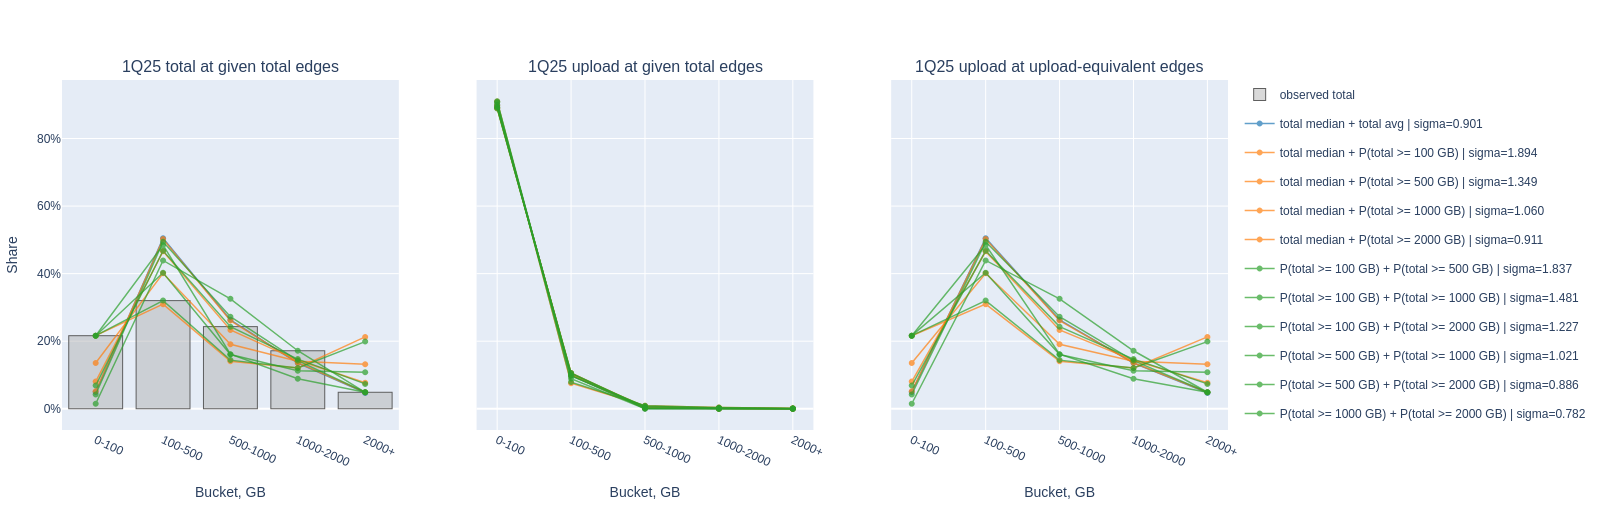

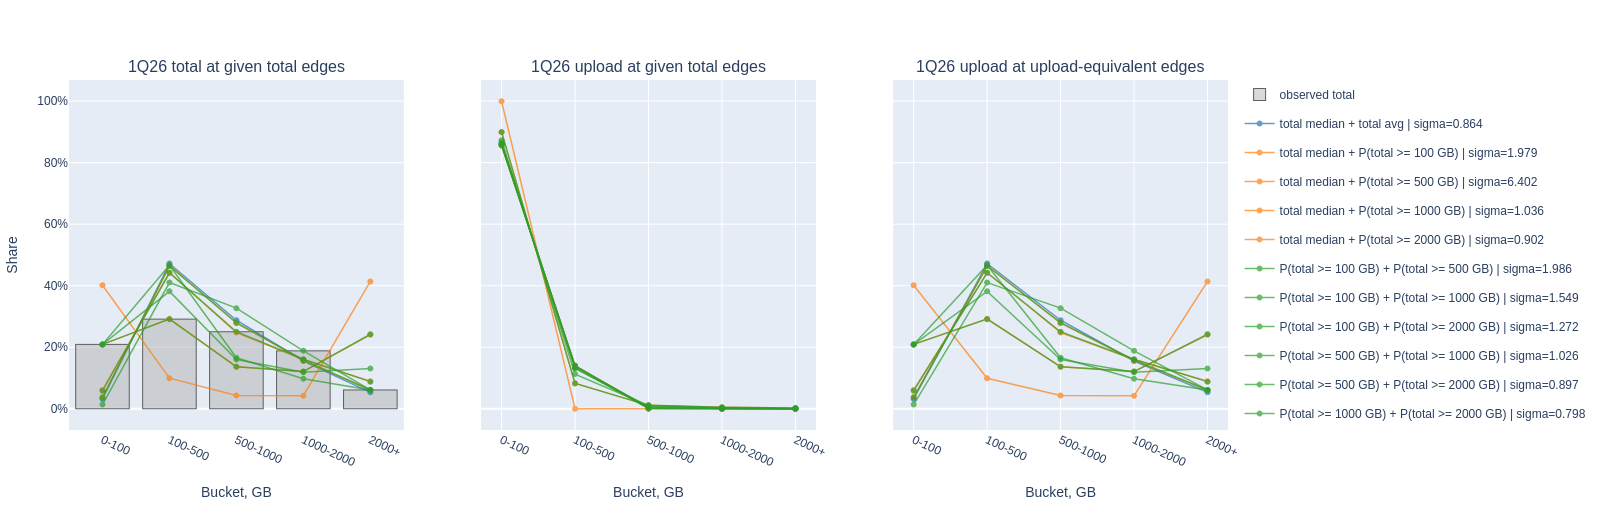

In [24]:
# Project each sigma candidate into total and upload distributions.
# Total rows use the model location implied by the sigma source.
# Upload rows use the same sigma, centered on the upload average from 01_period_metrics.

import plotly.graph_objects as go
from plotly.subplots import make_subplots

source_bucket_edges = (
    allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]
    .query("access_type == @model_access_type and period in @sigma_candidates.period.unique()")
    .sort_values(["period", "usage_lower_gb"])
    .copy()
)

source_bucket_edges["bucket_order"] = source_bucket_edges.groupby("period").cumcount()
source_bucket_edges["source_bucket_label"] = source_bucket_edges.apply(
    lambda r: f"{r['usage_lower_gb']:g}+" if np.isinf(r["usage_upper_gb"]) else f"{r['usage_lower_gb']:g}-{r['usage_upper_gb']:g}",
    axis=1,
)

def _lognormal_cdf(x, mu, sigma):
    if x <= 0:
        return 0.0
    if np.isposinf(x):
        return 1.0
    return nd.cdf((math.log(x) - mu) / sigma)

def _lognormal_tail(x, mu, sigma):
    return 1.0 - _lognormal_cdf(x, mu, sigma)

def _lognormal_bin_share(lower, upper, mu, sigma):
    return _lognormal_cdf(upper, mu, sigma) - _lognormal_cdf(lower, mu, sigma)

def _lognormal_mean(mu, sigma):
    return math.exp(mu + sigma * sigma / 2)

def _edge_to_matching_upload_quantile(edge, total_mu, upload_mu, sigma):
    if edge <= 0:
        return 0.0
    if np.isposinf(edge):
        return np.inf
    z = (math.log(edge) - total_mu) / sigma
    return math.exp(upload_mu + sigma * z)

def _edge_label(lower, upper):
    def fmt(x):
        if np.isposinf(x):
            return "inf"
        if x >= 100:
            return f"{x:,.0f}"
        return f"{x:.1f}".rstrip("0").rstrip(".")
    if np.isposinf(upper):
        return f"{fmt(lower)}+"
    return f"{fmt(lower)}-{fmt(upper)}"

projection_rows = []

for _, candidate in sigma_candidates.iterrows():
    sigma = candidate["sigma"]
    total_mu = candidate["total_mu_model"]
    total_mean = _lognormal_mean(total_mu, sigma)
    upload_mean = candidate["source_upload_avg_gb"]
    upload_mu = math.log(upload_mean) - sigma * sigma / 2
    upload_median = math.exp(upload_mu)

    period_edges = source_bucket_edges[source_bucket_edges["period"].eq(candidate["period"])]

    for _, bucket in period_edges.iterrows():
        lower = bucket["usage_lower_gb"]
        upper = bucket["usage_upper_gb"]
        source_label = bucket["source_bucket_label"]

        total_share = _lognormal_bin_share(lower, upper, total_mu, sigma)
        upload_share_at_total_edges = _lognormal_bin_share(lower, upper, upload_mu, sigma)
        upload_lower_equiv = _edge_to_matching_upload_quantile(lower, total_mu, upload_mu, sigma)
        upload_upper_equiv = _edge_to_matching_upload_quantile(upper, total_mu, upload_mu, sigma)
        upload_share_at_equiv_edges = _lognormal_bin_share(upload_lower_equiv, upload_upper_equiv, upload_mu, sigma)

        base = {
            "period": candidate["period"],
            "method": candidate["method"],
            "sigma_source": candidate["sigma_source"],
            "sigma": sigma,
            "bucket_order": bucket["bucket_order"],
            "source_bucket_label": source_label,
            "source_total_lower_gb": lower,
            "source_total_upper_gb": upper,
        }

        projection_rows.append(
            {
                **base,
                "direction": "total",
                "edge_set": "given_total_edges",
                "edge_lower_gb": lower,
                "edge_upper_gb": upper,
                "edge_label": source_label,
                "model_share": total_share,
                "observed_share": bucket["share"],
                "share_error": total_share - bucket["share"],
                "source_avg_gb": candidate["source_total_avg_gb"],
                "model_avg_gb": total_mean,
                "avg_error_gb": total_mean - candidate["source_total_avg_gb"],
                "avg_error_pct": (total_mean - candidate["source_total_avg_gb"]) / candidate["source_total_avg_gb"],
                "model_median_gb": math.exp(total_mu),
            }
        )

        projection_rows.append(
            {
                **base,
                "direction": "upload",
                "edge_set": "given_total_edges",
                "edge_lower_gb": lower,
                "edge_upper_gb": upper,
                "edge_label": source_label,
                "model_share": upload_share_at_total_edges,
                "observed_share": np.nan,
                "share_error": np.nan,
                "source_avg_gb": upload_mean,
                "model_avg_gb": upload_mean,
                "avg_error_gb": 0.0,
                "avg_error_pct": 0.0,
                "model_median_gb": upload_median,
            }
        )

        projection_rows.append(
            {
                **base,
                "direction": "upload",
                "edge_set": "upload_equiv_edges",
                "edge_lower_gb": upload_lower_equiv,
                "edge_upper_gb": upload_upper_equiv,
                "edge_label": _edge_label(upload_lower_equiv, upload_upper_equiv),
                "model_share": upload_share_at_equiv_edges,
                "observed_share": np.nan,
                "share_error": np.nan,
                "source_avg_gb": upload_mean,
                "model_avg_gb": upload_mean,
                "avg_error_gb": 0.0,
                "avg_error_pct": 0.0,
                "model_median_gb": upload_median,
            }
        )

projection_table = pd.DataFrame(projection_rows)
projection_table["abs_share_error"] = projection_table["share_error"].abs()

error_summary = (
    projection_table.query("direction == 'total' and edge_set == 'given_total_edges'")
    .groupby(["period", "method", "sigma_source", "sigma"], dropna=False, as_index=False)
    .agg(
        total_bucket_mae=("abs_share_error", "mean"),
        total_bucket_rmse=("share_error", lambda s: math.sqrt(np.mean(np.square(s)))),
        total_bucket_max_abs_error=("abs_share_error", "max"),
        total_avg_model_gb=("model_avg_gb", "first"),
        total_avg_source_gb=("source_avg_gb", "first"),
        total_avg_error_gb=("avg_error_gb", "first"),
        total_avg_error_pct=("avg_error_pct", "first"),
    )
)

upload_summary = (
    projection_table.query("direction == 'upload' and edge_set == 'upload_equiv_edges'")
    .groupby(["period", "method", "sigma_source", "sigma"], dropna=False, as_index=False)
    .agg(
        upload_avg_model_gb=("model_avg_gb", "first"),
        upload_avg_source_gb=("source_avg_gb", "first"),
        upload_avg_error_gb=("avg_error_gb", "first"),
        upload_avg_error_pct=("avg_error_pct", "first"),
        upload_median_model_gb=("model_median_gb", "first"),
    )
)

candidate_error_summary = (
    error_summary.merge(
        upload_summary,
        on=["period", "method", "sigma_source", "sigma"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["period", "total_bucket_rmse", "total_avg_error_pct"], key=lambda s: s.abs() if s.name.endswith("pct") else s)
    .reset_index(drop=True)
)

projection_display_cols = [
    "period",
    "method",
    "sigma_source",
    "direction",
    "edge_set",
    "source_bucket_label",
    "edge_label",
    "model_share",
    "observed_share",
    "share_error",
    "source_avg_gb",
    "model_avg_gb",
    "avg_error_gb",
    "avg_error_pct",
]

summary_display_cols = [
    "period",
    "method",
    "sigma_source",
    "sigma",
    "total_bucket_mae",
    "total_bucket_rmse",
    "total_bucket_max_abs_error",
    "total_avg_source_gb",
    "total_avg_model_gb",
    "total_avg_error_gb",
    "total_avg_error_pct",
    "upload_avg_source_gb",
    "upload_avg_model_gb",
    "upload_avg_error_gb",
    "upload_avg_error_pct",
    "upload_median_model_gb",
]

print("Candidate error summary")
display(
    candidate_error_summary[summary_display_cols]
    .style.format(
        {
            "sigma": "{:.4f}",
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_source_gb": "{:.2f}",
            "total_avg_model_gb": "{:.2f}",
            "total_avg_error_gb": "{:+.2f}",
            "total_avg_error_pct": "{:+.2%}",
            "upload_avg_source_gb": "{:.2f}",
            "upload_avg_model_gb": "{:.2f}",
            "upload_avg_error_gb": "{:+.2f}",
            "upload_avg_error_pct": "{:+.2%}",
            "upload_median_model_gb": "{:.2f}",
        }
    )
)

print("Bucket projection table")
display(
    projection_table
    .sort_values(["period", "method", "sigma_source", "direction", "edge_set", "bucket_order"])
    [projection_display_cols]
    .style.format(
        {
            "model_share": "{:.3%}",
            "observed_share": "{:.3%}",
            "share_error": "{:+.3%}",
            "source_avg_gb": "{:.2f}",
            "model_avg_gb": "{:.2f}",
            "avg_error_gb": "{:+.2f}",
            "avg_error_pct": "{:+.2%}",
        },
        na_rep="",
    )
)

print("Upload-equivalent bucket edges")
upload_equiv_edges = projection_table.query("direction == 'upload' and edge_set == 'upload_equiv_edges'").copy()
display(
    upload_equiv_edges
    .sort_values(["period", "method", "sigma_source", "bucket_order"])
    [
        [
            "period",
            "method",
            "sigma_source",
            "source_bucket_label",
            "edge_label",
            "edge_lower_gb",
            "edge_upper_gb",
            "model_share",
        ]
    ]
    .style.format(
        {
            "edge_lower_gb": "{:.2f}",
            "edge_upper_gb": "{:.2f}",
            "model_share": "{:.3%}",
        },
        na_rep="inf",
    )
)

# Sanity check against the exceedance/cumulative table where exact-period overall/DOCSIS rows exist.
exceedance_source = allTbls["03_usage_buckets_total_distribution_exceedance"].copy()
exceedance_source = exceedance_source.rename(columns={"usage_lower_gb.1": "usage_upper_gb"})
exceedance_source["mapped_access_type"] = np.where(
    exceedance_source["access_type"].eq("overall"),
    model_access_type,
    exceedance_source["access_type"],
)

exceedance_rows = []
for _, candidate in sigma_candidates.iterrows():
    exact_rows = exceedance_source[
        (exceedance_source["period"].eq(candidate["period"]))
        & (exceedance_source["mapped_access_type"].eq(model_access_type))
    ]
    for _, row in exact_rows.iterrows():
        model_tail = _lognormal_tail(row["usage_lower_gb"], candidate["total_mu_model"], candidate["sigma"])
        exceedance_rows.append(
            {
                "period": candidate["period"],
                "method": candidate["method"],
                "sigma_source": candidate["sigma_source"],
                "threshold_gb": row["usage_lower_gb"],
                "observed_exceedance": row["share"],
                "model_exceedance": model_tail,
                "exceedance_error": model_tail - row["share"],
            }
        )

exceedance_sanity = pd.DataFrame(exceedance_rows)
if exceedance_sanity.empty:
    print("No exact-period overall/DOCSIS rows in 03_usage_buckets_total_distribution_exceedance for the modeled periods.")
    print("Available 03 overall periods/thresholds for manual context:")
    display(
        exceedance_source.query("access_type == 'overall'")
        [["period", "source_ref", "access_type", "usage_lower_gb", "share"]]
        .sort_values(["period", "usage_lower_gb"])
    )
else:
    display(
        exceedance_sanity.style.format(
            {
                "threshold_gb": "{:.0f}",
                "observed_exceedance": "{:.3%}",
                "model_exceedance": "{:.3%}",
                "exceedance_error": "{:+.3%}",
            }
        )
    )

# Plots: total uses the given total bucket edges; upload is shown both at those same GB edges
# and at the upload-equivalent edges mapped from each candidate's total quantiles.
method_colors = {
    "median_mean": "#1f77b4",
    "median_one_point": "#ff7f0e",
    "two_point": "#2ca02c",
}

for period in sigma_candidates["period"].drop_duplicates():
    period_projection = projection_table[projection_table["period"].eq(period)].copy()
    period_buckets = source_bucket_edges[source_bucket_edges["period"].eq(period)].sort_values("bucket_order")
    x_labels = period_buckets["source_bucket_label"].tolist()

    fig = make_subplots(
        rows=1,
        cols=3,
        shared_yaxes=True,
        subplot_titles=(
            f"{period} total at given total edges",
            f"{period} upload at given total edges",
            f"{period} upload at upload-equivalent edges",
        ),
    )

    fig.add_trace(
        go.Bar(
            x=x_labels,
            y=period_buckets["share"],
            name="observed total",
            marker_color="rgba(170,170,170,0.45)",
            marker_line_color="rgba(80,80,80,0.9)",
            marker_line_width=1,
        ),
        row=1,
        col=1,
    )

    for _, candidate in sigma_candidates[sigma_candidates["period"].eq(period)].iterrows():
        label = f"{candidate['sigma_source']} | sigma={candidate['sigma']:.3f}"
        color = method_colors.get(candidate["method"], "#444444")

        selector = (
            period_projection["method"].eq(candidate["method"])
            & period_projection["sigma_source"].eq(candidate["sigma_source"])
            & period_projection["direction"].eq("total")
            & period_projection["edge_set"].eq("given_total_edges")
        )
        y_total = period_projection[selector].sort_values("bucket_order")["model_share"]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=y_total,
                mode="lines+markers",
                name=label,
                legendgroup=label,
                line={"color": color, "width": 1.5},
                marker={"size": 6},
                opacity=0.7,
            ),
            row=1,
            col=1,
        )

        selector = (
            period_projection["method"].eq(candidate["method"])
            & period_projection["sigma_source"].eq(candidate["sigma_source"])
            & period_projection["direction"].eq("upload")
            & period_projection["edge_set"].eq("given_total_edges")
        )
        y_upload_total_edges = period_projection[selector].sort_values("bucket_order")["model_share"]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=y_upload_total_edges,
                mode="lines+markers",
                name=label,
                legendgroup=label,
                showlegend=False,
                line={"color": color, "width": 1.5},
                marker={"size": 6},
                opacity=0.7,
            ),
            row=1,
            col=2,
        )

        selector = (
            period_projection["method"].eq(candidate["method"])
            & period_projection["sigma_source"].eq(candidate["sigma_source"])
            & period_projection["direction"].eq("upload")
            & period_projection["edge_set"].eq("upload_equiv_edges")
        )
        y_upload_equiv_edges = period_projection[selector].sort_values("bucket_order")["model_share"]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=y_upload_equiv_edges,
                mode="lines+markers",
                name=label,
                legendgroup=label,
                showlegend=False,
                line={"color": color, "width": 1.5},
                marker={"size": 6},
                opacity=0.7,
            ),
            row=1,
            col=3,
        )

    fig.update_yaxes(title_text="Share", tickformat=".0%", row=1, col=1)
    fig.update_yaxes(tickformat=".0%", row=1, col=2)
    fig.update_yaxes(tickformat=".0%", row=1, col=3)
    fig.update_xaxes(title_text="Bucket, GB", tickangle=25)
    fig.update_layout(
        height=520,
        width=1450,
        legend={"orientation": "v", "x": 1.01, "y": 1.0},
        margin={"l": 60, "r": 360, "t": 80, "b": 90},
        hovermode="x unified",
    )
    fig.show()

Weibull candidate fits


,period,method,shape_source,shape_k,total_scale_lambda,total_median_model_gb,total_mean_model_gb,source_total_avg_gb,total_avg_error_gb,total_avg_error_pct,source_upload_avg_gb
0,1Q25,median_mean,total median + total avg,0.9535,649.17,442.00,663.20,663.20,-0.00,-0.00%,47.50
1,1Q25,median_one_point,total median + P(total >= 100 GB),0.7033,744.31,442.00,937.98,663.20,+274.78,+41.43%,47.50
2,1Q25,median_one_point,total median + P(total >= 500 GB),0.8394,683.98,442.00,750.05,663.20,+86.85,+13.10%,47.50
3,1Q25,median_one_point,total median + P(total >= 1000 GB),0.9552,648.73,442.00,662.20,663.20,-1.00,-0.15%,47.50
4,1Q25,median_one_point,total median + P(total >= 2000 GB),0.9750,643.70,442.00,650.87,663.20,-12.33,-1.86%,47.50
5,1Q25,two_point,P(total >= 100 GB) + P(total >= 500 GB),0.7137,722.79,432.50,898.48,663.20,+235.28,+35.48%,47.50
6,1Q25,two_point,P(total >= 100 GB) + P(total >= 1000 GB),0.7926,593.63,373.85,677.12,663.20,+13.92,+2.10%,47.50
7,1Q25,two_point,P(total >= 100 GB) + P(total >= 2000 GB),0.8402,536.68,346.95,588.19,663.20,-75.01,-11.31%,47.50
8,1Q25,two_point,P(total >= 500 GB) + P(total >= 1000 GB),0.9758,654.68,449.68,661.72,663.20,-1.48,-0.22%,47.50
9,1Q25,two_point,P(total >= 500 GB) + P(total >= 2000 GB),0.9870,652.68,450.22,656.36,663.20,-6.84,-1.03%,47.50


Weibull candidate error summary


,period,method,shape_source,shape_k,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_source_gb,total_avg_model_gb,total_avg_error_gb,total_avg_error_pct,upload_avg_source_gb,upload_avg_model_gb,upload_avg_error_gb,upload_avg_error_pct,upload_median_model_gb
0,1Q25,median_one_point,total median + P(total >= 500 GB),0.8394,2.892%,3.147%,3.652%,663.20,750.05,+86.85,+13.10%,47.50,47.50,+0.00,+0.00%,27.99
1,1Q25,two_point,P(total >= 100 GB) + P(total >= 1000 GB),0.7926,2.796%,3.274%,4.582%,663.20,677.12,+13.92,+2.10%,47.50,47.50,+0.00,+0.00%,26.23
2,1Q25,two_point,P(total >= 100 GB) + P(total >= 2000 GB),0.8402,2.954%,4.046%,7.385%,663.20,588.19,-75.01,-11.31%,47.50,47.50,+0.00,+0.00%,28.02
3,1Q25,median_mean,total median + total avg,0.9535,2.863%,4.077%,6.664%,663.20,663.20,-0.00,-0.00%,47.50,47.50,+0.00,+0.00%,31.66
4,1Q25,median_one_point,total median + P(total >= 1000 GB),0.9552,2.864%,4.100%,6.707%,663.20,662.20,-1.00,-0.15%,47.50,47.50,+0.00,+0.00%,31.71
5,1Q25,two_point,P(total >= 500 GB) + P(total >= 1000 GB),0.9758,2.836%,4.339%,6.856%,663.20,661.72,-1.48,-0.22%,47.50,47.50,+0.00,+0.00%,32.28
6,1Q25,median_one_point,total median + P(total >= 2000 GB),0.9750,2.882%,4.379%,7.205%,663.20,650.87,-12.33,-1.86%,47.50,47.50,+0.00,+0.00%,32.26
7,1Q25,two_point,P(total >= 500 GB) + P(total >= 2000 GB),0.9870,2.944%,4.494%,7.101%,663.20,656.36,-6.84,-1.03%,47.50,47.50,+0.00,+0.00%,32.58
8,1Q25,two_point,P(total >= 100 GB) + P(total >= 500 GB),0.7137,3.107%,4.520%,7.768%,663.20,898.48,+235.28,+35.48%,47.50,47.50,+0.00,+0.00%,22.87
9,1Q25,two_point,P(total >= 1000 GB) + P(total >= 2000 GB),0.9982,3.018%,4.607%,7.546%,663.20,661.45,-1.75,-0.26%,47.50,47.50,+0.00,+0.00%,32.88


Weibull bucket projection table


,period,method,shape_source,direction,edge_set,source_bucket_label,edge_label,model_share,observed_share,share_error,source_avg_gb,model_avg_gb,avg_error_gb,avg_error_pct
0,1Q25,median_mean,total median + total avg,total,given_total_edges,0-100,0-100,15.468%,21.630%,-6.162%,663.20,663.20,-0.00,-0.00%
3,1Q25,median_mean,total median + total avg,total,given_total_edges,100-500,100-500,38.674%,32.010%,+6.664%,663.20,663.20,-0.00,-0.00%
6,1Q25,median_mean,total median + total avg,total,given_total_edges,500-1000,500-1000,23.762%,24.310%,-0.548%,663.20,663.20,-0.00,-0.00%
9,1Q25,median_mean,total median + total avg,total,given_total_edges,1000-2000,1000-2000,16.723%,17.170%,-0.447%,663.20,663.20,-0.00,-0.00%
12,1Q25,median_mean,total median + total avg,total,given_total_edges,2000+,2000+,5.373%,4.880%,+0.493%,663.20,663.20,-0.00,-0.00%
1,1Q25,median_mean,total median + total avg,upload,given_total_edges,0-100,0-100,87.451%,,,47.50,47.50,+0.00,+0.00%
4,1Q25,median_mean,total median + total avg,upload,given_total_edges,100-500,100-500,12.543%,,,47.50,47.50,+0.00,+0.00%
7,1Q25,median_mean,total median + total avg,upload,given_total_edges,500-1000,500-1000,0.007%,,,47.50,47.50,+0.00,+0.00%
10,1Q25,median_mean,total median + total avg,upload,given_total_edges,1000-2000,1000-2000,0.000%,,,47.50,47.50,+0.00,+0.00%
13,1Q25,median_mean,total median + total avg,upload,given_total_edges,2000+,2000+,0.000%,,,47.50,47.50,+0.00,+0.00%


... (2 outputs left out)

No exact-period overall/DOCSIS rows in 03_usage_buckets_total_distribution_exceedance for the modeled periods.
Available 03 overall periods/thresholds for manual context:


,period,source_ref,access_type,usage_lower_gb,share
0,3Q23,3Q25,overall,1000,0.1643
1,3Q23,3Q25,overall,2000,0.0289
2,3Q23,3Q25,overall,5000,0.0008
3,3Q24,3Q25,overall,1000,0.1860
4,3Q24,3Q25,overall,2000,0.0360
5,3Q24,3Q25,overall,5000,0.0011
6,3Q25,3Q25,overall,1000,0.2097
7,3Q25,3Q25,overall,2000,0.0441
8,3Q25,3Q25,overall,5000,0.0015
17,4Q18,4Q24,overall,1000,0.0400


Lognormal vs Weibull candidate error comparison


,model_family,period,method,shape_source,shape,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_error_gb,total_avg_error_pct,upload_median_model_gb
22,weibull,1Q25,median_one_point,total median + P(total >= 500 GB),0.8394,2.892%,3.147%,3.652%,+86.85,+13.10%,27.99
23,weibull,1Q25,two_point,P(total >= 100 GB) + P(total >= 1000 GB),0.7926,2.796%,3.274%,4.582%,+13.92,+2.10%,26.23
24,weibull,1Q25,two_point,P(total >= 100 GB) + P(total >= 2000 GB),0.8402,2.954%,4.046%,7.385%,-75.01,-11.31%,28.02
25,weibull,1Q25,median_mean,total median + total avg,0.9535,2.863%,4.077%,6.664%,-0.00,-0.00%,31.66
26,weibull,1Q25,median_one_point,total median + P(total >= 1000 GB),0.9552,2.864%,4.100%,6.707%,-1.00,-0.15%,31.71
27,weibull,1Q25,two_point,P(total >= 500 GB) + P(total >= 1000 GB),0.9758,2.836%,4.339%,6.856%,-1.48,-0.22%,32.28
28,weibull,1Q25,median_one_point,total median + P(total >= 2000 GB),0.9750,2.882%,4.379%,7.205%,-12.33,-1.86%,32.26
29,weibull,1Q25,two_point,P(total >= 500 GB) + P(total >= 2000 GB),0.9870,2.944%,4.494%,7.101%,-6.84,-1.03%,32.58
30,weibull,1Q25,two_point,P(total >= 100 GB) + P(total >= 500 GB),0.7137,3.107%,4.520%,7.768%,+235.28,+35.48%,22.87
31,weibull,1Q25,two_point,P(total >= 1000 GB) + P(total >= 2000 GB),0.9982,3.018%,4.607%,7.546%,-1.75,-0.26%,32.88


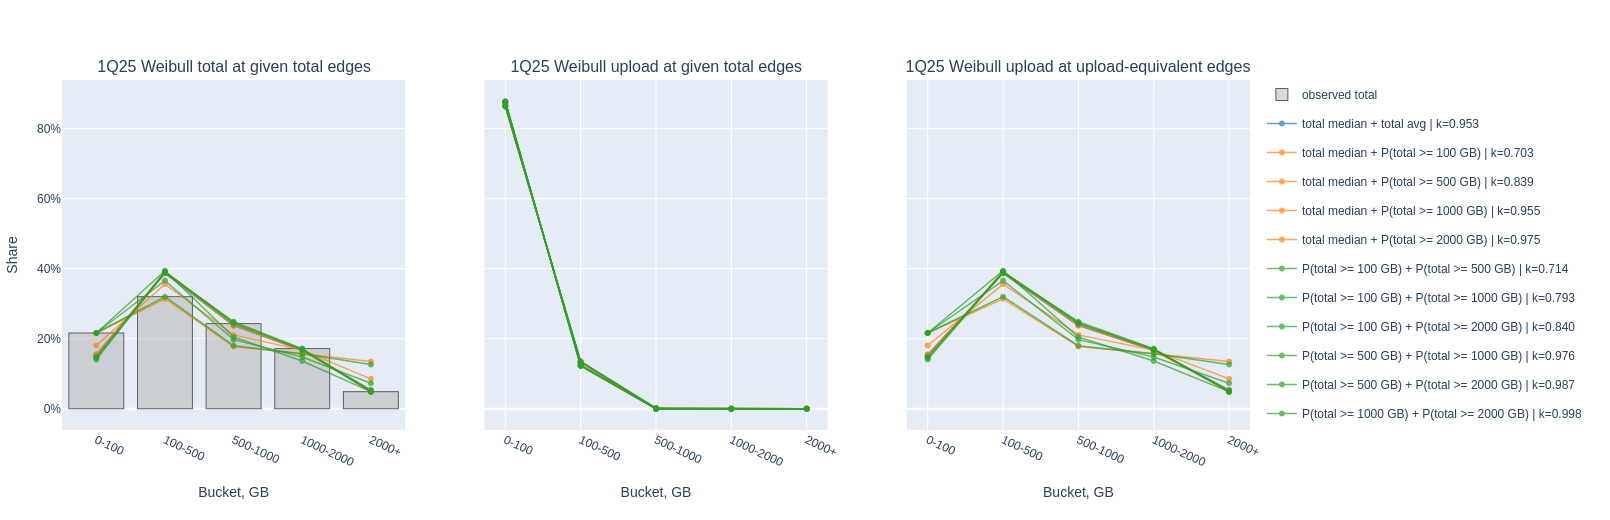

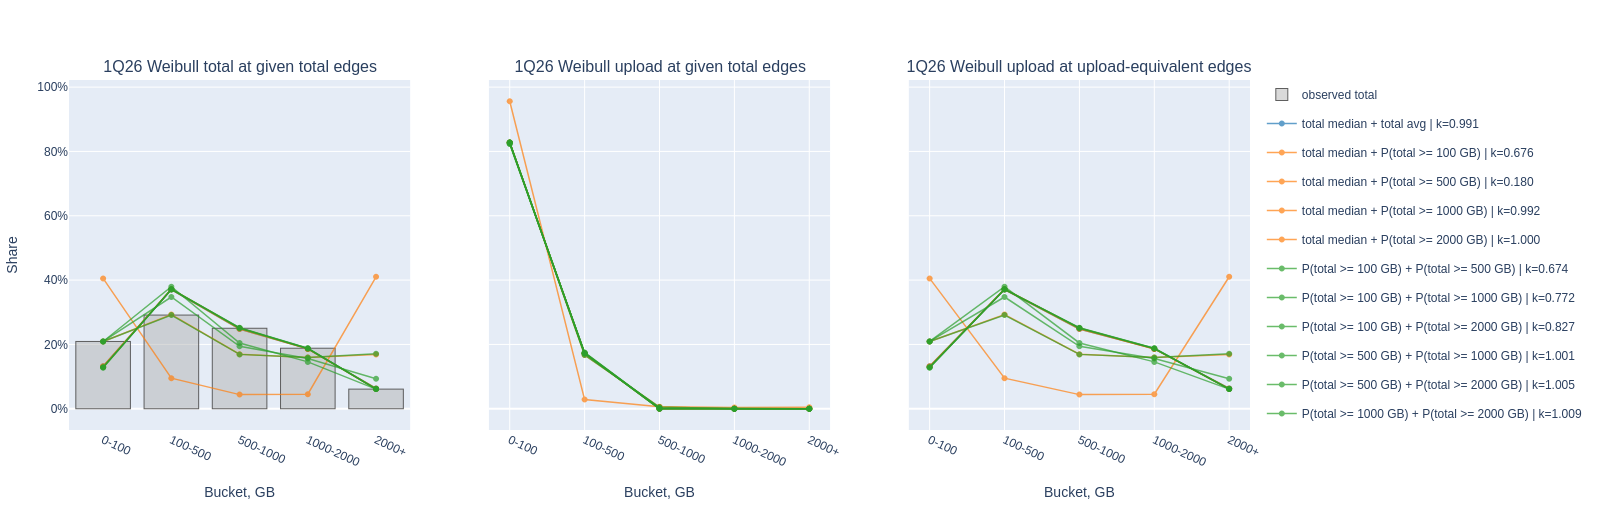

In [25]:
# Weibull candidate fits using the same sources as the lognormal section.
# Shape parameter k is projected from total usage into upload usage, with upload scale set by avg upload GB.

import math
from itertools import combinations

import plotly.graph_objects as go
from plotly.subplots import make_subplots

WEIBULL_LN2 = math.log(2.0)

def _weibull_cdf(x, scale_lambda, shape_k):
    if x <= 0:
        return 0.0
    if np.isposinf(x):
        return 1.0
    return 1.0 - math.exp(-((x / scale_lambda) ** shape_k))

def _weibull_tail(x, scale_lambda, shape_k):
    return 1.0 - _weibull_cdf(x, scale_lambda, shape_k)

def _weibull_bin_share(lower, upper, scale_lambda, shape_k):
    return _weibull_cdf(upper, scale_lambda, shape_k) - _weibull_cdf(lower, scale_lambda, shape_k)

def _weibull_mean(scale_lambda, shape_k):
    return scale_lambda * math.gamma(1.0 + 1.0 / shape_k)

def _weibull_median(scale_lambda, shape_k):
    return scale_lambda * (WEIBULL_LN2 ** (1.0 / shape_k))

def _weibull_scale_from_median(median_gb, shape_k):
    return median_gb / (WEIBULL_LN2 ** (1.0 / shape_k))

def _weibull_scale_from_mean(mean_gb, shape_k):
    return mean_gb / math.gamma(1.0 + 1.0 / shape_k)

def _weibull_shape_from_mean_median(mean_gb, median_gb, lo=0.05, hi=100.0):
    if mean_gb <= 0 or median_gb <= 0 or mean_gb < median_gb:
        return np.nan

    target_ratio = mean_gb / median_gb

    def ratio(shape_k):
        return math.gamma(1.0 + 1.0 / shape_k) / (WEIBULL_LN2 ** (1.0 / shape_k))

    # ratio(k) decreases from very large toward 1.0 as k grows.
    lo_val = ratio(lo)
    hi_val = ratio(hi)
    if not (hi_val <= target_ratio <= lo_val):
        return np.nan

    for _ in range(120):
        mid = (lo + hi) / 2.0
        mid_val = ratio(mid)
        if mid_val > target_ratio:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2.0

def _weibull_fit_from_median_and_exceedance(median_gb, lower_bound_gb, gt_share):
    if median_gb <= 0 or lower_bound_gb <= 0 or not (0.0 < gt_share < 1.0):
        return None

    denom = math.log(lower_bound_gb / median_gb)
    if abs(denom) < 1e-9:
        return None

    numerator_term = -math.log(gt_share) / WEIBULL_LN2
    if numerator_term <= 0:
        return None

    shape_k = math.log(numerator_term) / denom
    if shape_k <= 0 or not np.isfinite(shape_k):
        return None

    scale_lambda = _weibull_scale_from_median(median_gb, shape_k)
    mean_gb = _weibull_mean(scale_lambda, shape_k)
    return shape_k, scale_lambda, median_gb, mean_gb

def _weibull_fit_from_exceedance_points(lower_1, gt_share_1, lower_2, gt_share_2):
    if lower_1 <= 0 or lower_2 <= 0:
        return None
    if not (0.0 < gt_share_1 < 1.0 and 0.0 < gt_share_2 < 1.0):
        return None

    log_neglog_1 = math.log(-math.log(gt_share_1))
    log_neglog_2 = math.log(-math.log(gt_share_2))
    denom = math.log(lower_2) - math.log(lower_1)
    if abs(denom) < 1e-9:
        return None

    shape_k = (log_neglog_2 - log_neglog_1) / denom
    if shape_k <= 0 or not np.isfinite(shape_k):
        return None

    scale_lambda = lower_1 / ((-math.log(gt_share_1)) ** (1.0 / shape_k))
    if scale_lambda <= 0 or not np.isfinite(scale_lambda):
        return None

    median_gb = _weibull_median(scale_lambda, shape_k)
    mean_gb = _weibull_mean(scale_lambda, shape_k)
    return shape_k, scale_lambda, median_gb, mean_gb

def _weibull_edge_to_matching_upload_quantile(edge, total_scale_lambda, upload_scale_lambda):
    if edge <= 0:
        return 0.0
    if np.isposinf(edge):
        return np.inf
    return edge * upload_scale_lambda / total_scale_lambda

def _weibull_edge_label(lower, upper):
    def fmt(x):
        if np.isposinf(x):
            return "inf"
        if x >= 100:
            return f"{x:,.0f}"
        return f"{x:.1f}".rstrip("0").rstrip(".")
    if np.isposinf(upper):
        return f"{fmt(lower)}+"
    return f"{fmt(lower)}-{fmt(upper)}"

weibull_candidate_rows = []
metrics = allTbls["01_period_metrics"].copy()

for period, period_edges in export.groupby("period", sort=True):
    period_edges = period_edges.sort_values("lower").reset_index(drop=True)
    total_avg = _metric_value(metrics, period, "total", "avg")
    total_median = _metric_value(metrics, period, "total", "median")
    upload_avg = _metric_value(metrics, period, "up", "avg")

    shape_mean_median = _weibull_shape_from_mean_median(total_avg, total_median)
    if np.isfinite(shape_mean_median):
        scale_lambda = _weibull_scale_from_median(total_median, shape_mean_median)
        weibull_candidate_rows.append(
            {
                "period": period,
                "access_type": model_access_type,
                "method": "median_mean",
                "shape_source": "total median + total avg",
                "source_edge_1_gb": np.nan,
                "source_edge_2_gb": np.nan,
                "source_tail_1": np.nan,
                "source_tail_2": np.nan,
                "shape_k": shape_mean_median,
                "total_scale_lambda": scale_lambda,
                "total_median_model_gb": total_median,
                "total_mean_model_gb": _weibull_mean(scale_lambda, shape_mean_median),
                "source_total_median_gb": total_median,
                "source_total_avg_gb": total_avg,
                "source_upload_avg_gb": upload_avg,
                "method_order": 1,
            }
        )

    for _, edge in period_edges.iterrows():
        fit = _weibull_fit_from_median_and_exceedance(total_median, edge["lower"], edge["gt_share"])
        if fit is None:
            continue
        shape_k, scale_lambda, median_gb, mean_gb = fit
        weibull_candidate_rows.append(
            {
                "period": period,
                "access_type": model_access_type,
                "method": "median_one_point",
                "shape_source": f"total median + P(total >= {edge['lower']:g} GB)",
                "source_edge_1_gb": edge["lower"],
                "source_edge_2_gb": np.nan,
                "source_tail_1": edge["gt_share"],
                "source_tail_2": np.nan,
                "shape_k": shape_k,
                "total_scale_lambda": scale_lambda,
                "total_median_model_gb": median_gb,
                "total_mean_model_gb": mean_gb,
                "source_total_median_gb": total_median,
                "source_total_avg_gb": total_avg,
                "source_upload_avg_gb": upload_avg,
                "method_order": 2,
            }
        )

    exceedance_points = period_edges[
        (period_edges["lower"] > 0)
        & (period_edges["gt_share"] > 0)
        & (period_edges["gt_share"] < 1)
    ].copy()

    for (_, edge_1), (_, edge_2) in combinations(exceedance_points.iterrows(), 2):
        fit = _weibull_fit_from_exceedance_points(
            edge_1["lower"],
            edge_1["gt_share"],
            edge_2["lower"],
            edge_2["gt_share"],
        )
        if fit is None:
            continue
        shape_k, scale_lambda, median_gb, mean_gb = fit
        weibull_candidate_rows.append(
            {
                "period": period,
                "access_type": model_access_type,
                "method": "two_point",
                "shape_source": f"P(total >= {edge_1['lower']:g} GB) + P(total >= {edge_2['lower']:g} GB)",
                "source_edge_1_gb": edge_1["lower"],
                "source_edge_2_gb": edge_2["lower"],
                "source_tail_1": edge_1["gt_share"],
                "source_tail_2": edge_2["gt_share"],
                "shape_k": shape_k,
                "total_scale_lambda": scale_lambda,
                "total_median_model_gb": median_gb,
                "total_mean_model_gb": mean_gb,
                "source_total_median_gb": total_median,
                "source_total_avg_gb": total_avg,
                "source_upload_avg_gb": upload_avg,
                "method_order": 3,
            }
        )

weibull_candidates = pd.DataFrame(weibull_candidate_rows)
weibull_candidates["total_avg_error_gb"] = weibull_candidates["total_mean_model_gb"] - weibull_candidates["source_total_avg_gb"]
weibull_candidates["total_avg_error_pct"] = weibull_candidates["total_avg_error_gb"] / weibull_candidates["source_total_avg_gb"]
weibull_candidates["abs_total_avg_error_pct"] = weibull_candidates["total_avg_error_pct"].abs()

weibull_candidates = weibull_candidates.sort_values(
    ["period", "method_order", "source_edge_1_gb", "source_edge_2_gb"],
    na_position="first",
).reset_index(drop=True)

weibull_candidate_display_cols = [
    "period",
    "method",
    "shape_source",
    "shape_k",
    "total_scale_lambda",
    "total_median_model_gb",
    "total_mean_model_gb",
    "source_total_avg_gb",
    "total_avg_error_gb",
    "total_avg_error_pct",
    "source_upload_avg_gb",
]

print("Weibull candidate fits")
display(
    weibull_candidates[weibull_candidate_display_cols]
    .style.format(
        {
            "shape_k": "{:.4f}",
            "total_scale_lambda": "{:.2f}",
            "total_median_model_gb": "{:.2f}",
            "total_mean_model_gb": "{:.2f}",
            "source_total_avg_gb": "{:.2f}",
            "total_avg_error_gb": "{:+.2f}",
            "total_avg_error_pct": "{:+.2%}",
            "source_upload_avg_gb": "{:.2f}",
        }
    )
)

weibull_source_bucket_edges = (
    allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]
    .query("access_type == @model_access_type and period in @weibull_candidates.period.unique()")
    .sort_values(["period", "usage_lower_gb"])
    .copy()
)

weibull_source_bucket_edges["bucket_order"] = weibull_source_bucket_edges.groupby("period").cumcount()
weibull_source_bucket_edges["source_bucket_label"] = weibull_source_bucket_edges.apply(
    lambda r: f"{r['usage_lower_gb']:g}+" if np.isinf(r["usage_upper_gb"]) else f"{r['usage_lower_gb']:g}-{r['usage_upper_gb']:g}",
    axis=1,
)

weibull_projection_rows = []

for _, candidate in weibull_candidates.iterrows():
    shape_k = candidate["shape_k"]
    total_scale_lambda = candidate["total_scale_lambda"]
    total_mean = _weibull_mean(total_scale_lambda, shape_k)
    upload_mean = candidate["source_upload_avg_gb"]
    upload_scale_lambda = _weibull_scale_from_mean(upload_mean, shape_k)
    upload_median = _weibull_median(upload_scale_lambda, shape_k)

    period_edges = weibull_source_bucket_edges[weibull_source_bucket_edges["period"].eq(candidate["period"])]

    for _, bucket in period_edges.iterrows():
        lower = bucket["usage_lower_gb"]
        upper = bucket["usage_upper_gb"]
        source_label = bucket["source_bucket_label"]

        total_share = _weibull_bin_share(lower, upper, total_scale_lambda, shape_k)
        upload_share_at_total_edges = _weibull_bin_share(lower, upper, upload_scale_lambda, shape_k)
        upload_lower_equiv = _weibull_edge_to_matching_upload_quantile(lower, total_scale_lambda, upload_scale_lambda)
        upload_upper_equiv = _weibull_edge_to_matching_upload_quantile(upper, total_scale_lambda, upload_scale_lambda)
        upload_share_at_equiv_edges = _weibull_bin_share(upload_lower_equiv, upload_upper_equiv, upload_scale_lambda, shape_k)

        base = {
            "period": candidate["period"],
            "method": candidate["method"],
            "shape_source": candidate["shape_source"],
            "shape_k": shape_k,
            "total_scale_lambda": total_scale_lambda,
            "upload_scale_lambda": upload_scale_lambda,
            "bucket_order": bucket["bucket_order"],
            "source_bucket_label": source_label,
            "source_total_lower_gb": lower,
            "source_total_upper_gb": upper,
        }

        weibull_projection_rows.append(
            {
                **base,
                "direction": "total",
                "edge_set": "given_total_edges",
                "edge_lower_gb": lower,
                "edge_upper_gb": upper,
                "edge_label": source_label,
                "model_share": total_share,
                "observed_share": bucket["share"],
                "share_error": total_share - bucket["share"],
                "source_avg_gb": candidate["source_total_avg_gb"],
                "model_avg_gb": total_mean,
                "avg_error_gb": total_mean - candidate["source_total_avg_gb"],
                "avg_error_pct": (total_mean - candidate["source_total_avg_gb"]) / candidate["source_total_avg_gb"],
                "model_median_gb": _weibull_median(total_scale_lambda, shape_k),
            }
        )

        weibull_projection_rows.append(
            {
                **base,
                "direction": "upload",
                "edge_set": "given_total_edges",
                "edge_lower_gb": lower,
                "edge_upper_gb": upper,
                "edge_label": source_label,
                "model_share": upload_share_at_total_edges,
                "observed_share": np.nan,
                "share_error": np.nan,
                "source_avg_gb": upload_mean,
                "model_avg_gb": upload_mean,
                "avg_error_gb": 0.0,
                "avg_error_pct": 0.0,
                "model_median_gb": upload_median,
            }
        )

        weibull_projection_rows.append(
            {
                **base,
                "direction": "upload",
                "edge_set": "upload_equiv_edges",
                "edge_lower_gb": upload_lower_equiv,
                "edge_upper_gb": upload_upper_equiv,
                "edge_label": _weibull_edge_label(upload_lower_equiv, upload_upper_equiv),
                "model_share": upload_share_at_equiv_edges,
                "observed_share": np.nan,
                "share_error": np.nan,
                "source_avg_gb": upload_mean,
                "model_avg_gb": upload_mean,
                "avg_error_gb": 0.0,
                "avg_error_pct": 0.0,
                "model_median_gb": upload_median,
            }
        )

weibull_projection_table = pd.DataFrame(weibull_projection_rows)
weibull_projection_table["abs_share_error"] = weibull_projection_table["share_error"].abs()

weibull_error_summary = (
    weibull_projection_table.query("direction == 'total' and edge_set == 'given_total_edges'")
    .groupby(["period", "method", "shape_source", "shape_k"], dropna=False, as_index=False)
    .agg(
        total_bucket_mae=("abs_share_error", "mean"),
        total_bucket_rmse=("share_error", lambda s: math.sqrt(np.mean(np.square(s)))),
        total_bucket_max_abs_error=("abs_share_error", "max"),
        total_avg_model_gb=("model_avg_gb", "first"),
        total_avg_source_gb=("source_avg_gb", "first"),
        total_avg_error_gb=("avg_error_gb", "first"),
        total_avg_error_pct=("avg_error_pct", "first"),
    )
)

weibull_upload_summary = (
    weibull_projection_table.query("direction == 'upload' and edge_set == 'upload_equiv_edges'")
    .groupby(["period", "method", "shape_source", "shape_k"], dropna=False, as_index=False)
    .agg(
        upload_avg_model_gb=("model_avg_gb", "first"),
        upload_avg_source_gb=("source_avg_gb", "first"),
        upload_avg_error_gb=("avg_error_gb", "first"),
        upload_avg_error_pct=("avg_error_pct", "first"),
        upload_median_model_gb=("model_median_gb", "first"),
    )
)

weibull_candidate_error_summary = (
    weibull_error_summary.merge(
        weibull_upload_summary,
        on=["period", "method", "shape_source", "shape_k"],
        how="left",
        validate="one_to_one",
    )
    .sort_values(["period", "total_bucket_rmse", "total_avg_error_pct"], key=lambda s: s.abs() if s.name.endswith("pct") else s)
    .reset_index(drop=True)
)

weibull_projection_display_cols = [
    "period",
    "method",
    "shape_source",
    "direction",
    "edge_set",
    "source_bucket_label",
    "edge_label",
    "model_share",
    "observed_share",
    "share_error",
    "source_avg_gb",
    "model_avg_gb",
    "avg_error_gb",
    "avg_error_pct",
]

weibull_summary_display_cols = [
    "period",
    "method",
    "shape_source",
    "shape_k",
    "total_bucket_mae",
    "total_bucket_rmse",
    "total_bucket_max_abs_error",
    "total_avg_source_gb",
    "total_avg_model_gb",
    "total_avg_error_gb",
    "total_avg_error_pct",
    "upload_avg_source_gb",
    "upload_avg_model_gb",
    "upload_avg_error_gb",
    "upload_avg_error_pct",
    "upload_median_model_gb",
]

print("Weibull candidate error summary")
display(
    weibull_candidate_error_summary[weibull_summary_display_cols]
    .style.format(
        {
            "shape_k": "{:.4f}",
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_source_gb": "{:.2f}",
            "total_avg_model_gb": "{:.2f}",
            "total_avg_error_gb": "{:+.2f}",
            "total_avg_error_pct": "{:+.2%}",
            "upload_avg_source_gb": "{:.2f}",
            "upload_avg_model_gb": "{:.2f}",
            "upload_avg_error_gb": "{:+.2f}",
            "upload_avg_error_pct": "{:+.2%}",
            "upload_median_model_gb": "{:.2f}",
        }
    )
)

print("Weibull bucket projection table")
display(
    weibull_projection_table
    .sort_values(["period", "method", "shape_source", "direction", "edge_set", "bucket_order"])
    [weibull_projection_display_cols]
    .style.format(
        {
            "model_share": "{:.3%}",
            "observed_share": "{:.3%}",
            "share_error": "{:+.3%}",
            "source_avg_gb": "{:.2f}",
            "model_avg_gb": "{:.2f}",
            "avg_error_gb": "{:+.2f}",
            "avg_error_pct": "{:+.2%}",
        },
        na_rep="",
    )
)

print("Weibull upload-equivalent bucket edges")
weibull_upload_equiv_edges = weibull_projection_table.query("direction == 'upload' and edge_set == 'upload_equiv_edges'").copy()
display(
    weibull_upload_equiv_edges
    .sort_values(["period", "method", "shape_source", "bucket_order"])
    [
        [
            "period",
            "method",
            "shape_source",
            "source_bucket_label",
            "edge_label",
            "edge_lower_gb",
            "edge_upper_gb",
            "model_share",
        ]
    ]
    .style.format(
        {
            "edge_lower_gb": "{:.2f}",
            "edge_upper_gb": "{:.2f}",
            "model_share": "{:.3%}",
        },
        na_rep="inf",
    )
)

# Sanity check against the exceedance/cumulative table where exact-period overall/DOCSIS rows exist.
weibull_exceedance_rows = []
for _, candidate in weibull_candidates.iterrows():
    exact_rows = exceedance_source[
        (exceedance_source["period"].eq(candidate["period"]))
        & (exceedance_source["mapped_access_type"].eq(model_access_type))
    ]
    for _, row in exact_rows.iterrows():
        model_tail = _weibull_tail(row["usage_lower_gb"], candidate["total_scale_lambda"], candidate["shape_k"])
        weibull_exceedance_rows.append(
            {
                "period": candidate["period"],
                "method": candidate["method"],
                "shape_source": candidate["shape_source"],
                "threshold_gb": row["usage_lower_gb"],
                "observed_exceedance": row["share"],
                "model_exceedance": model_tail,
                "exceedance_error": model_tail - row["share"],
            }
        )

weibull_exceedance_sanity = pd.DataFrame(weibull_exceedance_rows)
if weibull_exceedance_sanity.empty:
    print("No exact-period overall/DOCSIS rows in 03_usage_buckets_total_distribution_exceedance for the modeled periods.")
    print("Available 03 overall periods/thresholds for manual context:")
    display(
        exceedance_source.query("access_type == 'overall'")
        [["period", "source_ref", "access_type", "usage_lower_gb", "share"]]
        .sort_values(["period", "usage_lower_gb"])
    )
else:
    display(
        weibull_exceedance_sanity.style.format(
            {
                "threshold_gb": "{:.0f}",
                "observed_exceedance": "{:.3%}",
                "model_exceedance": "{:.3%}",
                "exceedance_error": "{:+.3%}",
            }
        )
    )

print("Lognormal vs Weibull candidate error comparison")
lognormal_compare = (
    candidate_error_summary
    .rename(columns={"sigma_source": "shape_source", "sigma": "shape"})
    .assign(model_family="lognormal")
)
weibull_compare = (
    weibull_candidate_error_summary
    .rename(columns={"shape_k": "shape"})
    .assign(model_family="weibull")
)
comparison_cols = [
    "model_family",
    "period",
    "method",
    "shape_source",
    "shape",
    "total_bucket_mae",
    "total_bucket_rmse",
    "total_bucket_max_abs_error",
    "total_avg_error_gb",
    "total_avg_error_pct",
    "upload_median_model_gb",
]
model_family_comparison = pd.concat(
    [lognormal_compare[comparison_cols], weibull_compare[comparison_cols]],
    ignore_index=True,
).sort_values(["period", "total_bucket_rmse", "model_family"])

display(
    model_family_comparison.style.format(
        {
            "shape": "{:.4f}",
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_error_gb": "{:+.2f}",
            "total_avg_error_pct": "{:+.2%}",
            "upload_median_model_gb": "{:.2f}",
        }
    )
)

weibull_method_colors = {
    "median_mean": "#1f77b4",
    "median_one_point": "#ff7f0e",
    "two_point": "#2ca02c",
}

for period in weibull_candidates["period"].drop_duplicates():
    period_projection = weibull_projection_table[weibull_projection_table["period"].eq(period)].copy()
    period_buckets = weibull_source_bucket_edges[weibull_source_bucket_edges["period"].eq(period)].sort_values("bucket_order")
    x_labels = period_buckets["source_bucket_label"].tolist()

    fig = make_subplots(
        rows=1,
        cols=3,
        shared_yaxes=True,
        subplot_titles=(
            f"{period} Weibull total at given total edges",
            f"{period} Weibull upload at given total edges",
            f"{period} Weibull upload at upload-equivalent edges",
        ),
    )

    fig.add_trace(
        go.Bar(
            x=x_labels,
            y=period_buckets["share"],
            name="observed total",
            marker_color="rgba(170,170,170,0.45)",
            marker_line_color="rgba(80,80,80,0.9)",
            marker_line_width=1,
        ),
        row=1,
        col=1,
    )

    for _, candidate in weibull_candidates[weibull_candidates["period"].eq(period)].iterrows():
        label = f"{candidate['shape_source']} | k={candidate['shape_k']:.3f}"
        color = weibull_method_colors.get(candidate["method"], "#444444")

        selector = (
            period_projection["method"].eq(candidate["method"])
            & period_projection["shape_source"].eq(candidate["shape_source"])
            & period_projection["direction"].eq("total")
            & period_projection["edge_set"].eq("given_total_edges")
        )
        y_total = period_projection[selector].sort_values("bucket_order")["model_share"]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=y_total,
                mode="lines+markers",
                name=label,
                legendgroup=label,
                line={"color": color, "width": 1.5},
                marker={"size": 6},
                opacity=0.7,
            ),
            row=1,
            col=1,
        )

        selector = (
            period_projection["method"].eq(candidate["method"])
            & period_projection["shape_source"].eq(candidate["shape_source"])
            & period_projection["direction"].eq("upload")
            & period_projection["edge_set"].eq("given_total_edges")
        )
        y_upload_total_edges = period_projection[selector].sort_values("bucket_order")["model_share"]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=y_upload_total_edges,
                mode="lines+markers",
                name=label,
                legendgroup=label,
                showlegend=False,
                line={"color": color, "width": 1.5},
                marker={"size": 6},
                opacity=0.7,
            ),
            row=1,
            col=2,
        )

        selector = (
            period_projection["method"].eq(candidate["method"])
            & period_projection["shape_source"].eq(candidate["shape_source"])
            & period_projection["direction"].eq("upload")
            & period_projection["edge_set"].eq("upload_equiv_edges")
        )
        y_upload_equiv_edges = period_projection[selector].sort_values("bucket_order")["model_share"]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=y_upload_equiv_edges,
                mode="lines+markers",
                name=label,
                legendgroup=label,
                showlegend=False,
                line={"color": color, "width": 1.5},
                marker={"size": 6},
                opacity=0.7,
            ),
            row=1,
            col=3,
        )

    fig.update_yaxes(title_text="Share", tickformat=".0%", row=1, col=1)
    fig.update_yaxes(tickformat=".0%", row=1, col=2)
    fig.update_yaxes(tickformat=".0%", row=1, col=3)
    fig.update_xaxes(title_text="Bucket, GB", tickangle=25)
    fig.update_layout(
        height=520,
        width=1450,
        legend={"orientation": "v", "x": 1.01, "y": 1.0},
        margin={"l": 60, "r": 360, "t": 80, "b": 90},
        hovermode="x unified",
    )
    fig.show()

Pareto outlier source values


,period,tail_name,direction,user_rank,avg_gb,mean_multiple,value_tb,outlier_value_tb
0,4Q24,overall_proxy_down,down,1,652.30,53,34.00,34.00
1,4Q24,overall_proxy_down,down,2,652.30,33,,21.53
2,4Q24,overall_proxy_down,down,3,652.30,33,,21.53
3,4Q24,overall_proxy_down,down,4,652.30,33,,21.53
4,4Q24,overall_proxy_down,down,5,652.30,28,,18.26
5,4Q24,upload,up,1,45.90,123,5.50,5.50
6,4Q24,upload,up,2,45.90,62,,2.85
7,4Q24,upload,up,3,45.90,45,,2.07
8,4Q24,upload,up,4,45.90,29,,1.33
9,4Q24,upload,up,5,45.90,27,,1.24


Outlier rank-slope alpha summary


,tail_name,rank_slope_alpha,min_outlier_tb,max_outlier_tb
0,overall_proxy_down,2.490,18.26,34.00
1,upload,1.035,1.24,5.50


Total Pareto tail anchors


,period,anchor_source,tail_start_gb,p_gt_tail_start
2,1Q25,02 exclusive terminal bucket,2000,4.880%
1,1Q26,02 exclusive terminal bucket,2000,6.106%
0,4Q24,03 exceedance overall,2000,6.000%


... (4 outputs left out)

Pareto outlier rank check


,tail_name,period,alpha,n_eff,user_rank,outlier_value_tb,observed_survival,model_survival,expected_rank,rank_ratio_model_to_observed,abs_log10_rank_error
0,overall_total_anchor,4Q24,3.500,"1,000,000",1,34.00,0.000100%,0.000296%,2.96,2.96,0.472
1,overall_total_anchor,4Q24,3.500,"1,000,000",2,21.53,0.000200%,0.001467%,14.67,7.33,0.865
2,overall_total_anchor,4Q24,3.500,"1,000,000",3,21.53,0.000300%,0.001467%,14.67,4.89,0.689
3,overall_total_anchor,4Q24,3.500,"1,000,000",4,21.53,0.000400%,0.001467%,14.67,3.67,0.564
4,overall_total_anchor,4Q24,3.500,"1,000,000",5,18.26,0.000500%,0.002607%,26.07,5.21,0.717
5,overall_total_anchor,4Q24,3.500,"3,000,000",1,34.00,0.000033%,0.000296%,8.89,8.89,0.949
6,overall_total_anchor,4Q24,3.500,"3,000,000",2,21.53,0.000067%,0.001467%,44.01,22.00,1.342
7,overall_total_anchor,4Q24,3.500,"3,000,000",3,21.53,0.000100%,0.001467%,44.01,14.67,1.166
8,overall_total_anchor,4Q24,3.500,"3,000,000",4,21.53,0.000133%,0.001467%,44.01,11.00,1.041
9,overall_total_anchor,4Q24,3.500,"3,000,000",5,18.26,0.000167%,0.002607%,78.21,15.64,1.194


Pareto outlier rank error summary


,tail_name,period,alpha,n_eff,mean_abs_log10_rank_error,max_abs_log10_rank_error,median_rank_ratio
4,overall_total_anchor,4Q24,4.500,"3,000,000",0.194,0.311,1.36
3,overall_total_anchor,4Q24,4.500,"1,000,000",0.396,0.759,0.45
8,overall_total_anchor,4Q24,5.500,"10,000,000",0.453,0.989,0.42
5,overall_total_anchor,4Q24,4.500,"10,000,000",0.604,0.833,4.54
0,overall_total_anchor,4Q24,3.500,"1,000,000",0.662,0.865,4.89
7,overall_total_anchor,4Q24,5.500,"3,000,000",0.976,1.512,0.13
1,overall_total_anchor,4Q24,3.500,"3,000,000",1.139,1.342,14.67
6,overall_total_anchor,4Q24,5.500,"1,000,000",1.453,1.989,0.04
2,overall_total_anchor,4Q24,3.500,"10,000,000",1.662,1.865,48.90
14,upload_rank_fit,4Q24,1.035,"10,000,000",0.021,0.043,1.01


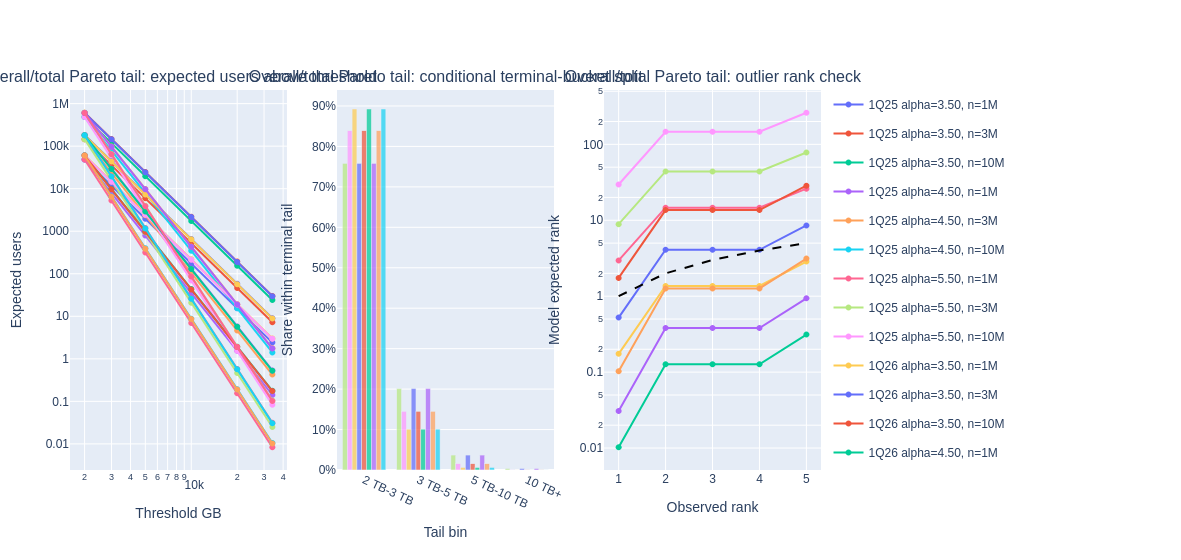

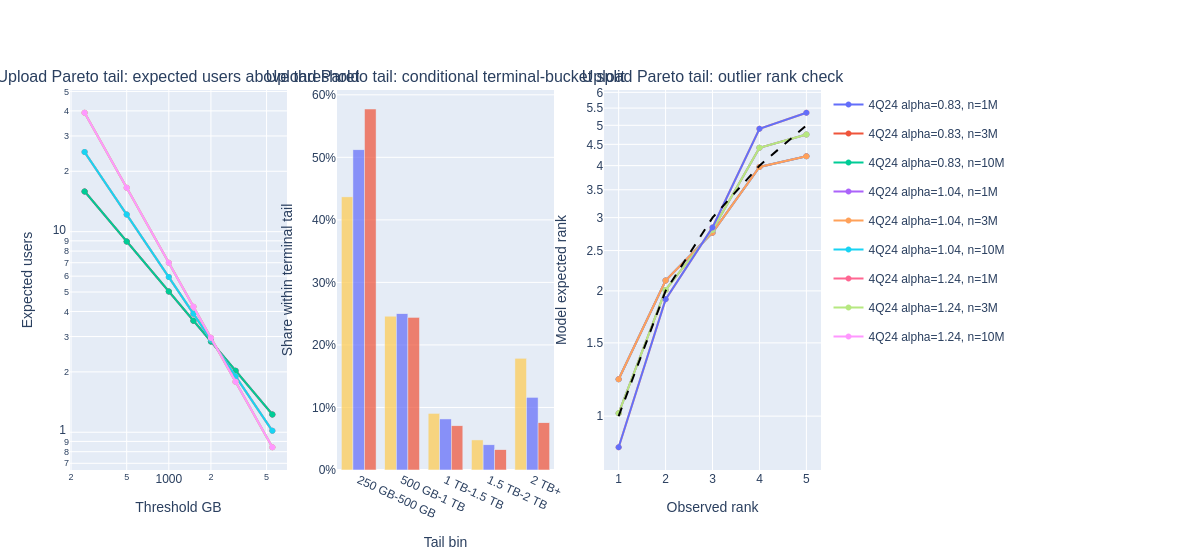

In [26]:
# Pareto tail sensitivity from 08_outliers.
# Overall/total tail: use down outliers as the extreme-total proxy, anchored at observed P(total >= 2 TB).
# Upload tail: fit absolute survival to upload outlier ranks with n_eff as the population-size knob.

import math

import plotly.graph_objects as go
from plotly.subplots import make_subplots

pareto_n_eff_values = [1_000_000, 3_000_000, 10_000_000]
pareto_total_alpha_values = [3.5, 4.5, 5.5]
pareto_total_tail_start_gb = 2_000.0
pareto_upload_tail_start_gb = 250.0

pareto_outliers = allTbls["08_outliers"].copy()
pareto_metrics = allTbls["01_period_metrics"].copy()

def _avg_metric(period, direction):
    return _metric_value(pareto_metrics, period, direction, "avg")

def _coalesce_outlier_value_gb(row):
    avg_gb = _avg_metric(row["period"], row["direction"])
    if pd.notna(row["value_tb"]):
        return float(row["value_tb"]) * 1000.0
    return float(row["mean_multiple"]) * avg_gb

def _pareto_survival_from_anchor(x_gb, anchor_gb, p_gt_anchor, alpha):
    if x_gb < anchor_gb:
        return np.nan
    if p_gt_anchor <= 0 or alpha <= 0:
        return np.nan
    return p_gt_anchor * (x_gb / anchor_gb) ** (-alpha)

def _pareto_bin_share_from_anchor(lower_gb, upper_gb, anchor_gb, p_gt_anchor, alpha):
    lower_survival = _pareto_survival_from_anchor(lower_gb, anchor_gb, p_gt_anchor, alpha)
    upper_survival = 0.0 if np.isposinf(upper_gb) else _pareto_survival_from_anchor(upper_gb, anchor_gb, p_gt_anchor, alpha)
    return lower_survival - upper_survival

def _pareto_rank_intercept(values_gb, ranks, n_eff, alpha):
    values_gb = np.asarray(values_gb, dtype=float)
    ranks = np.asarray(ranks, dtype=float)
    observed_survival = ranks / n_eff
    return float(np.mean(np.log(observed_survival) + alpha * np.log(values_gb)))

def _pareto_survival_from_intercept(x_gb, intercept, alpha):
    if x_gb <= 0 or alpha <= 0:
        return np.nan
    return min(1.0, math.exp(intercept - alpha * math.log(x_gb)))

def _pareto_bin_share_from_intercept(lower_gb, upper_gb, intercept, alpha):
    lower_survival = _pareto_survival_from_intercept(lower_gb, intercept, alpha)
    upper_survival = 0.0 if np.isposinf(upper_gb) else _pareto_survival_from_intercept(upper_gb, intercept, alpha)
    return lower_survival - upper_survival

def _sigma_equiv_from_survival(p):
    if not np.isfinite(p) or p <= 0 or p >= 1:
        return np.nan
    return nd.inv_cdf(1.0 - p)

def _one_in_n(p):
    if not np.isfinite(p) or p <= 0:
        return np.nan
    return 1.0 / p

def _rank_slope_alpha(values_gb, ranks):
    x = np.log(np.asarray(values_gb, dtype=float))
    y = np.log(np.asarray(ranks, dtype=float))
    slope = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return -float(slope)

def _tail_bin_label(lower_gb, upper_gb):
    def fmt(x):
        if np.isposinf(x):
            return "inf"
        if x >= 1000:
            return f"{x / 1000:.1f} TB".replace(".0", "")
        return f"{x:.0f} GB"
    if np.isposinf(upper_gb):
        return f"{fmt(lower_gb)}+"
    return f"{fmt(lower_gb)}-{fmt(upper_gb)}"

pareto_outliers["avg_gb"] = pareto_outliers.apply(lambda r: _avg_metric(r["period"], r["direction"]), axis=1)
pareto_outliers["outlier_value_gb"] = pareto_outliers.apply(_coalesce_outlier_value_gb, axis=1)
pareto_outliers["outlier_value_tb"] = pareto_outliers["outlier_value_gb"] / 1000.0
pareto_outliers["tail_name"] = np.where(pareto_outliers["direction"].eq("up"), "upload", "overall_proxy_down")

print("Pareto outlier source values")
display(
    pareto_outliers[
        [
            "period",
            "tail_name",
            "direction",
            "user_rank",
            "avg_gb",
            "mean_multiple",
            "value_tb",
            "outlier_value_tb",
        ]
    ]
    .sort_values(["tail_name", "user_rank"])
    .style.format(
        {
            "avg_gb": "{:.2f}",
            "mean_multiple": "{:.0f}",
            "value_tb": "{:.2f}",
            "outlier_value_tb": "{:.2f}",
        },
        na_rep="",
    )
)

pareto_rank_alpha_rows = []
for tail_name, rows in pareto_outliers.groupby("tail_name"):
    pareto_rank_alpha_rows.append(
        {
            "tail_name": tail_name,
            "rank_slope_alpha": _rank_slope_alpha(rows["outlier_value_gb"], rows["user_rank"]),
            "min_outlier_tb": rows["outlier_value_tb"].min(),
            "max_outlier_tb": rows["outlier_value_tb"].max(),
        }
    )
pareto_rank_alpha_summary = pd.DataFrame(pareto_rank_alpha_rows)

upload_rank_alpha = float(
    pareto_rank_alpha_summary.loc[
        pareto_rank_alpha_summary["tail_name"].eq("upload"),
        "rank_slope_alpha",
    ].iloc[0]
)
pareto_upload_alpha_values = [upload_rank_alpha * f for f in [0.8, 1.0, 1.2]]

print("Outlier rank-slope alpha summary")
display(
    pareto_rank_alpha_summary.style.format(
        {
            "rank_slope_alpha": "{:.3f}",
            "min_outlier_tb": "{:.2f}",
            "max_outlier_tb": "{:.2f}",
        }
    )
)

# Total/overall terminal share anchors. 4Q24 comes from the exceedance table; 1Q25/1Q26 come from the exclusive terminal bucket.
pareto_total_anchor_rows = []

if "exceedance_source" not in globals():
    exceedance_source = allTbls["03_usage_buckets_total_distribution_exceedance"].copy()
    exceedance_source = exceedance_source.rename(columns={"usage_lower_gb.1": "usage_upper_gb"})
    exceedance_source["mapped_access_type"] = np.where(
        exceedance_source["access_type"].eq("overall"),
        model_access_type,
        exceedance_source["access_type"],
    )

for _, row in exceedance_source[
    (exceedance_source["period"].eq("4Q24"))
    & (exceedance_source["access_type"].eq("overall"))
    & (exceedance_source["usage_lower_gb"].eq(pareto_total_tail_start_gb))
].iterrows():
    pareto_total_anchor_rows.append(
        {
            "period": row["period"],
            "anchor_source": "03 exceedance overall",
            "tail_start_gb": pareto_total_tail_start_gb,
            "p_gt_tail_start": row["share"],
        }
    )

for _, row in allTbls["02_usage_buckets_total_distribution_exclusive_normalized"][
    (allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]["access_type"].eq(model_access_type))
    & (allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]["usage_lower_gb"].eq(pareto_total_tail_start_gb))
].iterrows():
    pareto_total_anchor_rows.append(
        {
            "period": row["period"],
            "anchor_source": "02 exclusive terminal bucket",
            "tail_start_gb": pareto_total_tail_start_gb,
            "p_gt_tail_start": row["share"],
        }
    )

pareto_total_anchors = pd.DataFrame(pareto_total_anchor_rows).drop_duplicates(["period", "tail_start_gb"])

print("Total Pareto tail anchors")
display(
    pareto_total_anchors.sort_values("period").style.format(
        {
            "tail_start_gb": "{:.0f}",
            "p_gt_tail_start": "{:.3%}",
        }
    )
)

pareto_total_thresholds_gb = [2_000.0, 3_000.0, 5_000.0, 10_000.0, 20_000.0, 34_000.0]
pareto_upload_thresholds_gb = [250.0, 500.0, 1_000.0, 1_500.0, 2_000.0, 3_000.0, 5_500.0]
pareto_total_bins = [(2_000.0, 3_000.0), (3_000.0, 5_000.0), (5_000.0, 10_000.0), (10_000.0, np.inf)]
pareto_upload_bins = [(250.0, 500.0), (500.0, 1_000.0), (1_000.0, 1_500.0), (1_500.0, 2_000.0), (2_000.0, np.inf)]

pareto_threshold_rows = []
pareto_bin_rows = []
pareto_rank_check_rows = []

# Overall/total tail scenarios.
for _, anchor in pareto_total_anchors.iterrows():
    for alpha in pareto_total_alpha_values:
        for n_eff in pareto_n_eff_values:
            for threshold_gb in pareto_total_thresholds_gb:
                p = _pareto_survival_from_anchor(threshold_gb, anchor["tail_start_gb"], anchor["p_gt_tail_start"], alpha)
                pareto_threshold_rows.append(
                    {
                        "tail_name": "overall_total_anchor",
                        "period": anchor["period"],
                        "anchor_source": anchor["anchor_source"],
                        "alpha": alpha,
                        "n_eff": n_eff,
                        "threshold_gb": threshold_gb,
                        "threshold_label": _tail_bin_label(threshold_gb, np.inf),
                        "p_exceed": p,
                        "one_in_n": _one_in_n(p),
                        "expected_users": p * n_eff,
                        "sigma_equiv": _sigma_equiv_from_survival(p),
                    }
                )

            for lower_gb, upper_gb in pareto_total_bins:
                abs_share = _pareto_bin_share_from_anchor(lower_gb, upper_gb, anchor["tail_start_gb"], anchor["p_gt_tail_start"], alpha)
                conditional_share = abs_share / anchor["p_gt_tail_start"]
                pareto_bin_rows.append(
                    {
                        "tail_name": "overall_total_anchor",
                        "period": anchor["period"],
                        "alpha": alpha,
                        "n_eff": n_eff,
                        "bin_label": _tail_bin_label(lower_gb, upper_gb),
                        "lower_gb": lower_gb,
                        "upper_gb": upper_gb,
                        "absolute_share": abs_share,
                        "conditional_share_in_tail": conditional_share,
                        "expected_users": abs_share * n_eff,
                    }
                )

# Check 4Q24 total/down outliers against the 4Q24 anchored total tail.
pareto_total_outliers = pareto_outliers[pareto_outliers["tail_name"].eq("overall_proxy_down")].copy()
pareto_anchor_4q24 = pareto_total_anchors[pareto_total_anchors["period"].eq("4Q24")]
if not pareto_anchor_4q24.empty:
    anchor = pareto_anchor_4q24.iloc[0]
    for alpha in pareto_total_alpha_values:
        for n_eff in pareto_n_eff_values:
            for _, outlier in pareto_total_outliers.iterrows():
                p = _pareto_survival_from_anchor(outlier["outlier_value_gb"], anchor["tail_start_gb"], anchor["p_gt_tail_start"], alpha)
                expected_rank = p * n_eff
                pareto_rank_check_rows.append(
                    {
                        "tail_name": "overall_total_anchor",
                        "period": "4Q24",
                        "alpha": alpha,
                        "n_eff": n_eff,
                        "user_rank": outlier["user_rank"],
                        "outlier_value_tb": outlier["outlier_value_tb"],
                        "observed_survival": outlier["user_rank"] / n_eff,
                        "model_survival": p,
                        "expected_rank": expected_rank,
                        "rank_ratio_model_to_observed": expected_rank / outlier["user_rank"],
                        "abs_log10_rank_error": abs(math.log10(expected_rank / outlier["user_rank"])) if expected_rank > 0 else np.nan,
                    }
                )

# Upload tail scenarios from fixed-alpha rank fits.
pareto_upload_outliers = pareto_outliers[pareto_outliers["tail_name"].eq("upload")].copy()
for alpha in pareto_upload_alpha_values:
    for n_eff in pareto_n_eff_values:
        intercept = _pareto_rank_intercept(
            pareto_upload_outliers["outlier_value_gb"],
            pareto_upload_outliers["user_rank"],
            n_eff,
            alpha,
        )
        p_tail_start = _pareto_survival_from_intercept(pareto_upload_tail_start_gb, intercept, alpha)

        for threshold_gb in pareto_upload_thresholds_gb:
            p = _pareto_survival_from_intercept(threshold_gb, intercept, alpha)
            pareto_threshold_rows.append(
                {
                    "tail_name": "upload_rank_fit",
                    "period": "4Q24",
                    "anchor_source": "08 upload outlier ranks",
                    "alpha": alpha,
                    "n_eff": n_eff,
                    "threshold_gb": threshold_gb,
                    "threshold_label": _tail_bin_label(threshold_gb, np.inf),
                    "p_exceed": p,
                    "one_in_n": _one_in_n(p),
                    "expected_users": p * n_eff,
                    "sigma_equiv": _sigma_equiv_from_survival(p),
                }
            )

        for lower_gb, upper_gb in pareto_upload_bins:
            abs_share = _pareto_bin_share_from_intercept(lower_gb, upper_gb, intercept, alpha)
            conditional_share = abs_share / p_tail_start if p_tail_start > 0 else np.nan
            pareto_bin_rows.append(
                {
                    "tail_name": "upload_rank_fit",
                    "period": "4Q24",
                    "alpha": alpha,
                    "n_eff": n_eff,
                    "bin_label": _tail_bin_label(lower_gb, upper_gb),
                    "lower_gb": lower_gb,
                    "upper_gb": upper_gb,
                    "absolute_share": abs_share,
                    "conditional_share_in_tail": conditional_share,
                    "expected_users": abs_share * n_eff,
                }
            )

        for _, outlier in pareto_upload_outliers.iterrows():
            p = _pareto_survival_from_intercept(outlier["outlier_value_gb"], intercept, alpha)
            expected_rank = p * n_eff
            pareto_rank_check_rows.append(
                {
                    "tail_name": "upload_rank_fit",
                    "period": "4Q24",
                    "alpha": alpha,
                    "n_eff": n_eff,
                    "user_rank": outlier["user_rank"],
                    "outlier_value_tb": outlier["outlier_value_tb"],
                    "observed_survival": outlier["user_rank"] / n_eff,
                    "model_survival": p,
                    "expected_rank": expected_rank,
                    "rank_ratio_model_to_observed": expected_rank / outlier["user_rank"],
                    "abs_log10_rank_error": abs(math.log10(expected_rank / outlier["user_rank"])) if expected_rank > 0 else np.nan,
                }
            )

pareto_threshold_table = pd.DataFrame(pareto_threshold_rows)
pareto_tail_bucket_table = pd.DataFrame(pareto_bin_rows)
pareto_rank_check_table = pd.DataFrame(pareto_rank_check_rows)

pareto_rank_error_summary = (
    pareto_rank_check_table
    .groupby(["tail_name", "period", "alpha", "n_eff"], as_index=False)
    .agg(
        mean_abs_log10_rank_error=("abs_log10_rank_error", "mean"),
        max_abs_log10_rank_error=("abs_log10_rank_error", "max"),
        median_rank_ratio=("rank_ratio_model_to_observed", "median"),
    )
    .sort_values(["tail_name", "mean_abs_log10_rank_error", "alpha", "n_eff"])
)

print("Pareto threshold sensitivity")
display(
    pareto_threshold_table
    .sort_values(["tail_name", "period", "alpha", "n_eff", "threshold_gb"])
    .style.format(
        {
            "alpha": "{:.3f}",
            "n_eff": "{:,.0f}",
            "threshold_gb": "{:,.0f}",
            "p_exceed": "{:.6%}",
            "one_in_n": "{:,.0f}",
            "expected_users": "{:,.2f}",
            "sigma_equiv": "{:.2f}",
        }
    )
)

print("Pareto tail bucket split")
display(
    pareto_tail_bucket_table
    .sort_values(["tail_name", "period", "alpha", "n_eff", "lower_gb"])
    .style.format(
        {
            "alpha": "{:.3f}",
            "n_eff": "{:,.0f}",
            "lower_gb": "{:,.0f}",
            "upper_gb": "{:,.0f}",
            "absolute_share": "{:.6%}",
            "conditional_share_in_tail": "{:.3%}",
            "expected_users": "{:,.2f}",
        },
        na_rep="inf",
    )
)

print("Pareto outlier rank check")
display(
    pareto_rank_check_table
    .sort_values(["tail_name", "alpha", "n_eff", "user_rank"])
    .style.format(
        {
            "alpha": "{:.3f}",
            "n_eff": "{:,.0f}",
            "outlier_value_tb": "{:.2f}",
            "observed_survival": "{:.6%}",
            "model_survival": "{:.6%}",
            "expected_rank": "{:,.2f}",
            "rank_ratio_model_to_observed": "{:.2f}",
            "abs_log10_rank_error": "{:.3f}",
        }
    )
)

print("Pareto outlier rank error summary")
display(
    pareto_rank_error_summary.style.format(
        {
            "alpha": "{:.3f}",
            "n_eff": "{:,.0f}",
            "mean_abs_log10_rank_error": "{:.3f}",
            "max_abs_log10_rank_error": "{:.3f}",
            "median_rank_ratio": "{:.2f}",
        }
    )
)

# Graphs: expected users over tail thresholds, conditional split of the terminal bucket, and rank checks.
for tail_name, title in [
    ("overall_total_anchor", "Overall/total Pareto tail"),
    ("upload_rank_fit", "Upload Pareto tail"),
]:
    threshold_plot = pareto_threshold_table[pareto_threshold_table["tail_name"].eq(tail_name)].copy()
    bin_plot = pareto_tail_bucket_table[pareto_tail_bucket_table["tail_name"].eq(tail_name)].copy()
    rank_plot = pareto_rank_check_table[pareto_rank_check_table["tail_name"].eq(tail_name)].copy()

    fig = make_subplots(
        rows=1,
        cols=3,
        subplot_titles=(
            f"{title}: expected users above threshold",
            f"{title}: conditional terminal-bucket split",
            f"{title}: outlier rank check",
        ),
    )

    for (period, alpha, n_eff), rows in threshold_plot.groupby(["period", "alpha", "n_eff"]):
        rows = rows.sort_values("threshold_gb")
        label = f"{period} alpha={alpha:.2f}, n={n_eff/1_000_000:.0f}M"
        fig.add_trace(
            go.Scatter(
                x=rows["threshold_gb"],
                y=rows["expected_users"],
                mode="lines+markers",
                name=label,
                legendgroup=label,
            ),
            row=1,
            col=1,
        )

    for (period, alpha), rows in bin_plot.groupby(["period", "alpha"]):
        # Conditional split does not depend on n_eff for a fixed alpha, so keep one representative row per bin.
        rows = rows.sort_values("lower_gb").drop_duplicates(["bin_label"])
        label = f"{period} alpha={alpha:.2f}"
        fig.add_trace(
            go.Bar(
                x=rows["bin_label"],
                y=rows["conditional_share_in_tail"],
                name=label,
                legendgroup=label,
                showlegend=False,
                opacity=0.72,
            ),
            row=1,
            col=2,
        )

    for (alpha, n_eff), rows in rank_plot.groupby(["alpha", "n_eff"]):
        rows = rows.sort_values("user_rank")
        label = f"alpha={alpha:.2f}, n={n_eff/1_000_000:.0f}M"
        fig.add_trace(
            go.Scatter(
                x=rows["user_rank"],
                y=rows["expected_rank"],
                mode="lines+markers",
                name=label,
                legendgroup=label,
                showlegend=False,
                text=rows["outlier_value_tb"].map(lambda v: f"{v:.2f} TB"),
                hovertemplate="observed rank=%{x}<br>model expected rank=%{y:.2f}<br>usage=%{text}<extra></extra>",
            ),
            row=1,
            col=3,
        )

    observed_ranks = sorted(rank_plot["user_rank"].dropna().unique())
    if observed_ranks:
        fig.add_trace(
            go.Scatter(
                x=observed_ranks,
                y=observed_ranks,
                mode="lines",
                name="rank parity",
                line={"color": "black", "dash": "dash"},
                showlegend=False,
            ),
            row=1,
            col=3,
        )

    fig.update_xaxes(title_text="Threshold GB", type="log", row=1, col=1)
    fig.update_yaxes(title_text="Expected users", type="log", row=1, col=1)
    fig.update_xaxes(title_text="Tail bin", tickangle=25, row=1, col=2)
    fig.update_yaxes(title_text="Share within terminal tail", tickformat=".0%", row=1, col=2)
    fig.update_xaxes(title_text="Observed rank", row=1, col=3)
    fig.update_yaxes(title_text="Model expected rank", type="log", row=1, col=3)
    fig.update_layout(
        height=560,
        width=1600,
        barmode="group",
        legend={"orientation": "v", "x": 1.01, "y": 1.0},
        margin={"l": 70, "r": 360, "t": 90, "b": 90},
        hovermode="closest",
    )
    fig.show()

Model 6 grid finished in 159.2s
Fitted 1,008 period-level models across 504 configs
Model 6 top 5 acceptable candidates by leave-one-period-out bucket validation


,candidate_label,accepted_basic,head_family,shoulder_family,t_gb,u_gb,alpha,n_eff,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_error_pct,total_median_error_pct,fit_total_bucket_rmse,fit_total_avg_abs_error_pct,fit_total_median_abs_error_pct,tail_mean_contribution_pct_of_avg,recent_exceedance_mape,recent_exceedance_max_abs_pct_error,direction_sum_vs_total_avg_error_pct,outlier_mean_abs_log10_rank_error,down_projected_rank_range,upload_projected_rank_range
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",True,gamma,gamma,100,"5,000",2.50,"1,000,000",0.456%,0.545%,1.054%,3.191%,0.000%,0.153%,0.015%,0.045%,7.00%,67.37%,289.69%,0.0000%,2.939,48.5 to 229.2,"4,606.1 to 163,652.2"
1,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",True,lognormal,gamma,100,"5,000",2.50,"1,000,000",0.467%,0.548%,1.054%,3.191%,0.000%,0.154%,0.015%,0.045%,6.98%,67.16%,288.64%,0.0000%,2.939,48.3 to 228.6,"4,593.6 to 163,653.0"
2,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",True,weibull,gamma,100,"5,000",2.50,"1,000,000",0.536%,0.586%,1.054%,3.191%,0.000%,0.154%,0.015%,0.045%,6.99%,67.18%,288.77%,0.0000%,2.939,48.4 to 228.7,"4,595.2 to 163,652.9"
3,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",True,weibull,gamma,100,"5,000",1.50,"1,000,000",0.555%,0.615%,1.089%,3.198%,0.000%,0.211%,0.014%,0.033%,6.47%,29.09%,98.82%,0.0000%,3.092,168.2 to 427.2,"2,585.0 to 164,086.4"
4,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",True,weibull,weibull,100,"5,000",4.00,"1,000,000",0.568%,0.624%,1.091%,3.154%,0.000%,0.198%,0.033%,0.054%,9.55%,121.65%,561.46%,0.0000%,2.579,4.6 to 55.7,"6,776.8 to 163,198.5"


Top 5 period-level in-sample diagnostics


,candidate_label,period,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_source_gb,total_avg_model_gb,total_avg_error_pct,total_median_source_gb,total_median_model_gb,total_median_error_pct,tail_mean_contribution_pct_of_avg,direction_sum_vs_total_avg_error_pct,s_t,s_u
6,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,0.123%,0.126%,0.158%,663.20,663.20,0.000%,442.00,442.35,0.079%,6.08%,0.0000%,78.212%,0.484%
7,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,0.166%,0.180%,0.281%,720.50,720.71,0.029%,496.00,496.05,0.011%,7.92%,0.0000%,78.990%,0.685%
8,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,0.123%,0.126%,0.158%,663.20,663.20,0.000%,442.00,442.35,0.079%,6.08%,0.0000%,78.212%,0.484%
9,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,0.167%,0.181%,0.282%,720.50,720.71,0.029%,496.00,496.05,0.011%,7.88%,0.0000%,78.990%,0.682%
4,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,0.123%,0.126%,0.158%,663.20,663.20,0.000%,442.00,442.35,0.079%,6.08%,0.0000%,78.212%,0.484%
5,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,0.167%,0.181%,0.282%,720.50,720.71,0.029%,496.00,496.05,0.011%,7.89%,0.0000%,78.990%,0.682%
2,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q25,0.132%,0.142%,0.174%,663.20,663.23,0.005%,442.00,442.29,0.065%,6.56%,0.0000%,78.221%,0.290%
3,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q26,0.247%,0.280%,0.408%,720.50,720.66,0.022%,496.00,495.99,-0.002%,6.37%,0.0000%,79.006%,0.306%
0,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",1Q25,0.112%,0.115%,0.145%,663.20,663.20,0.000%,442.00,442.32,0.072%,9.23%,0.0000%,78.225%,0.918%
1,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",1Q26,0.245%,0.281%,0.421%,720.50,720.97,0.065%,496.00,495.82,-0.036%,9.86%,0.0000%,79.008%,1.066%


Top 5 leave-one-period-out validation diagnostics (trained shape, held-out total-median scaled)


,candidate_label,train_period,validation_period,validation_scale_factor,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_error_pct,total_median_error_pct,tail_mean_contribution_pct_of_avg
6,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,1Q26,1.121,0.422%,0.551%,1.054%,3.212%,0.000%,6.28%
7,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,1Q25,0.891,0.491%,0.538%,0.743%,-3.170%,0.000%,7.67%
8,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,1Q26,1.121,0.443%,0.557%,1.054%,3.212%,0.000%,6.28%
9,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,1Q25,0.891,0.491%,0.538%,0.743%,-3.170%,0.000%,7.63%
4,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,1Q26,1.121,0.581%,0.633%,1.054%,3.212%,-0.000%,6.28%
5,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,1Q25,0.891,0.491%,0.538%,0.743%,-3.170%,0.000%,7.64%
2,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q25,1Q26,1.121,0.658%,0.701%,1.089%,3.231%,0.000%,6.78%
3,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q26,1Q25,0.891,0.452%,0.529%,0.885%,-3.164%,0.000%,6.17%
0,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",1Q25,1Q26,1.121,0.649%,0.693%,1.091%,3.219%,0.000%,9.53%
1,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",1Q26,1Q25,0.891,0.486%,0.554%,0.810%,-3.089%,0.000%,9.55%


Top 5 recent 03 exceedance diagnostics


,candidate_label,period,threshold_gb,observed_exceedance,model_exceedance,exceedance_error,exceedance_abs_pct_error
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",3Q25,"1,000",20.9700%,23.3630%,+2.3930%,11.41%
1,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",3Q25,"2,000",4.4100%,5.3060%,+0.8960%,20.32%
2,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",3Q25,"5,000",0.1500%,0.5845%,+0.4345%,289.69%
3,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",4Q24,"1,000",24.3000%,23.3630%,-0.9370%,3.86%
4,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",4Q24,"2,000",6.0000%,5.3060%,-0.6940%,11.57%
5,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",3Q25,"1,000",20.9700%,23.3632%,+2.3932%,11.41%
6,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",3Q25,"2,000",4.4100%,5.3053%,+0.8953%,20.30%
7,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",3Q25,"5,000",0.1500%,0.5830%,+0.4330%,288.64%
8,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",4Q24,"1,000",24.3000%,23.3632%,-0.9368%,3.86%
9,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",4Q24,"2,000",6.0000%,5.3053%,-0.6947%,11.58%


Top 5 outlier rank diagnostics


,candidate_label,diagnostic_tail,direction,user_rank,outlier_value_tb,model_survival,expected_rank,rank_delta,rank_ratio_model_to_observed
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",down,down,1,34.00,0.004848%,48.48,+47.48,48.48
1,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",down,down,2,21.53,0.015200%,152.00,+150.00,76.00
2,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",down,down,3,21.53,0.015200%,152.00,+149.00,50.67
3,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",down,down,4,21.53,0.015200%,152.00,+148.00,38.00
4,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",down,down,5,18.26,0.022921%,229.21,+224.21,45.84
5,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",upload,up,1,5.50,0.460610%,"4,606.10","+4,605.10",4606.10
6,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",upload,up,2,2.85,1.754774%,"17,547.74","+17,545.74",8773.87
7,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",upload,up,3,2.07,4.830772%,"48,307.72","+48,304.72",16102.57
8,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",upload,up,4,1.33,14.266078%,"142,660.78","+142,656.78",35665.19
9,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",upload,up,5,1.24,16.365221%,"163,652.21","+163,647.21",32730.44


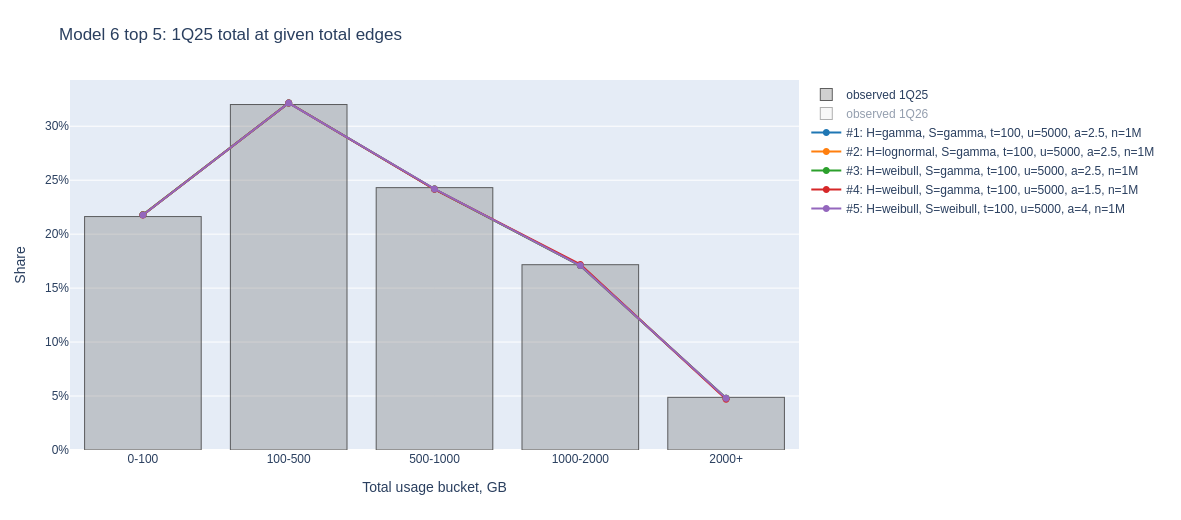

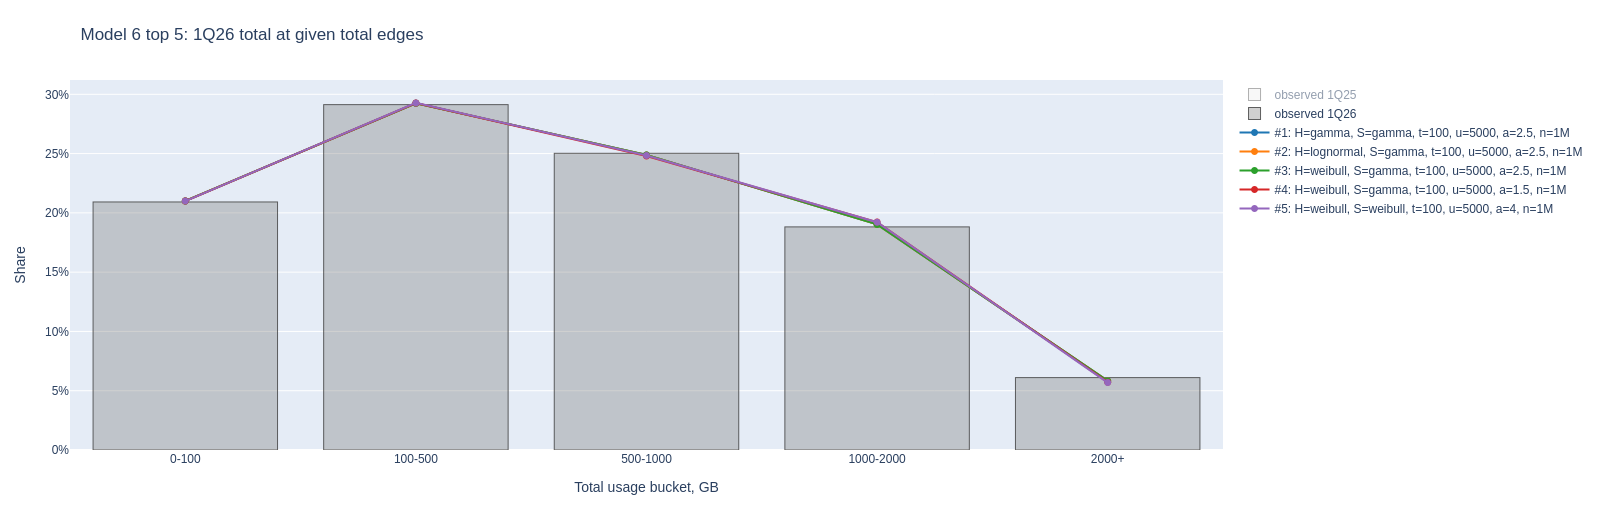

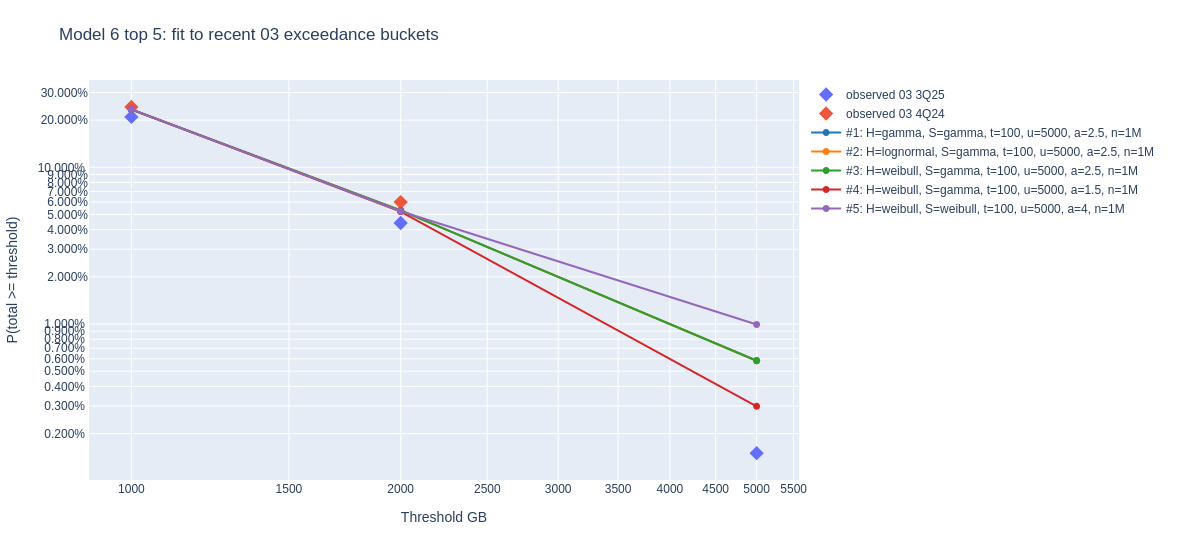

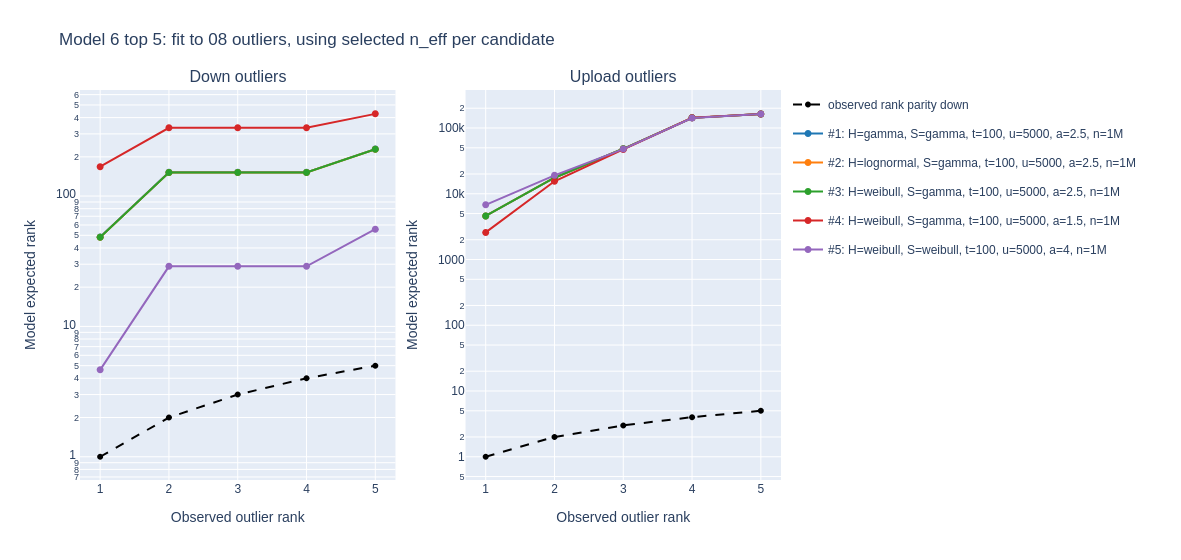

In [27]:
# Model 6: head / shoulder / pure Pareto tail grid search with leave-one-period-out validation.
# Segment survival is continuous at t and u. Head and shoulder are truncated distributions.

import itertools
import math
import time

import plotly.graph_objects as go
from scipy import optimize, special, stats

model6_periods = ["1Q25", "1Q26"]
model6_families = ["weibull", "gamma", "lognormal"]
model6_t_candidates = [100.0, 500.0, 1000.0]
model6_u_candidates = [1000.0, 2000.0, 5000.0]
model6_alpha_candidates = [1.2, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
model6_n_eff_candidates = [1_000_000, 3_000_000, 5_000_000]

model6_start_time = time.time()
model6_bucket_weight = 1.0 / 0.025
model6_metric_weight = 1.0 / 0.025
model6_max_nfev = 175
model6_start_variants = [0, 1]

model6_usage = (
    allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]
    .query("access_type == @model_access_type and period in @model6_periods")
    .sort_values(["period", "usage_lower_gb"])
    .copy()
)

model6_period_data = {}
for period in model6_periods:
    period_usage = model6_usage[model6_usage["period"].eq(period)].sort_values("usage_lower_gb")
    total_avg = _metric_value(allTbls["01_period_metrics"], period, "total", "avg")
    total_median = _metric_value(allTbls["01_period_metrics"], period, "total", "median")
    down_avg = _metric_value(allTbls["01_period_metrics"], period, "down", "avg")
    upload_avg = _metric_value(allTbls["01_period_metrics"], period, "up", "avg")
    model6_period_data[period] = {
        "edges": list(zip(period_usage["usage_lower_gb"].astype(float), period_usage["usage_upper_gb"].astype(float))),
        "edge_labels": period_usage.apply(
            lambda r: f"{r['usage_lower_gb']:g}+" if np.isinf(r["usage_upper_gb"]) else f"{r['usage_lower_gb']:g}-{r['usage_upper_gb']:g}",
            axis=1,
        ).tolist(),
        "observed_share": period_usage["share"].to_numpy(dtype=float),
        "total_avg": total_avg,
        "total_median": total_median,
        "down_avg": down_avg,
        "upload_avg": upload_avg,
        "direction_sum_avg": down_avg + upload_avg,
    }

def _model6_sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def _model6_logit(p):
    p = min(max(float(p), 1e-6), 1.0 - 1e-6)
    return math.log(p / (1.0 - p))

def _model6_family_cdf(x, family, p1, p2):
    if x <= 0:
        return 0.0
    if np.isposinf(x):
        return 1.0
    if family == "weibull":
        return stats.weibull_min.cdf(x, c=p1, scale=p2)
    if family == "gamma":
        return stats.gamma.cdf(x, a=p1, scale=p2)
    if family == "lognormal":
        return stats.lognorm.cdf(x, s=p2, scale=p1)
    raise ValueError(f"unknown family: {family}")

def _model6_family_ppf(q, family, p1, p2):
    q = min(max(float(q), 1e-12), 1.0 - 1e-12)
    if family == "weibull":
        return stats.weibull_min.ppf(q, c=p1, scale=p2)
    if family == "gamma":
        return stats.gamma.ppf(q, a=p1, scale=p2)
    if family == "lognormal":
        return stats.lognorm.ppf(q, s=p2, scale=p1)
    raise ValueError(f"unknown family: {family}")

def _model6_family_moment_to(x, family, p1, p2):
    if x <= 0:
        return 0.0
    if np.isposinf(x):
        if family == "weibull":
            return p2 * math.gamma(1.0 + 1.0 / p1)
        if family == "gamma":
            return p1 * p2
        if family == "lognormal":
            return p1 * math.exp(p2 * p2 / 2.0)
    if family == "weibull":
        a = 1.0 + 1.0 / p1
        z = (x / p2) ** p1
        return p2 * math.gamma(a) * special.gammainc(a, z)
    if family == "gamma":
        return p1 * p2 * stats.gamma.cdf(x, a=p1 + 1.0, scale=p2)
    if family == "lognormal":
        mu = math.log(p1)
        sigma = p2
        return math.exp(mu + sigma * sigma / 2.0) * stats.norm.cdf((math.log(x) - mu - sigma * sigma) / sigma)
    raise ValueError(f"unknown family: {family}")

def _model6_unpack_params(z):
    s_t = _model6_sigmoid(z[0])
    s_u = s_t * _model6_sigmoid(z[1])
    head_p1, head_p2, shoulder_p1, shoulder_p2 = [math.exp(v) for v in z[2:6]]
    return s_t, s_u, head_p1, head_p2, shoulder_p1, shoulder_p2

def _model6_bounds(head_family, shoulder_family):
    lower = [-10.0, -12.0]
    upper = [10.0, 10.0]

    def family_bounds(family):
        if family == "lognormal":
            return [(math.log(1.0), math.log(50_000.0)), (math.log(0.05), math.log(5.0))]
        return [(math.log(0.1), math.log(20.0)), (math.log(1.0), math.log(50_000.0))]

    for lo, hi in family_bounds(head_family) + family_bounds(shoulder_family):
        lower.append(lo)
        upper.append(hi)
    return np.array(lower), np.array(upper)

def _model6_make_model(z, head_family, shoulder_family, t_gb, u_gb, alpha):
    if t_gb >= u_gb or alpha <= 1.0:
        return None

    s_t, s_u, head_p1, head_p2, shoulder_p1, shoulder_p2 = _model6_unpack_params(z)
    if not (0.0 < s_u < s_t < 1.0):
        return None

    head_cdf_t = _model6_family_cdf(t_gb, head_family, head_p1, head_p2)
    shoulder_cdf_t = _model6_family_cdf(t_gb, shoulder_family, shoulder_p1, shoulder_p2)
    shoulder_cdf_u = _model6_family_cdf(u_gb, shoulder_family, shoulder_p1, shoulder_p2)
    shoulder_denom = shoulder_cdf_u - shoulder_cdf_t
    if head_cdf_t <= 1e-10 or shoulder_denom <= 1e-10:
        return None

    head_mass = 1.0 - s_t
    shoulder_mass = s_t - s_u
    tail_mass = s_u

    def cdf(x):
        if x <= 0:
            return 0.0
        if x < t_gb:
            return head_mass * _model6_family_cdf(x, head_family, head_p1, head_p2) / head_cdf_t
        if x < u_gb:
            shoulder_progress = (_model6_family_cdf(x, shoulder_family, shoulder_p1, shoulder_p2) - shoulder_cdf_t) / shoulder_denom
            return head_mass + shoulder_mass * shoulder_progress
        return 1.0 - tail_mass * (x / u_gb) ** (-alpha)

    def survival(x):
        if x <= 0:
            return 1.0
        if np.isposinf(x):
            return 0.0
        return 1.0 - cdf(x)

    def bucket_share(lower, upper):
        if np.isposinf(upper):
            return survival(lower)
        return cdf(upper) - cdf(lower)

    head_cond_mean = _model6_family_moment_to(t_gb, head_family, head_p1, head_p2) / head_cdf_t
    shoulder_cond_mean = (
        _model6_family_moment_to(u_gb, shoulder_family, shoulder_p1, shoulder_p2)
        - _model6_family_moment_to(t_gb, shoulder_family, shoulder_p1, shoulder_p2)
    ) / shoulder_denom
    tail_cond_mean = alpha * u_gb / (alpha - 1.0)
    mean_gb = head_mass * head_cond_mean + shoulder_mass * shoulder_cond_mean + tail_mass * tail_cond_mean

    if 0.5 <= head_mass:
        target_q = 0.5 / head_mass * head_cdf_t
        median_gb = _model6_family_ppf(target_q, head_family, head_p1, head_p2)
    elif 0.5 <= 1.0 - tail_mass:
        target_q = shoulder_cdf_t + (0.5 - head_mass) / shoulder_mass * shoulder_denom
        median_gb = _model6_family_ppf(target_q, shoulder_family, shoulder_p1, shoulder_p2)
    else:
        median_gb = u_gb * (tail_mass / 0.5) ** (1.0 / alpha)

    if not (np.isfinite(mean_gb) and np.isfinite(median_gb)) or mean_gb <= 0 or median_gb <= 0:
        return None

    return {
        "cdf": cdf,
        "survival": survival,
        "bucket_share": bucket_share,
        "mean_gb": mean_gb,
        "median_gb": median_gb,
        "tail_mean_contribution_gb": tail_mass * tail_cond_mean,
        "s_t": s_t,
        "s_u": s_u,
        "head_p1": head_p1,
        "head_p2": head_p2,
        "shoulder_p1": shoulder_p1,
        "shoulder_p2": shoulder_p2,
    }

def _model6_observed_survival(period, threshold_gb, alpha):
    data = model6_period_data[period]
    total = 0.0
    for (lower, upper), share in zip(data["edges"], data["observed_share"]):
        if lower >= threshold_gb:
            total += share
        elif lower < threshold_gb < upper and not np.isposinf(upper):
            total += share * (upper - threshold_gb) / (upper - lower)
        elif lower < threshold_gb and np.isposinf(upper):
            total += share * (lower / threshold_gb) ** alpha if lower > 0 else share
    return min(max(total, 1e-6), 1.0 - 1e-6)

def _model6_family_start(family, center_gb, variant):
    center_gb = max(float(center_gb), 1.0)
    if family == "lognormal":
        sigma = 0.9 if variant == 0 else 0.55
        return [math.log(center_gb), math.log(sigma)]
    if family == "weibull":
        shape = 1.0 if variant == 0 else 1.6
        return [math.log(shape), math.log(center_gb / (math.log(2.0) ** (1.0 / shape)))]
    if family == "gamma":
        shape = 2.0 if variant == 0 else 1.2
        return [math.log(shape), math.log(center_gb / shape)]
    raise ValueError(f"unknown family: {family}")

def _model6_initial_z(period, head_family, shoulder_family, t_gb, u_gb, alpha, variant):
    s_t = _model6_observed_survival(period, t_gb, alpha)
    s_u = min(_model6_observed_survival(period, u_gb, alpha), s_t * 0.95)
    if variant == 1:
        s_t = min(max(s_t * 1.05, 1e-5), 1.0 - 1e-5)
        s_u = min(max(s_u * 0.80, 1e-6), s_t * 0.95)

    q = min(max(s_u / s_t, 1e-6), 1.0 - 1e-6)
    head_center = max(t_gb / 2.0, 5.0)
    shoulder_center = math.sqrt(t_gb * u_gb)
    return np.array(
        [
            _model6_logit(s_t),
            _model6_logit(q),
            *_model6_family_start(head_family, head_center, variant),
            *_model6_family_start(shoulder_family, shoulder_center, variant),
        ],
        dtype=float,
    )

def _model6_scaled_model(model, scale_factor):
    def cdf(x):
        if x <= 0:
            return 0.0
        if np.isposinf(x):
            return 1.0
        return model["cdf"](x / scale_factor)

    def survival(x):
        if x <= 0:
            return 1.0
        if np.isposinf(x):
            return 0.0
        return model["survival"](x / scale_factor)

    def bucket_share(lower, upper):
        if np.isposinf(upper):
            return survival(lower)
        return cdf(upper) - cdf(lower)

    scaled = dict(model)
    scaled.update(
        {
            "cdf": cdf,
            "survival": survival,
            "bucket_share": bucket_share,
            "mean_gb": model["mean_gb"] * scale_factor,
            "median_gb": model["median_gb"] * scale_factor,
            "tail_mean_contribution_gb": model["tail_mean_contribution_gb"] * scale_factor,
            "validation_scale_factor": scale_factor,
        }
    )
    return scaled

def _model6_score_model(model, period):
    data = model6_period_data[period]
    predicted_shares = np.array([model["bucket_share"](lower, upper) for lower, upper in data["edges"]])
    share_error = predicted_shares - data["observed_share"]
    avg_error_pct = model["mean_gb"] / data["total_avg"] - 1.0
    median_error_pct = model["median_gb"] / data["total_median"] - 1.0
    return {
        "predicted_shares": predicted_shares,
        "share_error": share_error,
        "total_bucket_mae": float(np.mean(np.abs(share_error))),
        "total_bucket_rmse": float(math.sqrt(np.mean(np.square(share_error)))),
        "total_bucket_max_abs_error": float(np.max(np.abs(share_error))),
        "total_avg_model_gb": model["mean_gb"],
        "total_avg_source_gb": data["total_avg"],
        "total_avg_error_gb": model["mean_gb"] - data["total_avg"],
        "total_avg_error_pct": avg_error_pct,
        "total_median_model_gb": model["median_gb"],
        "total_median_source_gb": data["total_median"],
        "total_median_error_pct": median_error_pct,
        "direction_sum_avg_gb": data["direction_sum_avg"],
        "direction_sum_vs_total_avg_error_pct": data["direction_sum_avg"] / data["total_avg"] - 1.0,
        "tail_mean_contribution_gb": model["tail_mean_contribution_gb"],
        "tail_mean_contribution_pct_of_avg": model["tail_mean_contribution_gb"] / data["total_avg"],
        "s_t": model["s_t"],
        "s_u": model["s_u"],
    }

def _model6_fit_period(period, head_family, shoulder_family, t_gb, u_gb, alpha):
    data = model6_period_data[period]
    bounds = _model6_bounds(head_family, shoulder_family)

    def residuals(z):
        model = _model6_make_model(z, head_family, shoulder_family, t_gb, u_gb, alpha)
        if model is None:
            return np.ones(8) * 1e3
        score = _model6_score_model(model, period)
        if np.any(score["predicted_shares"] < -1e-8) or abs(score["predicted_shares"].sum() - 1.0) > 1e-5:
            return np.ones(8) * 1e3
        residual = list((score["predicted_shares"] - data["observed_share"]) * model6_bucket_weight)
        residual.append(score["total_avg_error_pct"] * model6_metric_weight)
        residual.append(score["total_median_error_pct"] * model6_metric_weight)
        if score["tail_mean_contribution_gb"] > data["total_avg"]:
            residual.append((score["tail_mean_contribution_pct_of_avg"] - 1.0) / 0.05)
        else:
            residual.append(0.0)
        return np.array(residual, dtype=float)

    best = None
    for variant in model6_start_variants:
        z0 = _model6_initial_z(period, head_family, shoulder_family, t_gb, u_gb, alpha, variant)
        try:
            fit = optimize.least_squares(
                residuals,
                z0,
                bounds=bounds,
                max_nfev=model6_max_nfev,
                xtol=1e-5,
                ftol=1e-5,
                gtol=1e-5,
            )
        except Exception:
            continue
        sse = float(np.sum(np.square(residuals(fit.x))))
        if best is None or sse < best["objective_sse"]:
            best = {"objective_sse": sse, "z": fit.x, "success": fit.success, "message": fit.message}

    if best is None:
        return None

    model = _model6_make_model(best["z"], head_family, shoulder_family, t_gb, u_gb, alpha)
    if model is None:
        return None
    score = _model6_score_model(model, period)
    best.update({"model": model, "score": score})
    return best

model6_fit_rows = []
model6_validation_rows = []
model6_fit_objects = {}
model6_config_rows = []

model6_fit_id = 0
for head_family, shoulder_family, t_gb, u_gb, alpha in itertools.product(
    model6_families,
    model6_families,
    model6_t_candidates,
    model6_u_candidates,
    model6_alpha_candidates,
):
    if t_gb >= u_gb or alpha <= 1.0:
        continue

    config_key = f"H={head_family}|S={shoulder_family}|t={t_gb:g}|u={u_gb:g}|a={alpha:g}"
    period_fits = {}

    for train_period in model6_periods:
        fit = _model6_fit_period(train_period, head_family, shoulder_family, t_gb, u_gb, alpha)
        if fit is None:
            continue
        model6_fit_id += 1
        fit_key = f"fit_{model6_fit_id}"
        model6_fit_objects[(config_key, train_period)] = fit
        period_fits[train_period] = fit
        model = fit["model"]
        score = fit["score"]
        model6_fit_rows.append(
            {
                "config_key": config_key,
                "fit_key": fit_key,
                "period": train_period,
                "head_family": head_family,
                "shoulder_family": shoulder_family,
                "t_gb": t_gb,
                "u_gb": u_gb,
                "alpha": alpha,
                "objective_sse": fit["objective_sse"],
                "head_p1": model["head_p1"],
                "head_p2": model["head_p2"],
                "shoulder_p1": model["shoulder_p1"],
                "shoulder_p2": model["shoulder_p2"],
                **{k: v for k, v in score.items() if k not in ["predicted_shares", "share_error"]},
            }
        )

    for train_period, fit in period_fits.items():
        for validation_period in model6_periods:
            if validation_period == train_period:
                continue
            validation_scale_factor = model6_period_data[validation_period]["total_median"] / fit["model"]["median_gb"]
            validation_model = _model6_scaled_model(fit["model"], validation_scale_factor)
            score = _model6_score_model(validation_model, validation_period)
            model6_validation_rows.append(
                {
                    "config_key": config_key,
                    "train_period": train_period,
                    "validation_period": validation_period,
                    "validation_scale_anchor": "held-out total median",
                    "validation_scale_factor": validation_scale_factor,
                    "head_family": head_family,
                    "shoulder_family": shoulder_family,
                    "t_gb": t_gb,
                    "u_gb": u_gb,
                    "alpha": alpha,
                    **{k: v for k, v in score.items() if k not in ["predicted_shares", "share_error"]},
                }
            )

model6_fit_table = pd.DataFrame(model6_fit_rows)
model6_validation_table = pd.DataFrame(model6_validation_rows)

model6_fit_summary = (
    model6_fit_table
    .groupby(["config_key", "head_family", "shoulder_family", "t_gb", "u_gb", "alpha"], as_index=False)
    .agg(
        fit_total_bucket_mae=("total_bucket_mae", "mean"),
        fit_total_bucket_rmse=("total_bucket_rmse", "mean"),
        fit_total_bucket_max_abs_error=("total_bucket_max_abs_error", "max"),
        fit_total_avg_abs_error_pct=("total_avg_error_pct", lambda s: float(np.mean(np.abs(s)))),
        fit_total_median_abs_error_pct=("total_median_error_pct", lambda s: float(np.mean(np.abs(s)))),
        tail_mean_contribution_pct_of_avg=("tail_mean_contribution_pct_of_avg", "mean"),
        max_tail_mean_contribution_pct_of_avg=("tail_mean_contribution_pct_of_avg", "max"),
        direction_sum_vs_total_avg_error_pct=("direction_sum_vs_total_avg_error_pct", lambda s: float(np.mean(np.abs(s)))),
        fit_period_count=("period", "nunique"),
    )
)

model6_validation_summary = (
    model6_validation_table
    .groupby(["config_key", "head_family", "shoulder_family", "t_gb", "u_gb", "alpha"], as_index=False)
    .agg(
        total_bucket_mae=("total_bucket_mae", "mean"),
        total_bucket_rmse=("total_bucket_rmse", "mean"),
        total_bucket_max_abs_error=("total_bucket_max_abs_error", "max"),
        total_avg_error_pct=("total_avg_error_pct", lambda s: float(np.mean(np.abs(s)))),
        total_median_error_pct=("total_median_error_pct", lambda s: float(np.mean(np.abs(s)))),
        validation_period_count=("validation_period", "nunique"),
    )
)

model6_candidate_summary_base = model6_validation_summary.merge(
    model6_fit_summary,
    on=["config_key", "head_family", "shoulder_family", "t_gb", "u_gb", "alpha"],
    how="inner",
    validate="one_to_one",
)

# Recent 03 exceedance diagnostic: compare the average 1Q25/1Q26 fitted survival to recent overall rows.
model6_recent_exceedance = exceedance_source[
    (exceedance_source["access_type"].eq("overall"))
    & (exceedance_source["period"].isin(["3Q25", "4Q24"]))
].copy()

model6_exceedance_rows = []
for _, candidate in model6_candidate_summary_base.iterrows():
    config_key = candidate["config_key"]
    fitted_models = [model6_fit_objects[(config_key, p)]["model"] for p in model6_periods if (config_key, p) in model6_fit_objects]
    if not fitted_models:
        continue
    for _, obs_row in model6_recent_exceedance.iterrows():
        threshold = float(obs_row["usage_lower_gb"])
        predicted = float(np.mean([m["survival"](threshold) for m in fitted_models]))
        observed = float(obs_row["share"])
        model6_exceedance_rows.append(
            {
                "config_key": config_key,
                "period": obs_row["period"],
                "source_ref": obs_row["source_ref"],
                "threshold_gb": threshold,
                "observed_exceedance": observed,
                "model_exceedance": predicted,
                "exceedance_error": predicted - observed,
                "exceedance_abs_pct_error": abs(predicted - observed) / observed if observed > 0 else np.nan,
            }
        )

model6_exceedance_table = pd.DataFrame(model6_exceedance_rows)
model6_exceedance_summary = (
    model6_exceedance_table
    .groupby("config_key", as_index=False)
    .agg(
        recent_exceedance_mape=("exceedance_abs_pct_error", "mean"),
        recent_exceedance_max_abs_pct_error=("exceedance_abs_pct_error", "max"),
    )
)

# Outlier diagnostics. These are deliberately soft: total model survival is used at down/upload GB values.
model6_outlier_source = pareto_outliers.copy() if "pareto_outliers" in globals() else allTbls["08_outliers"].copy()
if "outlier_value_gb" not in model6_outlier_source.columns:
    model6_outlier_source["avg_gb"] = model6_outlier_source.apply(lambda r: _metric_value(allTbls["01_period_metrics"], r["period"], r["direction"], "avg"), axis=1)
    model6_outlier_source["outlier_value_gb"] = model6_outlier_source.apply(lambda r: float(r["value_tb"]) * 1000.0 if pd.notna(r["value_tb"]) else float(r["mean_multiple"]) * r["avg_gb"], axis=1)
    model6_outlier_source["outlier_value_tb"] = model6_outlier_source["outlier_value_gb"] / 1000.0
if "tail_name" not in model6_outlier_source.columns:
    model6_outlier_source["tail_name"] = np.where(model6_outlier_source["direction"].eq("up"), "upload", "down")
model6_outlier_source["diagnostic_tail"] = np.where(model6_outlier_source["direction"].eq("up"), "upload", "down")

model6_outlier_rows = []
for _, candidate in model6_candidate_summary_base.iterrows():
    config_key = candidate["config_key"]
    fitted_models = [model6_fit_objects[(config_key, p)]["model"] for p in model6_periods if (config_key, p) in model6_fit_objects]
    if not fitted_models:
        continue
    for n_eff in model6_n_eff_candidates:
        for _, outlier in model6_outlier_source.iterrows():
            predicted_survival = float(np.mean([m["survival"](float(outlier["outlier_value_gb"])) for m in fitted_models]))
            expected_rank = predicted_survival * n_eff
            observed_rank = float(outlier["user_rank"])
            model6_outlier_rows.append(
                {
                    "config_key": config_key,
                    "n_eff": n_eff,
                    "direction": outlier["direction"],
                    "diagnostic_tail": outlier["diagnostic_tail"],
                    "user_rank": observed_rank,
                    "outlier_value_gb": float(outlier["outlier_value_gb"]),
                    "outlier_value_tb": float(outlier["outlier_value_tb"]),
                    "model_survival": predicted_survival,
                    "expected_rank": expected_rank,
                    "rank_delta": expected_rank - observed_rank,
                    "rank_ratio_model_to_observed": expected_rank / observed_rank if observed_rank > 0 else np.nan,
                    "abs_log10_rank_error": abs(math.log10(expected_rank / observed_rank)) if expected_rank > 0 and observed_rank > 0 else np.nan,
                }
            )

model6_outlier_table = pd.DataFrame(model6_outlier_rows)
model6_outlier_summary = (
    model6_outlier_table
    .groupby(["config_key", "n_eff"], as_index=False)
    .agg(
        outlier_mean_abs_log10_rank_error=("abs_log10_rank_error", "mean"),
        outlier_max_abs_log10_rank_error=("abs_log10_rank_error", "max"),
        down_rank_ratio_median=("rank_ratio_model_to_observed", lambda s: float(np.median(s[model6_outlier_table.loc[s.index, "diagnostic_tail"].eq("down")])) if model6_outlier_table.loc[s.index, "diagnostic_tail"].eq("down").any() else np.nan),
        upload_rank_ratio_median=("rank_ratio_model_to_observed", lambda s: float(np.median(s[model6_outlier_table.loc[s.index, "diagnostic_tail"].eq("upload")])) if model6_outlier_table.loc[s.index, "diagnostic_tail"].eq("upload").any() else np.nan),
    )
)

model6_best_n_eff = (
    model6_outlier_summary
    .sort_values(["config_key", "outlier_mean_abs_log10_rank_error", "n_eff"])
    .drop_duplicates("config_key")
)

model6_candidate_summary = (
    model6_candidate_summary_base
    .merge(model6_exceedance_summary, on="config_key", how="left", validate="one_to_one")
    .merge(model6_best_n_eff, on="config_key", how="left", validate="one_to_one")
)

model6_candidate_summary["accepted_basic"] = (
    model6_candidate_summary["fit_period_count"].eq(len(model6_periods))
    & model6_candidate_summary["validation_period_count"].eq(len(model6_periods))
    & model6_candidate_summary["max_tail_mean_contribution_pct_of_avg"].lt(1.0)
    & model6_candidate_summary["fit_total_avg_abs_error_pct"].lt(0.03)
    & model6_candidate_summary["fit_total_median_abs_error_pct"].lt(0.03)
)

model6_top5 = (
    model6_candidate_summary[model6_candidate_summary["accepted_basic"]]
    .sort_values(
        [
            "total_bucket_rmse",
            "total_bucket_mae",
            "total_bucket_max_abs_error",
            "total_avg_error_pct",
            "recent_exceedance_mape",
            "outlier_mean_abs_log10_rank_error",
        ],
        na_position="last",
    )
    .head(5)
    .reset_index(drop=True)
)

if model6_top5.empty:
    model6_top5 = (
        model6_candidate_summary
        .sort_values(
            [
                "total_bucket_rmse",
                "total_bucket_mae",
                "total_bucket_max_abs_error",
                "total_avg_error_pct",
                "recent_exceedance_mape",
                "outlier_mean_abs_log10_rank_error",
            ],
            na_position="last",
        )
        .head(5)
        .reset_index(drop=True)
    )

def _model6_rank_range_text(config_key, n_eff, diagnostic_tail):
    rows = model6_outlier_table[
        model6_outlier_table["config_key"].eq(config_key)
        & model6_outlier_table["n_eff"].eq(n_eff)
        & model6_outlier_table["diagnostic_tail"].eq(diagnostic_tail)
    ]
    if rows.empty:
        return ""
    return f"{rows['expected_rank'].min():,.1f} to {rows['expected_rank'].max():,.1f}"

model6_top5 = model6_top5.copy()
model6_top5["down_projected_rank_range"] = model6_top5.apply(lambda r: _model6_rank_range_text(r["config_key"], r["n_eff"], "down"), axis=1)
model6_top5["upload_projected_rank_range"] = model6_top5.apply(lambda r: _model6_rank_range_text(r["config_key"], r["n_eff"], "upload"), axis=1)
model6_top5["candidate_label"] = model6_top5.apply(
    lambda r: f"#{r.name + 1}: H={r['head_family']}, S={r['shoulder_family']}, t={r['t_gb']:g}, u={r['u_gb']:g}, a={r['alpha']:g}, n={r['n_eff']/1_000_000:g}M",
    axis=1,
)

model6_top5_cols = [
    "candidate_label",
    "accepted_basic",
    "head_family",
    "shoulder_family",
    "t_gb",
    "u_gb",
    "alpha",
    "n_eff",
    "total_bucket_mae",
    "total_bucket_rmse",
    "total_bucket_max_abs_error",
    "total_avg_error_pct",
    "total_median_error_pct",
    "fit_total_bucket_rmse",
    "fit_total_avg_abs_error_pct",
    "fit_total_median_abs_error_pct",
    "tail_mean_contribution_pct_of_avg",
    "recent_exceedance_mape",
    "recent_exceedance_max_abs_pct_error",
    "direction_sum_vs_total_avg_error_pct",
    "outlier_mean_abs_log10_rank_error",
    "down_projected_rank_range",
    "upload_projected_rank_range",
]

print(f"Model 6 grid finished in {time.time() - model6_start_time:.1f}s")
print(f"Fitted {len(model6_fit_table):,} period-level models across {model6_candidate_summary_base['config_key'].nunique():,} configs")
print("Model 6 top 5 acceptable candidates by leave-one-period-out bucket validation")
display(
    model6_top5[model6_top5_cols]
    .style.format(
        {
            "t_gb": "{:,.0f}",
            "u_gb": "{:,.0f}",
            "alpha": "{:.2f}",
            "n_eff": "{:,.0f}",
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_error_pct": "{:.3%}",
            "total_median_error_pct": "{:.3%}",
            "fit_total_bucket_rmse": "{:.3%}",
            "fit_total_avg_abs_error_pct": "{:.3%}",
            "fit_total_median_abs_error_pct": "{:.3%}",
            "tail_mean_contribution_pct_of_avg": "{:.2%}",
            "recent_exceedance_mape": "{:.2%}",
            "recent_exceedance_max_abs_pct_error": "{:.2%}",
            "direction_sum_vs_total_avg_error_pct": "{:.4%}",
            "outlier_mean_abs_log10_rank_error": "{:.3f}",
        }
    )
)

model6_top_keys = model6_top5["config_key"].tolist()
model6_top_period_fit_table = model6_fit_table[model6_fit_table["config_key"].isin(model6_top_keys)].copy()
model6_top_validation_table = model6_validation_table[model6_validation_table["config_key"].isin(model6_top_keys)].copy()
model6_top_exceedance_table = model6_exceedance_table[model6_exceedance_table["config_key"].isin(model6_top_keys)].copy()
model6_top_outlier_table = model6_outlier_table.merge(
    model6_top5[["config_key", "n_eff", "candidate_label"]],
    on=["config_key", "n_eff"],
    how="inner",
)

print("Top 5 period-level in-sample diagnostics")
display(
    model6_top_period_fit_table
    .merge(model6_top5[["config_key", "candidate_label"]], on="config_key", how="left")
    [[
        "candidate_label",
        "period",
        "total_bucket_mae",
        "total_bucket_rmse",
        "total_bucket_max_abs_error",
        "total_avg_source_gb",
        "total_avg_model_gb",
        "total_avg_error_pct",
        "total_median_source_gb",
        "total_median_model_gb",
        "total_median_error_pct",
        "tail_mean_contribution_pct_of_avg",
        "direction_sum_vs_total_avg_error_pct",
        "s_t",
        "s_u",
    ]]
    .sort_values(["candidate_label", "period"])
    .style.format(
        {
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_source_gb": "{:.2f}",
            "total_avg_model_gb": "{:.2f}",
            "total_avg_error_pct": "{:.3%}",
            "total_median_source_gb": "{:.2f}",
            "total_median_model_gb": "{:.2f}",
            "total_median_error_pct": "{:.3%}",
            "tail_mean_contribution_pct_of_avg": "{:.2%}",
            "direction_sum_vs_total_avg_error_pct": "{:.4%}",
            "s_t": "{:.3%}",
            "s_u": "{:.3%}",
        }
    )
)

print("Top 5 leave-one-period-out validation diagnostics (trained shape, held-out total-median scaled)")
display(
    model6_top_validation_table
    .merge(model6_top5[["config_key", "candidate_label"]], on="config_key", how="left")
    [[
        "candidate_label",
        "train_period",
        "validation_period",
        "validation_scale_factor",
        "total_bucket_mae",
        "total_bucket_rmse",
        "total_bucket_max_abs_error",
        "total_avg_error_pct",
        "total_median_error_pct",
        "tail_mean_contribution_pct_of_avg",
    ]]
    .sort_values(["candidate_label", "train_period"])
    .style.format(
        {
            "validation_scale_factor": "{:.3f}",
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_error_pct": "{:.3%}",
            "total_median_error_pct": "{:.3%}",
            "tail_mean_contribution_pct_of_avg": "{:.2%}",
        }
    )
)

print("Top 5 recent 03 exceedance diagnostics")
display(
    model6_top_exceedance_table
    .merge(model6_top5[["config_key", "candidate_label"]], on="config_key", how="left")
    [["candidate_label", "period", "threshold_gb", "observed_exceedance", "model_exceedance", "exceedance_error", "exceedance_abs_pct_error"]]
    .sort_values(["candidate_label", "period", "threshold_gb"])
    .style.format(
        {
            "threshold_gb": "{:,.0f}",
            "observed_exceedance": "{:.4%}",
            "model_exceedance": "{:.4%}",
            "exceedance_error": "{:+.4%}",
            "exceedance_abs_pct_error": "{:.2%}",
        }
    )
)

print("Top 5 outlier rank diagnostics")
display(
    model6_top_outlier_table
    [["candidate_label", "diagnostic_tail", "direction", "user_rank", "outlier_value_tb", "model_survival", "expected_rank", "rank_delta", "rank_ratio_model_to_observed"]]
    .sort_values(["candidate_label", "diagnostic_tail", "user_rank"])
    .style.format(
        {
            "user_rank": "{:.0f}",
            "outlier_value_tb": "{:.2f}",
            "model_survival": "{:.6%}",
            "expected_rank": "{:,.2f}",
            "rank_delta": "{:+,.2f}",
            "rank_ratio_model_to_observed": "{:.2f}",
        }
    )
)

model6_colorway = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
model6_color_map = {row["candidate_label"]: model6_colorway[i % len(model6_colorway)] for i, row in model6_top5.iterrows()}

# Graph 1 and 2: period bucket fits. Include both observed periods as togglable bars in each graph.
for target_period in model6_periods:
    data = model6_period_data[target_period]
    x_labels = data["edge_labels"]
    fig = go.Figure()
    for observed_period in model6_periods:
        obs_data = model6_period_data[observed_period]
        fig.add_trace(
            go.Bar(
                x=obs_data["edge_labels"],
                y=obs_data["observed_share"],
                name=f"observed {observed_period}",
                marker_color="rgba(120,120,120,0.35)" if observed_period == target_period else "rgba(180,180,180,0.20)",
                marker_line_color="rgba(60,60,60,0.8)",
                marker_line_width=1,
                visible=True if observed_period == target_period else "legendonly",
            )
        )
    for _, candidate in model6_top5.iterrows():
        fit = model6_fit_objects[(candidate["config_key"], target_period)]
        predicted = [fit["model"]["bucket_share"](lower, upper) for lower, upper in data["edges"]]
        fig.add_trace(
            go.Scatter(
                x=x_labels,
                y=predicted,
                mode="lines+markers",
                name=candidate["candidate_label"],
                line={"color": model6_color_map[candidate["candidate_label"]], "width": 2},
                marker={"size": 7},
            )
        )
    fig.update_yaxes(title_text="Share", tickformat=".0%")
    fig.update_xaxes(title_text="Total usage bucket, GB")
    fig.update_layout(
        title=f"Model 6 top 5: {target_period} total at given total edges",
        height=520,
        width=1200,
        barmode="overlay",
        legend={"orientation": "v", "x": 1.01, "y": 1.0},
        margin={"l": 70, "r": 380, "t": 80, "b": 70},
        hovermode="x unified",
    )
    fig.show()

# Graph 3: recent exceedance comparison.
fig = go.Figure()
for period, rows in model6_recent_exceedance.groupby("period"):
    rows = rows.sort_values("usage_lower_gb")
    fig.add_trace(
        go.Scatter(
            x=rows["usage_lower_gb"],
            y=rows["share"],
            mode="markers",
            name=f"observed 03 {period}",
            marker={"size": 11, "symbol": "diamond"},
        )
    )
for _, candidate in model6_top5.iterrows():
    rows = model6_top_exceedance_table[model6_top_exceedance_table["config_key"].eq(candidate["config_key"])].sort_values("threshold_gb")
    fig.add_trace(
        go.Scatter(
            x=rows["threshold_gb"],
            y=rows["model_exceedance"],
            mode="lines+markers",
            name=candidate["candidate_label"],
            line={"color": model6_color_map[candidate["candidate_label"]], "width": 2},
            marker={"size": 7},
        )
    )
fig.update_xaxes(title_text="Threshold GB", type="log")
fig.update_yaxes(title_text="P(total >= threshold)", type="log", tickformat=".3%")
fig.update_layout(
    title="Model 6 top 5: fit to recent 03 exceedance buckets",
    height=560,
    width=1200,
    legend={"orientation": "v", "x": 1.01, "y": 1.0},
    margin={"l": 80, "r": 380, "t": 80, "b": 80},
    hovermode="closest",
)
fig.show()

# Graph 4: outlier rank diagnostics for down and upload rows.
fig = make_subplots(
    rows=1,
    cols=2,
    shared_yaxes=False,
    subplot_titles=("Down outliers", "Upload outliers"),
)
for col, diagnostic_tail in [(1, "down"), (2, "upload")]:
    source_rows = model6_outlier_source[model6_outlier_source["diagnostic_tail"].eq(diagnostic_tail)].sort_values("user_rank")
    fig.add_trace(
        go.Scatter(
            x=source_rows["user_rank"],
            y=source_rows["user_rank"],
            mode="lines+markers",
            name=f"observed rank parity {diagnostic_tail}",
            line={"color": "black", "dash": "dash"},
            marker={"size": 6},
            showlegend=(col == 1),
        ),
        row=1,
        col=col,
    )
    for _, candidate in model6_top5.iterrows():
        rows = model6_top_outlier_table[
            model6_top_outlier_table["candidate_label"].eq(candidate["candidate_label"])
            & model6_top_outlier_table["diagnostic_tail"].eq(diagnostic_tail)
        ].sort_values("user_rank")
        fig.add_trace(
            go.Scatter(
                x=rows["user_rank"],
                y=rows["expected_rank"],
                mode="lines+markers",
                name=candidate["candidate_label"],
                legendgroup=candidate["candidate_label"],
                showlegend=(col == 1),
                line={"color": model6_color_map[candidate["candidate_label"]], "width": 2},
                marker={"size": 7},
                text=rows["outlier_value_tb"].map(lambda v: f"{v:.2f} TB"),
                hovertemplate="observed rank=%{x}<br>model expected rank=%{y:.2f}<br>usage=%{text}<extra></extra>",
            ),
            row=1,
            col=col,
        )
fig.update_xaxes(title_text="Observed outlier rank", row=1, col=1)
fig.update_xaxes(title_text="Observed outlier rank", row=1, col=2)
fig.update_yaxes(title_text="Model expected rank", type="log", row=1, col=1)
fig.update_yaxes(title_text="Model expected rank", type="log", row=1, col=2)
fig.update_layout(
    title="Model 6 top 5: fit to 08 outliers, using selected n_eff per candidate",
    height=560,
    width=1300,
    legend={"orientation": "v", "x": 1.01, "y": 1.0},
    margin={"l": 80, "r": 400, "t": 90, "b": 80},
    hovermode="closest",
)
fig.show()

In [1]:
# 1Q27 forecast: metrics, bucket shares, and Model 6 top-5 projection.
# This cell is self-contained enough to run after opening the saved notebook: it reads allData.ods and
# parses saved Model 6 top-5 output if the Model 6 variables are not live in the kernel.

import math
import re
from io import StringIO
from pathlib import Path

import nbformat
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from scipy import optimize, special, stats

forecast_path = Path("allData.ods")
if not forecast_path.exists():
    for candidate_path in [
        Path.cwd() / "allData.ods",
        Path.cwd() / "OVBI-SelfCap-Analysis" / "allData.ods",
        Path("/home/alice/CodexRoot/OVBI/OVBI-SelfCap-Analysis/allData.ods"),
    ]:
        if candidate_path.exists():
            forecast_path = candidate_path
            break
if "allTbls" not in globals():
    allTbls = pd.read_excel(forecast_path, sheet_name=None, engine="odf")

forecast_model_access_type = globals().get("model_access_type", "DOCSIS")
forecast_metric_access_type = globals().get("metric_access_type", "overall")
forecast_target_period = "1Q27"
forecast_target_q_index = None
forecast_horizon_quarters = 4
forecast_bucket_projection_method = "multinomial_logit_delta"

def _forecast_metric_value(metrics, period, direction, metric):
    vals = metrics.loc[
        (metrics["period"].eq(period))
        & (metrics["access_type"].eq(forecast_metric_access_type))
        & (metrics["direction"].eq(direction))
        & (metrics["metric"].eq(metric)),
        "value_gb",
    ]
    if vals.empty:
        return np.nan
    return float(vals.iloc[0])

def _forecast_period_to_q_index(period):
    match = re.fullmatch(r"([1-4])Q(\d{2})", str(period))
    if not match:
        raise ValueError(f"unsupported period format: {period}")
    quarter = int(match.group(1))
    year = 2000 + int(match.group(2))
    return year * 4 + (quarter - 1)

def _forecast_q_index_to_period(q_index):
    year = q_index // 4
    quarter = q_index % 4 + 1
    return f"{quarter}Q{str(year)[-2:]}"

def _forecast_fit_line(x, y, transform):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if transform == "log-linear":
        fit_y = np.log(y)
    elif transform == "linear":
        fit_y = y
    else:
        raise ValueError(transform)
    slope, intercept = np.polyfit(x, fit_y, 1)

    def predict(x_new):
        pred = intercept + slope * np.asarray(x_new, dtype=float)
        if transform == "log-linear":
            return np.exp(pred)
        return pred

    return intercept, slope, predict

def _forecast_metric_backtest(series_df, transform, target_x):
    rows = []
    for _, target in series_df.iterrows():
        train = series_df[series_df["q_index"] <= target["q_index"] - forecast_horizon_quarters]
        if len(train) < 4:
            continue
        _, _, predict = _forecast_fit_line(train["q_index"], train["value_gb"], transform)
        pred = float(predict([target["q_index"]])[0])
        actual = float(target["value_gb"])
        rows.append(
            {
                "period": target["period"],
                "actual_gb": actual,
                "predicted_gb": pred,
                "error_gb": pred - actual,
                "abs_pct_error": abs(pred - actual) / actual,
            }
        )
    return pd.DataFrame(rows)

def _forecast_recent_weighted_mape(backtest_df):
    if backtest_df.empty:
        return np.nan
    weights = np.arange(1, len(backtest_df) + 1, dtype=float)
    return float(np.average(backtest_df["abs_pct_error"], weights=weights))

forecast_metrics = allTbls["01_period_metrics"].copy()
forecast_metrics["q_index_abs"] = forecast_metrics["period"].map(_forecast_period_to_q_index)
forecast_q0 = int(forecast_metrics["q_index_abs"].min())
forecast_metrics["q_index"] = forecast_metrics["q_index_abs"] - forecast_q0
forecast_target_q_index = _forecast_period_to_q_index(forecast_target_period) - forecast_q0

metric_targets = [
    {"target_name": "total_avg", "direction": "total", "metric": "avg", "allowed_transforms": ["linear", "log-linear"]},
    {"target_name": "total_median", "direction": "total", "metric": "median", "allowed_transforms": ["linear", "log-linear"]},
    {"target_name": "down_avg", "direction": "down", "metric": "avg", "allowed_transforms": ["linear", "log-linear"]},
    {"target_name": "up_avg", "direction": "up", "metric": "avg", "allowed_transforms": ["log-linear", "linear"]},
]

forecast_metric_rows = []
forecast_metric_backtest_rows = []
for target in metric_targets:
    series = (
        forecast_metrics[
            forecast_metrics["access_type"].eq(forecast_metric_access_type)
            & forecast_metrics["direction"].eq(target["direction"])
            & forecast_metrics["metric"].eq(target["metric"])
        ]
        .sort_values("q_index")
        [["period", "q_index", "value_gb"]]
        .copy()
    )
    for transform in target["allowed_transforms"]:
        _, _, predict = _forecast_fit_line(series["q_index"], series["value_gb"], transform)
        fitted = predict(series["q_index"])
        forecast_gb = float(predict([forecast_target_q_index])[0])
        backtest = _forecast_metric_backtest(series, transform, forecast_target_q_index)
        if not backtest.empty:
            forecast_metric_backtest_rows.extend(
                [
                    {
                        "target_name": target["target_name"],
                        "transform": transform,
                        **row,
                    }
                    for row in backtest.to_dict("records")
                ]
            )
        forecast_metric_rows.append(
            {
                "target_name": target["target_name"],
                "direction": target["direction"],
                "metric": target["metric"],
                "transform": transform,
                "forecast_period": forecast_target_period,
                "forecast_gb": forecast_gb,
                "in_sample_rmse_gb": float(math.sqrt(np.mean(np.square(fitted - series["value_gb"].to_numpy())))),
                "backtest_count": len(backtest),
                "backtest_mape": float(backtest["abs_pct_error"].mean()) if not backtest.empty else np.nan,
                "backtest_recent_weighted_mape": _forecast_recent_weighted_mape(backtest),
                "backtest_rmse_gb": float(math.sqrt(np.mean(np.square(backtest["error_gb"])))) if not backtest.empty else np.nan,
            }
        )

forecast_metric_summary = pd.DataFrame(forecast_metric_rows)
forecast_metric_backtest_table = pd.DataFrame(forecast_metric_backtest_rows)

forecast_metric_selected = (
    forecast_metric_summary
    .sort_values(["target_name", "backtest_mape", "backtest_rmse_gb", "backtest_recent_weighted_mape"], na_position="last")
    .drop_duplicates("target_name")
    .copy()
)
# Per request, upstream defaults to log-linear unless linear is materially needed later.
up_log = forecast_metric_summary.query("target_name == 'up_avg' and transform == 'log-linear'")
if not up_log.empty:
    forecast_metric_selected = forecast_metric_selected[forecast_metric_selected["target_name"].ne("up_avg")]
    forecast_metric_selected = pd.concat([forecast_metric_selected, up_log], ignore_index=True)

forecast_metric_values = forecast_metric_selected.set_index("target_name")["forecast_gb"].to_dict()
forecast_total_avg_gb = float(forecast_metric_values["total_avg"])
forecast_total_median_gb = float(forecast_metric_values["total_median"])
forecast_down_avg_gb = float(forecast_metric_values["down_avg"])
forecast_up_avg_gb = float(forecast_metric_values["up_avg"])
forecast_direction_sum_gb = forecast_down_avg_gb + forecast_up_avg_gb

print("1Q27 mean/median/up/down forecast method comparison")
display(
    forecast_metric_summary
    .sort_values(["target_name", "backtest_mape", "backtest_rmse_gb"], na_position="last")
    .style.format(
        {
            "forecast_gb": "{:.2f}",
            "in_sample_rmse_gb": "{:.2f}",
            "backtest_mape": "{:.2%}",
            "backtest_recent_weighted_mape": "{:.2%}",
            "backtest_rmse_gb": "{:.2f}",
        }
    )
)

print("Selected 1Q27 metric forecasts")
display(
    forecast_metric_selected
    [["target_name", "direction", "metric", "transform", "forecast_period", "forecast_gb", "backtest_mape", "backtest_rmse_gb"]]
    .sort_values("target_name")
    .style.format(
        {
            "forecast_gb": "{:.2f}",
            "backtest_mape": "{:.2%}",
            "backtest_rmse_gb": "{:.2f}",
        }
    )
)
print(f"1Q27 diagnostic: down_avg + up_avg = {forecast_direction_sum_gb:.2f} GB vs total_avg = {forecast_total_avg_gb:.2f} GB ({forecast_direction_sum_gb / forecast_total_avg_gb - 1:+.2%})")

# Bucket share forecasts from 1Q25 and 1Q26 annual observations.
forecast_usage = (
    allTbls["02_usage_buckets_total_distribution_exclusive_normalized"]
    if "02_usage_buckets_total_distribution_exclusive_normalized" in allTbls
    else allTbls["02_usage_buckets_total_distribution_exclusive"].copy()
)
if "02_usage_buckets_total_distribution_exclusive_normalized" not in allTbls:
    forecast_usage["share"] = forecast_usage["share"] / forecast_usage.groupby(["period", "source_ref", "access_type"])["share"].transform("sum")

forecast_bucket_source = (
    forecast_usage
    .query("access_type == @forecast_model_access_type and period in ['1Q25', '1Q26']")
    .sort_values(["period", "usage_lower_gb"])
    .copy()
)
forecast_bucket_source["bucket_label"] = forecast_bucket_source.apply(
    lambda r: f"{r['usage_lower_gb']:g}+" if np.isinf(r["usage_upper_gb"]) else f"{r['usage_lower_gb']:g}-{r['usage_upper_gb']:g}",
    axis=1,
)
forecast_bucket_pivot = forecast_bucket_source.pivot(index="period", columns="bucket_label", values="share")
forecast_bucket_labels = forecast_bucket_source.drop_duplicates("bucket_label").sort_values("usage_lower_gb")["bucket_label"].tolist()
forecast_bucket_pivot = forecast_bucket_pivot[forecast_bucket_labels]
share_25 = forecast_bucket_pivot.loc["1Q25"].to_numpy(dtype=float)
share_26 = forecast_bucket_pivot.loc["1Q26"].to_numpy(dtype=float)

def _normalize_shares(shares):
    shares = np.asarray(shares, dtype=float)
    shares = np.clip(shares, 1e-8, None)
    return shares / shares.sum()

def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-8, 1 - 1e-8)
    return np.log(p / (1 - p))

def _invlogit(z):
    return 1 / (1 + np.exp(-np.asarray(z, dtype=float)))

def _softmax(logits):
    logits = np.asarray(logits, dtype=float)
    logits = logits - logits.max()
    exp_logits = np.exp(logits)
    return exp_logits / exp_logits.sum()

bucket_method_forecasts = {
    "direct_flat_1Q26": share_26,
    "direct_linear_delta": share_26 + (share_26 - share_25),
    "log_share_delta": np.exp(np.log(np.clip(share_26, 1e-8, None)) + (np.log(np.clip(share_26, 1e-8, None)) - np.log(np.clip(share_25, 1e-8, None)))),
    "independent_logit_delta": _invlogit(_logit(share_26) + (_logit(share_26) - _logit(share_25))),
}
base_25 = np.log(share_25[:-1] / share_25[-1])
base_26 = np.log(share_26[:-1] / share_26[-1])
forecast_logits = base_26 + (base_26 - base_25)
bucket_method_forecasts["multinomial_logit_delta"] = _softmax(np.r_[forecast_logits, 0.0])

forecast_bucket_rows = []
forecast_bucket_method_rows = []
for method, raw_shares in bucket_method_forecasts.items():
    forecast_shares = _normalize_shares(raw_shares)
    persistence_tase = float(np.sum(np.abs(share_26 - share_25)))
    total_delta_from_1q26 = float(np.sum(np.abs(forecast_shares - share_26)))
    forecast_bucket_method_rows.append(
        {
            "method": method,
            "forecast_period": forecast_target_period,
            "persistence_backtest_tase_1q26_from_1q25": persistence_tase if method == "direct_flat_1Q26" else np.nan,
            "forecast_delta_from_1q26_tase": total_delta_from_1q26,
            "selected_for_model6_projection": method == forecast_bucket_projection_method,
            "validation_note": "only direct_flat has a one-period persistence backtest; trend methods need more bucket history",
        }
    )
    for label, share in zip(forecast_bucket_labels, forecast_shares):
        forecast_bucket_rows.append(
            {
                "method": method,
                "forecast_period": forecast_target_period,
                "bucket_label": label,
                "forecast_share": share,
                "share_1q25": forecast_bucket_pivot.loc["1Q25", label],
                "share_1q26": forecast_bucket_pivot.loc["1Q26", label],
                "share_change_vs_1q26": share - forecast_bucket_pivot.loc["1Q26", label],
            }
        )

forecast_bucket_method_summary = pd.DataFrame(forecast_bucket_method_rows)
forecast_bucket_share_table = pd.DataFrame(forecast_bucket_rows)
forecast_selected_bucket_shares = (
    forecast_bucket_share_table[forecast_bucket_share_table["method"].eq(forecast_bucket_projection_method)]
    .sort_values("bucket_label", key=lambda s: s.map({label: i for i, label in enumerate(forecast_bucket_labels)}))
    ["forecast_share"]
    .to_numpy(dtype=float)
)

print("1Q27 exclusive bucket share forecast methods")
display(
    forecast_bucket_method_summary.style.format(
        {
            "persistence_backtest_tase_1q26_from_1q25": "{:.3%}",
            "forecast_delta_from_1q26_tase": "{:.3%}",
        },
        na_rep="",
    )
)

print("1Q27 exclusive bucket share forecasts")
display(
    forecast_bucket_share_table
    .sort_values(["method", "bucket_label"], key=lambda s: s.map({label: i for i, label in enumerate(forecast_bucket_labels)}) if s.name == "bucket_label" else s)
    .style.format(
        {
            "forecast_share": "{:.3%}",
            "share_1q25": "{:.3%}",
            "share_1q26": "{:.3%}",
            "share_change_vs_1q26": "{:+.3%}",
        }
    )
)

# Cumulative / exceedance bucket forecasts derived from exclusive shares.
thresholds = [100.0, 500.0, 1000.0, 2000.0]
source_edges = forecast_bucket_source.drop_duplicates("bucket_label").sort_values("usage_lower_gb")[["usage_lower_gb", "usage_upper_gb", "bucket_label"]].reset_index(drop=True)

def _survival_from_exclusive(shares, threshold):
    total = 0.0
    for share, (_, edge) in zip(shares, source_edges.iterrows()):
        lower = float(edge["usage_lower_gb"])
        upper = float(edge["usage_upper_gb"])
        if lower >= threshold:
            total += share
        elif lower < threshold < upper and not np.isposinf(upper):
            total += share * (upper - threshold) / (upper - lower)
        elif lower < threshold and np.isposinf(upper):
            total += share
    return total

forecast_cumulative_rows = []
for method, raw_shares in bucket_method_forecasts.items():
    forecast_shares = _normalize_shares(raw_shares)
    for threshold in thresholds:
        forecast_cumulative_rows.append(
            {
                "method": method,
                "threshold_gb": threshold,
                "share_1q25": _survival_from_exclusive(share_25, threshold),
                "share_1q26": _survival_from_exclusive(share_26, threshold),
                "forecast_exceedance_share": _survival_from_exclusive(forecast_shares, threshold),
                "absolute_pp_change_vs_1q26": _survival_from_exclusive(forecast_shares, threshold) - _survival_from_exclusive(share_26, threshold),
            }
        )
forecast_cumulative_share_table = pd.DataFrame(forecast_cumulative_rows)

print("1Q27 cumulative / exceedance share forecasts")
display(
    forecast_cumulative_share_table.style.format(
        {
            "threshold_gb": "{:,.0f}",
            "share_1q25": "{:.3%}",
            "share_1q26": "{:.3%}",
            "forecast_exceedance_share": "{:.3%}",
            "absolute_pp_change_vs_1q26": "{:+.3%}",
        }
    )
)

# Load saved Model 6 top-5 configs without rerunning the full grid.
def _forecast_load_saved_model6_top5():
    if "model6_top5" in globals() and isinstance(model6_top5, pd.DataFrame) and not model6_top5.empty:
        return model6_top5.copy()
    try:
        nb = nbformat.read("Analysis.ipynb", as_version=4)
        for cell in nb.cells:
            if not cell.source.startswith("# Model 6: head / shoulder / pure Pareto tail"):
                continue
            for output in cell.get("outputs", []):
                html = output.get("data", {}).get("text/html")
                if html and "candidate_label" in html and "accepted_basic" in html:
                    parsed = pd.read_html(StringIO(html))[0]
                    parsed = parsed.loc[:, ~parsed.columns.astype(str).str.startswith("Unnamed")]
                    return parsed
    except Exception:
        pass
    return pd.DataFrame(
        [
            {"candidate_label": "#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M", "head_family": "gamma", "shoulder_family": "gamma", "t_gb": 100.0, "u_gb": 5000.0, "alpha": 2.5, "n_eff": 1_000_000},
            {"candidate_label": "#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M", "head_family": "lognormal", "shoulder_family": "gamma", "t_gb": 100.0, "u_gb": 5000.0, "alpha": 2.5, "n_eff": 1_000_000},
            {"candidate_label": "#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M", "head_family": "weibull", "shoulder_family": "gamma", "t_gb": 100.0, "u_gb": 5000.0, "alpha": 2.5, "n_eff": 1_000_000},
            {"candidate_label": "#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M", "head_family": "weibull", "shoulder_family": "gamma", "t_gb": 100.0, "u_gb": 5000.0, "alpha": 1.5, "n_eff": 1_000_000},
            {"candidate_label": "#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M", "head_family": "weibull", "shoulder_family": "weibull", "t_gb": 100.0, "u_gb": 5000.0, "alpha": 4.0, "n_eff": 1_000_000},
        ]
    )

forecast_model6_top5_configs = _forecast_load_saved_model6_top5().head(5).copy()
for col in ["t_gb", "u_gb", "alpha", "n_eff"]:
    if col in forecast_model6_top5_configs.columns:
        forecast_model6_top5_configs[col] = pd.to_numeric(forecast_model6_top5_configs[col].astype(str).str.replace(",", ""), errors="coerce")

# Minimal selected-config Model 6 fitter for 1Q27. This avoids rerunning the full 504-config grid.
def _f6_sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def _f6_logit(p):
    p = min(max(float(p), 1e-6), 1 - 1e-6)
    return math.log(p / (1 - p))

def _f6_family_cdf(x, family, p1, p2):
    if x <= 0:
        return 0.0
    if np.isposinf(x):
        return 1.0
    if family == "weibull":
        return stats.weibull_min.cdf(x, c=p1, scale=p2)
    if family == "gamma":
        return stats.gamma.cdf(x, a=p1, scale=p2)
    if family == "lognormal":
        return stats.lognorm.cdf(x, s=p2, scale=p1)
    raise ValueError(family)

def _f6_family_ppf(q, family, p1, p2):
    q = min(max(float(q), 1e-12), 1 - 1e-12)
    if family == "weibull":
        return stats.weibull_min.ppf(q, c=p1, scale=p2)
    if family == "gamma":
        return stats.gamma.ppf(q, a=p1, scale=p2)
    if family == "lognormal":
        return stats.lognorm.ppf(q, s=p2, scale=p1)
    raise ValueError(family)

def _f6_family_moment_to(x, family, p1, p2):
    if x <= 0:
        return 0.0
    if np.isposinf(x):
        if family == "weibull":
            return p2 * math.gamma(1 + 1 / p1)
        if family == "gamma":
            return p1 * p2
        if family == "lognormal":
            return p1 * math.exp(p2 * p2 / 2)
    if family == "weibull":
        a = 1 + 1 / p1
        z = (x / p2) ** p1
        return p2 * math.gamma(a) * special.gammainc(a, z)
    if family == "gamma":
        return p1 * p2 * stats.gamma.cdf(x, a=p1 + 1, scale=p2)
    if family == "lognormal":
        mu = math.log(p1)
        sigma = p2
        return math.exp(mu + sigma * sigma / 2) * stats.norm.cdf((math.log(x) - mu - sigma * sigma) / sigma)
    raise ValueError(family)

def _f6_unpack(z):
    s_t = _f6_sigmoid(z[0])
    s_u = s_t * _f6_sigmoid(z[1])
    return s_t, s_u, *[math.exp(v) for v in z[2:6]]

def _f6_make_model(z, head_family, shoulder_family, t_gb, u_gb, alpha):
    s_t, s_u, h1, h2, s1, s2 = _f6_unpack(z)
    if not (0 < s_u < s_t < 1) or t_gb >= u_gb or alpha <= 1:
        return None
    fh_t = _f6_family_cdf(t_gb, head_family, h1, h2)
    fs_t = _f6_family_cdf(t_gb, shoulder_family, s1, s2)
    fs_u = _f6_family_cdf(u_gb, shoulder_family, s1, s2)
    denom_s = fs_u - fs_t
    if fh_t <= 1e-10 or denom_s <= 1e-10:
        return None
    head_mass = 1 - s_t
    shoulder_mass = s_t - s_u
    tail_mass = s_u

    def cdf(x):
        if x <= 0:
            return 0.0
        if x < t_gb:
            return head_mass * _f6_family_cdf(x, head_family, h1, h2) / fh_t
        if x < u_gb:
            return head_mass + shoulder_mass * (_f6_family_cdf(x, shoulder_family, s1, s2) - fs_t) / denom_s
        return 1 - tail_mass * (x / u_gb) ** (-alpha)

    def survival(x):
        if x <= 0:
            return 1.0
        if np.isposinf(x):
            return 0.0
        return 1 - cdf(x)

    def bucket_share(lower, upper):
        if np.isposinf(upper):
            return survival(lower)
        return cdf(upper) - cdf(lower)

    head_mean = _f6_family_moment_to(t_gb, head_family, h1, h2) / fh_t
    shoulder_mean = (_f6_family_moment_to(u_gb, shoulder_family, s1, s2) - _f6_family_moment_to(t_gb, shoulder_family, s1, s2)) / denom_s
    tail_mean = alpha * u_gb / (alpha - 1)
    mean_gb = head_mass * head_mean + shoulder_mass * shoulder_mean + tail_mass * tail_mean
    if 0.5 <= head_mass:
        median_gb = _f6_family_ppf(0.5 / head_mass * fh_t, head_family, h1, h2)
    elif 0.5 <= 1 - tail_mass:
        median_gb = _f6_family_ppf(fs_t + (0.5 - head_mass) / shoulder_mass * denom_s, shoulder_family, s1, s2)
    else:
        median_gb = u_gb * (tail_mass / 0.5) ** (1 / alpha)
    if not (np.isfinite(mean_gb) and np.isfinite(median_gb)):
        return None
    return {"bucket_share": bucket_share, "survival": survival, "mean_gb": mean_gb, "median_gb": median_gb, "s_t": s_t, "s_u": s_u, "tail_mean_contribution_gb": tail_mass * tail_mean}

def _f6_bounds(head_family, shoulder_family):
    lo = [-10, -12]
    hi = [10, 10]
    def b(family):
        if family == "lognormal":
            return [(math.log(1), math.log(50_000)), (math.log(0.05), math.log(5))]
        return [(math.log(0.1), math.log(20)), (math.log(1), math.log(50_000))]
    for a, b_ in b(head_family) + b(shoulder_family):
        lo.append(a); hi.append(b_)
    return np.array(lo), np.array(hi)

def _f6_family_start(family, center, variant):
    center = max(float(center), 1.0)
    if family == "lognormal":
        return [math.log(center), math.log(0.9 if variant == 0 else 0.55)]
    if family == "weibull":
        shape = 1.0 if variant == 0 else 1.6
        return [math.log(shape), math.log(center / (math.log(2) ** (1 / shape)))]
    if family == "gamma":
        shape = 2.0 if variant == 0 else 1.2
        return [math.log(shape), math.log(center / shape)]
    raise ValueError(family)

def _f6_observed_survival(target_shares, threshold, alpha):
    return _survival_from_exclusive(target_shares, threshold) if threshold <= 2000 else _survival_from_exclusive(target_shares, 2000) * (2000 / threshold) ** alpha

def _f6_initial_z(head_family, shoulder_family, t_gb, u_gb, alpha, target_shares, variant):
    s_t = min(max(_f6_observed_survival(target_shares, t_gb, alpha), 1e-6), 1 - 1e-6)
    s_u = min(max(_f6_observed_survival(target_shares, u_gb, alpha), 1e-7), s_t * 0.95)
    if variant == 1:
        s_t = min(max(s_t * 1.03, 1e-6), 1 - 1e-6)
        s_u = min(max(s_u * 0.8, 1e-7), s_t * 0.95)
    return np.array([_f6_logit(s_t), _f6_logit(s_u / s_t), *_f6_family_start(head_family, t_gb / 2, variant), *_f6_family_start(shoulder_family, math.sqrt(t_gb * u_gb), variant)])

def _f6_fit_to_forecast(row, target_shares):
    head_family = row["head_family"]
    shoulder_family = row["shoulder_family"]
    t_gb = float(row["t_gb"])
    u_gb = float(row["u_gb"])
    alpha = float(row["alpha"])
    edges = list(zip(source_edges["usage_lower_gb"].astype(float), source_edges["usage_upper_gb"].astype(float)))
    bounds = _f6_bounds(head_family, shoulder_family)

    def residual(z):
        model = _f6_make_model(z, head_family, shoulder_family, t_gb, u_gb, alpha)
        if model is None:
            return np.ones(8) * 1e3
        pred = np.array([model["bucket_share"](lower, upper) for lower, upper in edges])
        if np.any(pred < -1e-8):
            return np.ones(8) * 1e3
        res = list((pred - target_shares) / 0.025)
        res.append((model["mean_gb"] / forecast_total_avg_gb - 1) / 0.025)
        res.append((model["median_gb"] / forecast_total_median_gb - 1) / 0.025)
        return np.array(res)

    best = None
    for variant in [0, 1]:
        z0 = _f6_initial_z(head_family, shoulder_family, t_gb, u_gb, alpha, target_shares, variant)
        fit = optimize.least_squares(residual, z0, bounds=bounds, max_nfev=250, xtol=1e-5, ftol=1e-5, gtol=1e-5)
        sse = float(np.sum(np.square(residual(fit.x))))
        if best is None or sse < best[0]:
            best = (sse, fit.x)
    model = _f6_make_model(best[1], head_family, shoulder_family, t_gb, u_gb, alpha)
    pred = np.array([model["bucket_share"](lower, upper) for lower, upper in edges])
    err = pred - target_shares
    return model, pred, err, best[0]

model6_2027_summary_rows = []
model6_2027_bucket_rows = []
for _, row in forecast_model6_top5_configs.iterrows():
    model, pred, err, objective_sse = _f6_fit_to_forecast(row, forecast_selected_bucket_shares)
    label = row.get("candidate_label", f"H={row['head_family']}, S={row['shoulder_family']}, t={row['t_gb']}, u={row['u_gb']}, a={row['alpha']}")
    model6_2027_summary_rows.append(
        {
            "candidate_label": label,
            "bucket_forecast_method": forecast_bucket_projection_method,
            "head_family": row["head_family"],
            "shoulder_family": row["shoulder_family"],
            "t_gb": row["t_gb"],
            "u_gb": row["u_gb"],
            "alpha": row["alpha"],
            "objective_sse": objective_sse,
            "total_bucket_mae": float(np.mean(np.abs(err))),
            "total_bucket_rmse": float(math.sqrt(np.mean(np.square(err)))),
            "total_bucket_max_abs_error": float(np.max(np.abs(err))),
            "total_avg_model_gb": model["mean_gb"],
            "total_avg_forecast_gb": forecast_total_avg_gb,
            "total_avg_error_pct": model["mean_gb"] / forecast_total_avg_gb - 1,
            "total_median_model_gb": model["median_gb"],
            "total_median_forecast_gb": forecast_total_median_gb,
            "total_median_error_pct": model["median_gb"] / forecast_total_median_gb - 1,
            "s_t": model["s_t"],
            "s_u": model["s_u"],
            "tail_mean_contribution_pct_of_avg": model["tail_mean_contribution_gb"] / forecast_total_avg_gb,
        }
    )
    for label_bucket, target_share, pred_share, share_error in zip(forecast_bucket_labels, forecast_selected_bucket_shares, pred, err):
        model6_2027_bucket_rows.append(
            {
                "candidate_label": label,
                "bucket_label": label_bucket,
                "forecast_bucket_share": target_share,
                "model6_share": pred_share,
                "share_error": share_error,
            }
        )

model6_2027_projection_summary = pd.DataFrame(model6_2027_summary_rows).sort_values(["total_bucket_rmse", "total_avg_error_pct"])
model6_2027_bucket_projection = pd.DataFrame(model6_2027_bucket_rows)

print("Model 6 top 5 backtest on projected 1Q27 figures")
display(
    model6_2027_projection_summary.style.format(
        {
            "t_gb": "{:,.0f}",
            "u_gb": "{:,.0f}",
            "alpha": "{:.2f}",
            "objective_sse": "{:.2f}",
            "total_bucket_mae": "{:.3%}",
            "total_bucket_rmse": "{:.3%}",
            "total_bucket_max_abs_error": "{:.3%}",
            "total_avg_model_gb": "{:.2f}",
            "total_avg_forecast_gb": "{:.2f}",
            "total_avg_error_pct": "{:+.3%}",
            "total_median_model_gb": "{:.2f}",
            "total_median_forecast_gb": "{:.2f}",
            "total_median_error_pct": "{:+.3%}",
            "s_t": "{:.3%}",
            "s_u": "{:.3%}",
            "tail_mean_contribution_pct_of_avg": "{:.2%}",
        }
    )
)

# Graph: Projected 1Q27 total at given total edges.
model6_2027_colorway = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
fig = go.Figure()
for period, shares, visible, color in [
    ("observed 1Q25", share_25, "legendonly", "rgba(130,130,130,0.22)"),
    ("observed 1Q26", share_26, True, "rgba(100,100,100,0.30)"),
]:
    fig.add_trace(
        go.Bar(
            x=forecast_bucket_labels,
            y=shares,
            name=period,
            marker_color=color,
            marker_line_color="rgba(60,60,60,0.7)",
            marker_line_width=1,
            visible=visible,
        )
    )
for method in forecast_bucket_method_summary["method"]:
    shares = forecast_bucket_share_table[forecast_bucket_share_table["method"].eq(method)].sort_values("bucket_label", key=lambda s: s.map({label: i for i, label in enumerate(forecast_bucket_labels)}))["forecast_share"]
    fig.add_trace(
        go.Bar(
            x=forecast_bucket_labels,
            y=shares,
            name=f"forecast {forecast_target_period}: {method}",
            marker_color="rgba(70,130,180,0.32)" if method == forecast_bucket_projection_method else "rgba(70,130,180,0.16)",
            marker_line_color="rgba(40,80,120,0.7)",
            marker_line_width=1,
            visible=True if method == forecast_bucket_projection_method else "legendonly",
        )
    )
for i, (_, row) in enumerate(model6_2027_projection_summary.iterrows()):
    rows = model6_2027_bucket_projection[model6_2027_bucket_projection["candidate_label"].eq(row["candidate_label"])].sort_values("bucket_label", key=lambda s: s.map({label: i for i, label in enumerate(forecast_bucket_labels)}))
    fig.add_trace(
        go.Scatter(
            x=forecast_bucket_labels,
            y=rows["model6_share"],
            mode="lines+markers",
            name=row["candidate_label"],
            line={"color": model6_2027_colorway[i % len(model6_2027_colorway)], "width": 2},
            marker={"size": 7},
        )
    )
fig.update_yaxes(title_text="Share", tickformat=".0%")
fig.update_xaxes(title_text="Total usage bucket, GB")
fig.update_layout(
    title=f"Model 6 top 5: projected {forecast_target_period} total at given total edges",
    height=560,
    width=1300,
    barmode="overlay",
    legend={"orientation": "v", "x": 1.01, "y": 1.0},
    margin={"l": 70, "r": 430, "t": 90, "b": 80},
    hovermode="x unified",
)
fig.show()

1Q27 mean/median/up/down forecast method comparison


,target_name,direction,metric,transform,forecast_period,forecast_gb,in_sample_rmse_gb,backtest_count,backtest_mape,backtest_recent_weighted_mape,backtest_rmse_gb
4,down_avg,down,avg,linear,1Q27,738.18,34.01,2,4.41%,5.30%,34.33
5,down_avg,down,avg,log-linear,1Q27,748.87,33.99,2,5.84%,6.78%,43.37
0,total_avg,total,avg,linear,1Q27,802.36,35.37,2,3.57%,4.43%,31.86
1,total_avg,total,avg,log-linear,1Q27,815.30,35.33,2,5.03%,5.95%,41.57
2,total_median,total,median,linear,1Q27,561.93,25.78,2,3.42%,3.45%,17.56
3,total_median,total,median,log-linear,1Q27,575.37,25.54,2,3.70%,4.28%,20.45
6,up_avg,up,avg,log-linear,1Q27,66.86,1.63,2,4.95%,4.03%,3.18
7,up_avg,up,avg,linear,1Q27,64.17,1.74,2,6.65%,5.90%,3.94


Selected 1Q27 metric forecasts


,target_name,direction,metric,transform,forecast_period,forecast_gb,backtest_mape,backtest_rmse_gb
0,down_avg,down,avg,linear,1Q27,738.18,4.41%,34.33
1,total_avg,total,avg,linear,1Q27,802.36,3.57%,31.86
2,total_median,total,median,linear,1Q27,561.93,3.42%,17.56
3,up_avg,up,avg,log-linear,1Q27,66.86,4.95%,3.18


1Q27 diagnostic: down_avg + up_avg = 805.04 GB vs total_avg = 802.36 GB (+0.33%)
1Q27 exclusive bucket share forecast methods


,method,forecast_period,persistence_backtest_tase_1q26_from_1q25,forecast_delta_from_1q26_tase,selected_for_model6_projection,validation_note
0,direct_flat_1Q26,1Q27,7.180%,0.000%,False,only direct_flat has a one-period persistence backtest; trend methods need more bucket history
1,direct_linear_delta,1Q27,,7.180%,False,only direct_flat has a one-period persistence backtest; trend methods need more bucket history
2,log_share_delta,1Q27,,7.329%,False,only direct_flat has a one-period persistence backtest; trend methods need more bucket history
3,independent_logit_delta,1Q27,,7.377%,False,only direct_flat has a one-period persistence backtest; trend methods need more bucket history
4,multinomial_logit_delta,1Q27,,7.329%,True,only direct_flat has a one-period persistence backtest; trend methods need more bucket history


... (2 outputs left out)

1Q27 cumulative / exceedance share forecasts


,method,threshold_gb,share_1q25,share_1q26,forecast_exceedance_share,absolute_pp_change_vs_1q26
0,direct_flat_1Q26,100,78.370%,79.079%,79.079%,-0.000%
1,direct_flat_1Q26,500,46.360%,49.950%,49.950%,-0.000%
2,direct_flat_1Q26,"1,000",22.050%,24.925%,24.925%,-0.000%
3,direct_flat_1Q26,"2,000",4.880%,6.106%,6.106%,-0.000%
4,direct_linear_delta,100,78.370%,79.079%,79.788%,+0.709%
5,direct_linear_delta,500,46.360%,49.950%,53.540%,+3.590%
6,direct_linear_delta,"1,000",22.050%,24.925%,27.800%,+2.875%
7,direct_linear_delta,"2,000",4.880%,6.106%,7.332%,+1.226%
8,log_share_delta,100,78.370%,79.079%,79.920%,+0.840%
9,log_share_delta,500,46.360%,49.950%,53.615%,+3.665%


Model 6 top 5 backtest on projected 1Q27 figures


,candidate_label,bucket_forecast_method,head_family,shoulder_family,t_gb,u_gb,alpha,objective_sse,total_bucket_mae,total_bucket_rmse,total_bucket_max_abs_error,total_avg_model_gb,total_avg_forecast_gb,total_avg_error_pct,total_median_model_gb,total_median_forecast_gb,total_median_error_pct,s_t,s_u,tail_mean_contribution_pct_of_avg
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",multinomial_logit_delta,gamma,gamma,100,"5,000",2.50,0.12,0.285%,0.372%,0.713%,802.90,802.36,+0.067%,561.04,561.93,-0.158%,80.043%,0.968%,10.06%
2,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",multinomial_logit_delta,weibull,gamma,100,"5,000",2.50,0.12,0.286%,0.372%,0.715%,802.90,802.36,+0.068%,561.04,561.93,-0.158%,80.043%,0.966%,10.03%
1,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",multinomial_logit_delta,lognormal,gamma,100,"5,000",2.50,0.12,0.286%,0.372%,0.715%,802.90,802.36,+0.068%,561.04,561.93,-0.158%,80.043%,0.965%,10.03%
3,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",multinomial_logit_delta,weibull,gamma,100,"5,000",1.50,0.21,0.385%,0.506%,0.958%,802.69,802.36,+0.041%,561.05,561.93,-0.156%,80.059%,0.426%,7.97%
4,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",multinomial_logit_delta,weibull,weibull,100,"5,000",4.00,0.23,0.408%,0.525%,0.968%,803.41,802.36,+0.131%,560.68,561.93,-0.222%,80.049%,1.555%,12.92%


In [2]:
# Directional projection from Model 6 top-5 total distributions.
# Down/up have no reliable directional bucket distributions here, so this projects the top-5 total shapes
# by constraining directional mean, computing directional median, and refitting Pareto alpha/n_eff to 08 outliers.

import math
import numpy as np
import pandas as pd
import plotly.graph_objects as go

if "forecast_model6_top5_configs" not in globals():
    raise RuntimeError("Run the 1Q27 forecast cell immediately above this cell first.")

model6_direction_periods = ["1Q25", "1Q26", "1Q27"]
model6_direction_labels = {"down": "download", "up": "upload"}
model6_direction_n_eff_candidates = [1_000_000, 3_000_000, 5_000_000]
model6_direction_alpha_base_grid = [1.05, 1.2, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]
model6_direction_tail_thresholds = [1_000.0, 2_000.0, 5_000.0]

# Historical and forecast period inputs.
def _dir_metric(period, direction, metric):
    if period == "1Q27":
        if direction == "total" and metric == "avg":
            return forecast_total_avg_gb
        if direction == "total" and metric == "median":
            return forecast_total_median_gb
        if direction == "down" and metric == "avg":
            return forecast_down_avg_gb
        if direction == "up" and metric == "avg":
            return forecast_up_avg_gb
    return _forecast_metric_value(allTbls["01_period_metrics"], period, direction, metric)

def _dir_total_bucket_shares(period):
    if period == "1Q27":
        return forecast_selected_bucket_shares
    return (
        forecast_bucket_pivot.loc[period, forecast_bucket_labels]
        .to_numpy(dtype=float)
    )

def _dir_computed_median(period, direction):
    total_avg = _dir_metric(period, "total", "avg")
    total_median = _dir_metric(period, "total", "median")
    direction_avg = _dir_metric(period, direction, "avg")
    return total_median * direction_avg / total_avg

# Outlier source values: value_tb where present, otherwise mean_multiple * published avg for the 08 period/direction.
dir_outliers = allTbls["08_outliers"].copy()
dir_outliers["avg_gb"] = dir_outliers.apply(lambda r: _forecast_metric_value(allTbls["01_period_metrics"], r["period"], r["direction"], "avg"), axis=1)
dir_outliers["outlier_value_gb"] = dir_outliers.apply(
    lambda r: float(r["value_tb"]) * 1000.0 if pd.notna(r["value_tb"]) else float(r["mean_multiple"]) * float(r["avg_gb"]),
    axis=1,
)
dir_outliers["outlier_value_tb"] = dir_outliers["outlier_value_gb"] / 1000.0

def _dir_rank_slope_alpha(rows):
    values = np.log(rows["outlier_value_gb"].to_numpy(dtype=float))
    ranks = np.log(rows["user_rank"].to_numpy(dtype=float))
    slope = np.sum((values - values.mean()) * (ranks - ranks.mean())) / np.sum((values - values.mean()) ** 2)
    return -float(slope)

dir_rank_alpha = {
    direction: _dir_rank_slope_alpha(dir_outliers[dir_outliers["direction"].eq(direction)])
    for direction in ["down", "up"]
}

def _dir_alpha_candidates(direction):
    rank_alpha = dir_rank_alpha[direction]
    candidates = model6_direction_alpha_base_grid + [rank_alpha * f for f in [0.8, 1.0, 1.2]]
    return sorted({round(a, 4) for a in candidates if a > 1.0})

# Fit the five total Model 6 structures to each total period once; then direction-specific tails are projected from these.
def _dir_fit_total_model(row, period):
    target_shares = _dir_total_bucket_shares(period)
    target_mean = _dir_metric(period, "total", "avg")
    target_median = _dir_metric(period, "total", "median")
    head_family = row["head_family"]
    shoulder_family = row["shoulder_family"]
    t_gb = float(row["t_gb"])
    u_gb = float(row["u_gb"])
    alpha = float(row["alpha"])
    edges = list(zip(source_edges["usage_lower_gb"].astype(float), source_edges["usage_upper_gb"].astype(float)))
    bounds = _f6_bounds(head_family, shoulder_family)

    def residual(z):
        model = _f6_make_model(z, head_family, shoulder_family, t_gb, u_gb, alpha)
        if model is None:
            return np.ones(8) * 1e3
        pred = np.array([model["bucket_share"](lower, upper) for lower, upper in edges])
        if np.any(pred < -1e-8):
            return np.ones(8) * 1e3
        res = list((pred - target_shares) / 0.025)
        res.append((model["mean_gb"] / target_mean - 1.0) / 0.025)
        res.append((model["median_gb"] / target_median - 1.0) / 0.025)
        return np.asarray(res, dtype=float)

    best = None
    for variant in [0, 1]:
        z0 = _f6_initial_z(head_family, shoulder_family, t_gb, u_gb, alpha, target_shares, variant)
        fit = optimize.least_squares(residual, z0, bounds=bounds, max_nfev=250, xtol=1e-5, ftol=1e-5, gtol=1e-5)
        sse = float(np.sum(np.square(residual(fit.x))))
        if best is None or sse < best["objective_sse"]:
            best = {"objective_sse": sse, "z": fit.x}

    model = _f6_make_model(best["z"], head_family, shoulder_family, t_gb, u_gb, alpha)
    best["model"] = model
    best["predicted_total_shares"] = np.array([model["bucket_share"](lower, upper) for lower, upper in edges])
    return best

def _dir_scaled_model(base_model, scale_factor):
    def cdf(x):
        if x <= 0:
            return 0.0
        if np.isposinf(x):
            return 1.0
        return 1.0 - base_model["survival"](x / scale_factor)

    def survival(x):
        if x <= 0:
            return 1.0
        if np.isposinf(x):
            return 0.0
        return base_model["survival"](x / scale_factor)

    def bucket_share(lower, upper):
        if np.isposinf(upper):
            return survival(lower)
        return cdf(upper) - cdf(lower)

    return {
        "cdf": cdf,
        "survival": survival,
        "bucket_share": bucket_share,
        "mean_gb": base_model["mean_gb"] * scale_factor,
        "median_gb": base_model["median_gb"] * scale_factor,
        "s_t": base_model["s_t"],
        "s_u": base_model["s_u"],
        "tail_mean_contribution_gb": base_model["tail_mean_contribution_gb"] * scale_factor,
    }

def _dir_latest_exceedance_rows(period):
    period_q = _forecast_period_to_q_index(period)
    rows = exceedance_source[exceedance_source["access_type"].eq("overall")].copy() if "exceedance_source" in globals() else allTbls["03_usage_buckets_total_distribution_exceedance"].rename(columns={"usage_lower_gb.1": "usage_upper_gb"}).query("access_type == 'overall'").copy()
    rows["q_index_abs"] = rows["period"].map(_forecast_period_to_q_index)
    rows = rows[rows["q_index_abs"] <= period_q]
    if rows.empty:
        return rows
    latest_q = rows["q_index_abs"].max()
    return rows[rows["q_index_abs"].eq(latest_q)].copy()

def _dir_outlier_fit_score(model, direction, n_eff):
    rows = dir_outliers[dir_outliers["direction"].eq(direction)]
    expected = rows["outlier_value_gb"].map(model["survival"]).to_numpy(dtype=float) * n_eff
    observed = rows["user_rank"].to_numpy(dtype=float)
    valid = (expected > 0) & (observed > 0)
    if not valid.any():
        return np.inf
    return float(np.mean(np.abs(np.log10(expected[valid] / observed[valid]))))

def _dir_choose_tail(row, period, total_fit, direction):
    direction_mean = _dir_metric(period, direction, "avg")
    computed_median = _dir_computed_median(period, direction)
    head_family = row["head_family"]
    shoulder_family = row["shoulder_family"]
    t_gb = float(row["t_gb"])
    u_gb = float(row["u_gb"])
    best = None

    for alpha_dir in _dir_alpha_candidates(direction):
        base_model = _f6_make_model(total_fit["z"], head_family, shoulder_family, t_gb, u_gb, alpha_dir)
        if base_model is None or base_model["mean_gb"] <= 0:
            continue
        scale_factor = direction_mean / base_model["mean_gb"]
        if not np.isfinite(scale_factor) or scale_factor <= 0:
            continue
        direction_model = _dir_scaled_model(base_model, scale_factor)
        tail_mean_frac = direction_model["tail_mean_contribution_gb"] / direction_mean
        if alpha_dir <= 1.0 or tail_mean_frac >= 1.0:
            continue
        median_error_pct = direction_model["median_gb"] / computed_median - 1.0 if computed_median > 0 else np.nan

        for n_eff in model6_direction_n_eff_candidates:
            outlier_error = _dir_outlier_fit_score(direction_model, direction, n_eff)
            # Rank fit leads, then prefer median compatibility and plausible tail contribution.
            objective = outlier_error + 0.25 * abs(median_error_pct) + 0.05 * tail_mean_frac
            candidate = {
                "alpha_direction": alpha_dir,
                "n_eff": n_eff,
                "scale_factor": scale_factor,
                "model": direction_model,
                "outlier_mean_abs_log10_rank_error": outlier_error,
                "direction_median_computed_gb": computed_median,
                "direction_median_model_gb": direction_model["median_gb"],
                "direction_median_error_pct": median_error_pct,
                "tail_mean_contribution_pct_of_avg": tail_mean_frac,
                "objective": objective,
            }
            if best is None or candidate["objective"] < best["objective"]:
                best = candidate
    return best

model6_direction_total_fits = {}
model6_direction_summary_rows = []
model6_direction_bucket_rows = []
model6_direction_tail_rows = []
model6_direction_outlier_rows = []

for _, config in forecast_model6_top5_configs.head(5).iterrows():
    label = config.get("candidate_label", f"H={config['head_family']}, S={config['shoulder_family']}, t={config['t_gb']}, u={config['u_gb']}, a={config['alpha']}")
    for period in model6_direction_periods:
        total_fit = _dir_fit_total_model(config, period)
        model6_direction_total_fits[(label, period)] = total_fit
        for direction in ["down", "up"]:
            selected = _dir_choose_tail(config, period, total_fit, direction)
            if selected is None:
                continue
            model = selected["model"]
            direction_mean = _dir_metric(period, direction, "avg")
            latest_exceedance = _dir_latest_exceedance_rows(period)
            exceedance_ratios = []
            for threshold in model6_direction_tail_thresholds:
                model_survival = model["survival"](threshold)
                observed_rows = latest_exceedance[latest_exceedance["usage_lower_gb"].eq(threshold)]
                observed_survival = float(observed_rows["share"].iloc[0]) if not observed_rows.empty else np.nan
                exceedance_ratio = model_survival / observed_survival if observed_survival and observed_survival > 0 else np.nan
                exceedance_ratios.append(exceedance_ratio)
                model6_direction_tail_rows.append(
                    {
                        "candidate_label": label,
                        "period": period,
                        "direction": direction,
                        "direction_label": model6_direction_labels[direction],
                        "threshold_gb": threshold,
                        "model_survival": model_survival,
                        "latest_overall_exceedance_period": latest_exceedance["period"].iloc[0] if not latest_exceedance.empty else "",
                        "latest_overall_survival": observed_survival,
                        "model_to_overall_exceedance_ratio": exceedance_ratio,
                    }
                )

            direction_shares = []
            for _, edge in source_edges.iterrows():
                share = model["bucket_share"](float(edge["usage_lower_gb"]), float(edge["usage_upper_gb"]))
                direction_shares.append(share)
                model6_direction_bucket_rows.append(
                    {
                        "candidate_label": label,
                        "period": period,
                        "direction": direction,
                        "direction_label": model6_direction_labels[direction],
                        "bucket_label": edge["bucket_label"],
                        "bucket_share": share,
                    }
                )

            outlier_rows = dir_outliers[dir_outliers["direction"].eq(direction)].copy()
            for _, outlier in outlier_rows.iterrows():
                model_survival = model["survival"](float(outlier["outlier_value_gb"]))
                expected_rank = model_survival * selected["n_eff"]
                model6_direction_outlier_rows.append(
                    {
                        "candidate_label": label,
                        "period": period,
                        "direction": direction,
                        "direction_label": model6_direction_labels[direction],
                        "user_rank": outlier["user_rank"],
                        "outlier_value_tb": outlier["outlier_value_tb"],
                        "model_survival": model_survival,
                        "n_eff": selected["n_eff"],
                        "expected_rank": expected_rank,
                        "rank_ratio_model_to_observed": expected_rank / outlier["user_rank"],
                    }
                )

            model6_direction_summary_rows.append(
                {
                    "candidate_label": label,
                    "period": period,
                    "direction": direction,
                    "direction_label": model6_direction_labels[direction],
                    "head_family": config["head_family"],
                    "shoulder_family": config["shoulder_family"],
                    "total_alpha": config["alpha"],
                    "alpha_direction": selected["alpha_direction"],
                    "n_eff": selected["n_eff"],
                    "scale_factor": selected["scale_factor"],
                    "mean_source_gb": direction_mean,
                    "mean_model_gb": model["mean_gb"],
                    "mean_error_pct": model["mean_gb"] / direction_mean - 1.0,
                    "median_computed_gb": selected["direction_median_computed_gb"],
                    "median_model_gb": selected["direction_median_model_gb"],
                    "median_error_pct": selected["direction_median_error_pct"],
                    "s_t": model["s_t"],
                    "s_u": model["s_u"],
                    "tail_mean_contribution_pct_of_avg": selected["tail_mean_contribution_pct_of_avg"],
                    "outlier_mean_abs_log10_rank_error": selected["outlier_mean_abs_log10_rank_error"],
                    "max_model_to_overall_exceedance_ratio": float(np.nanmax(exceedance_ratios)) if exceedance_ratios else np.nan,
                }
            )

model6_direction_summary = pd.DataFrame(model6_direction_summary_rows)
model6_direction_bucket_projection = pd.DataFrame(model6_direction_bucket_rows)
model6_direction_tail_diagnostics = pd.DataFrame(model6_direction_tail_rows)
model6_direction_outlier_diagnostics = pd.DataFrame(model6_direction_outlier_rows)

print("Model 6 top-5 directional projection summary")
display(
    model6_direction_summary
    .sort_values(["direction", "period", "candidate_label"])
    .style.format(
        {
            "total_alpha": "{:.2f}",
            "alpha_direction": "{:.3f}",
            "n_eff": "{:,.0f}",
            "scale_factor": "{:.4f}",
            "mean_source_gb": "{:.2f}",
            "mean_model_gb": "{:.2f}",
            "mean_error_pct": "{:+.3%}",
            "median_computed_gb": "{:.2f}",
            "median_model_gb": "{:.2f}",
            "median_error_pct": "{:+.3%}",
            "s_t": "{:.3%}",
            "s_u": "{:.3%}",
            "tail_mean_contribution_pct_of_avg": "{:.2%}",
            "outlier_mean_abs_log10_rank_error": "{:.3f}",
            "max_model_to_overall_exceedance_ratio": "{:.2f}",
        }
    )
)

print("Directional tail checks against latest available overall exceedance")
display(
    model6_direction_tail_diagnostics
    .sort_values(["direction", "period", "candidate_label", "threshold_gb"])
    .style.format(
        {
            "threshold_gb": "{:,.0f}",
            "model_survival": "{:.5%}",
            "latest_overall_survival": "{:.5%}",
            "model_to_overall_exceedance_ratio": "{:.2f}",
        },
        na_rep="",
    )
)

print("Directional 08 outlier rank diagnostics")
display(
    model6_direction_outlier_diagnostics
    .sort_values(["direction", "period", "candidate_label", "user_rank"])
    .style.format(
        {
            "user_rank": "{:.0f}",
            "outlier_value_tb": "{:.2f}",
            "model_survival": "{:.6%}",
            "n_eff": "{:,.0f}",
            "expected_rank": "{:,.2f}",
            "rank_ratio_model_to_observed": "{:.2f}",
        }
    )
)

# 12 requested graphs: 3 bucket graphs + 3 tail graphs for each direction.
dir_colorway = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
dir_color_map = {label: dir_colorway[i % len(dir_colorway)] for i, label in enumerate(forecast_model6_top5_configs.head(5)["candidate_label"])}

def _dir_reference_total_shares(period):
    if period == "1Q27":
        return forecast_selected_bucket_shares, f"forecast {period} total buckets"
    return _dir_total_bucket_shares(period), f"observed {period} total buckets"

for direction in ["down", "up"]:
    direction_label = model6_direction_labels[direction]
    for period in model6_direction_periods:
        ref_shares, ref_label = _dir_reference_total_shares(period)
        fig = go.Figure()
        fig.add_trace(
            go.Bar(
                x=forecast_bucket_labels,
                y=ref_shares,
                name=ref_label,
                marker_color="rgba(120,120,120,0.28)",
                marker_line_color="rgba(60,60,60,0.7)",
                marker_line_width=1,
                visible="legendonly",
            )
        )
        for candidate_label in forecast_model6_top5_configs.head(5)["candidate_label"]:
            rows = model6_direction_bucket_projection[
                model6_direction_bucket_projection["candidate_label"].eq(candidate_label)
                & model6_direction_bucket_projection["period"].eq(period)
                & model6_direction_bucket_projection["direction"].eq(direction)
            ].sort_values("bucket_label", key=lambda s: s.map({label: i for i, label in enumerate(forecast_bucket_labels)}))
            fig.add_trace(
                go.Scatter(
                    x=forecast_bucket_labels,
                    y=rows["bucket_share"],
                    mode="lines+markers",
                    name=candidate_label,
                    line={"color": dir_color_map[candidate_label], "width": 2},
                    marker={"size": 7},
                )
            )
        fig.update_yaxes(title_text="Share", tickformat=".0%")
        fig.update_xaxes(title_text="Usage bucket, GB")
        fig.update_layout(
            title=f"Model 6 top 5: {period} {direction_label} at given total edges",
            height=520,
            width=1300,
            barmode="overlay",
            legend={"orientation": "v", "x": 1.01, "y": 1.0},
            margin={"l": 70, "r": 430, "t": 90, "b": 80},
            hovermode="x unified",
        )
        fig.show()

    for period in model6_direction_periods:
        fig = go.Figure()
        max_outlier = dir_outliers[dir_outliers["direction"].eq(direction)]["outlier_value_gb"].max()
        x_min = 100.0 if direction == "up" else 500.0
        x_max = max(max_outlier * 1.25, 5_000.0)
        x_grid = np.geomspace(x_min, x_max, 120)
        period_summary = model6_direction_summary[
            model6_direction_summary["period"].eq(period)
            & model6_direction_summary["direction"].eq(direction)
        ]
        for _, summary_row in period_summary.iterrows():
            candidate_label = summary_row["candidate_label"]
            # Reconstruct from already selected bucket/tail rows by refitting selected direction once from stored summary.
            total_fit = model6_direction_total_fits[(candidate_label, period)]
            config = forecast_model6_top5_configs[forecast_model6_top5_configs["candidate_label"].eq(candidate_label)].iloc[0]
            base_model = _f6_make_model(total_fit["z"], config["head_family"], config["shoulder_family"], float(config["t_gb"]), float(config["u_gb"]), float(summary_row["alpha_direction"]))
            direction_model = _dir_scaled_model(base_model, float(summary_row["scale_factor"]))
            y_grid = [direction_model["survival"](x) for x in x_grid]
            fig.add_trace(
                go.Scatter(
                    x=x_grid,
                    y=y_grid,
                    mode="lines",
                    name=f"{candidate_label} | a={summary_row['alpha_direction']:.2f}",
                    line={"color": dir_color_map[candidate_label], "width": 2},
                )
            )

        latest_rows = _dir_latest_exceedance_rows(period)
        latest_rows = latest_rows[latest_rows["usage_lower_gb"].isin(model6_direction_tail_thresholds)]
        if not latest_rows.empty:
            fig.add_trace(
                go.Scatter(
                    x=latest_rows["usage_lower_gb"],
                    y=latest_rows["share"],
                    mode="markers",
                    name=f"latest overall exceedance {latest_rows['period'].iloc[0]}",
                    marker={"symbol": "diamond", "size": 11, "color": "black"},
                )
            )

        outlier_rows = dir_outliers[dir_outliers["direction"].eq(direction)].sort_values("user_rank")
        n_eff_ref = int(period_summary["n_eff"].mode().iloc[0]) if not period_summary.empty else 1_000_000
        fig.add_trace(
            go.Scatter(
                x=outlier_rows["outlier_value_gb"],
                y=outlier_rows["user_rank"] / n_eff_ref,
                mode="markers+text",
                name=f"08 {direction_label} outliers rank/n={n_eff_ref/1_000_000:g}M",
                text=outlier_rows["user_rank"].map(lambda r: f"r{int(r)}"),
                textposition="top center",
                marker={"symbol": "x", "size": 10, "color": "#8c564b"},
            )
        )
        fig.update_xaxes(title_text="Usage threshold, GB", type="log")
        fig.update_yaxes(title_text="P(direction >= threshold)", type="log", tickformat=".4%")
        fig.update_layout(
            title=f"Model 6 top 5: {period} {direction_label} tail vs outliers and latest overall exceedance",
            height=560,
            width=1350,
            legend={"orientation": "v", "x": 1.01, "y": 1.0},
            margin={"l": 85, "r": 470, "t": 90, "b": 80},
            hovermode="closest",
        )
        fig.show()

Model 6 top-5 directional projection summary


,candidate_label,period,direction,direction_label,head_family,shoulder_family,total_alpha,alpha_direction,n_eff,scale_factor,mean_source_gb,mean_model_gb,mean_error_pct,median_computed_gb,median_model_gb,median_error_pct,s_t,s_u,tail_mean_contribution_pct_of_avg,outlier_mean_abs_log10_rank_error,max_model_to_overall_exceedance_ratio
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,gamma,gamma,2.50,5.000,"1,000,000",0.9427,615.70,615.70,+0.000%,410.34,417.01,+1.625%,78.212%,0.484%,4.63%,0.208,0.82
6,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,lognormal,gamma,2.50,5.000,"1,000,000",0.9427,615.70,615.70,+0.000%,410.34,417.01,+1.625%,78.212%,0.484%,4.63%,0.208,0.82
12,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,weibull,gamma,2.50,5.000,"1,000,000",0.9427,615.70,615.70,+0.000%,410.34,417.01,+1.625%,78.212%,0.484%,4.63%,0.208,0.82
18,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q25,down,download,weibull,gamma,1.50,5.000,"3,000,000",0.9661,615.70,615.70,+0.000%,410.34,427.28,+4.128%,78.220%,0.296%,2.90%,0.276,0.85
24,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",1Q25,down,download,weibull,weibull,4.00,5.000,"1,000,000",0.9338,615.70,615.70,+0.000%,410.34,413.02,+0.653%,78.225%,0.918%,8.70%,0.241,0.81
2,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,down,download,gamma,gamma,2.50,5.000,"1,000,000",0.9394,663.60,663.60,+0.000%,456.83,465.97,+2.001%,78.990%,0.685%,6.06%,0.201,3.34
8,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,down,download,lognormal,gamma,2.50,5.000,"1,000,000",0.9393,663.60,663.60,+0.000%,456.83,465.93,+1.991%,78.990%,0.682%,6.03%,0.200,3.32
14,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q26,down,download,weibull,gamma,2.50,5.000,"1,000,000",0.9393,663.60,663.60,+0.000%,456.83,465.93,+1.992%,78.990%,0.682%,6.03%,0.200,3.32
20,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q26,down,download,weibull,gamma,1.50,5.000,"3,000,000",0.9564,663.60,663.60,+0.000%,456.83,474.35,+3.836%,79.006%,0.306%,2.76%,0.272,1.63
26,"#5: H=weibull, S=weibull, t=100, u=5000, a=4, n=1M",1Q26,down,download,weibull,weibull,4.00,5.000,"1,000,000",0.9262,663.60,663.60,+0.000%,456.83,459.25,+0.530%,79.007%,1.083%,9.45%,0.273,4.92


Directional tail checks against latest available overall exceedance


,candidate_label,period,direction,direction_label,threshold_gb,model_survival,latest_overall_exceedance_period,latest_overall_survival,model_to_overall_exceedance_ratio
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"1,000",19.93841%,4Q24,24.30000%,0.82
1,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"2,000",4.00758%,4Q24,6.00000%,0.67
2,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"5,000",0.36056%,4Q24,,
18,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"1,000",19.93840%,4Q24,24.30000%,0.82
19,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"2,000",4.00758%,4Q24,6.00000%,0.67
20,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"5,000",0.36055%,4Q24,,
36,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"1,000",19.93840%,4Q24,24.30000%,0.82
37,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"2,000",4.00758%,4Q24,6.00000%,0.67
38,"#3: H=weibull, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,"5,000",0.36055%,4Q24,,
54,"#4: H=weibull, S=gamma, t=100, u=5000, a=1.5, n=1M",1Q25,down,download,"1,000",20.75922%,4Q24,24.30000%,0.85


Directional 08 outlier rank diagnostics


,candidate_label,period,direction,direction_label,user_rank,outlier_value_tb,model_survival,n_eff,expected_rank,rank_ratio_model_to_observed
0,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,1,34.00,0.000025%,"1,000,000",0.25,0.25
1,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,2,21.53,0.000244%,"1,000,000",2.44,1.22
2,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,3,21.53,0.000244%,"1,000,000",2.44,0.81
3,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,4,21.53,0.000244%,"1,000,000",2.44,0.61
4,"#1: H=gamma, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,5,18.26,0.000554%,"1,000,000",5.54,1.11
30,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,1,34.00,0.000025%,"1,000,000",0.25,0.25
31,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,2,21.53,0.000244%,"1,000,000",2.44,1.22
32,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,3,21.53,0.000244%,"1,000,000",2.44,0.81
33,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,4,21.53,0.000244%,"1,000,000",2.44,0.61
34,"#2: H=lognormal, S=gamma, t=100, u=5000, a=2.5, n=1M",1Q25,down,download,5,18.26,0.000554%,"1,000,000",5.54,1.11
